In [1]:
import re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import plotly.express as px
from scipy import stats
from sklearn.cluster import MiniBatchKMeans
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, cross_val_score



ImportError: DLL load failed while importing arrays: An Application Control policy has blocked this file.

In [ ]:
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# Colourful, consistent chart style
PALETTE = ["#6C5CE7", "#00B894", "#FD79A8", "#0984E3", "#FDCB6E",
           "#E17055", "#00CEC9", "#A29BFE", "#55EFC4", "#FF7675"]
sns.set_theme(style="whitegrid", context="notebook", palette=PALETTE)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 14,
                     "axes.spines.top": False, "axes.spines.right": False})

OUTPUT_DIR = Path("outputs")
(OUTPUT_DIR / "figures").mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / "tables").mkdir(parents=True, exist_ok=True)

def show_fig(fig, name):
    """Save a PNG into outputs/figures and display it."""
    fig.savefig(OUTPUT_DIR / "figures" / f"{name}.png", dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()

In [ ]:
DATA_PATH = "all_upwork_jobs.csv"          

# canonical name -> YOUR column name  (None if the column does not exist)
COLS = {
    "title":       "title",
    "date":        "published_date",
    "is_hourly":   "is_hourly",
    "hourly_low":  "hourly_low",
    "hourly_high": "hourly_high",
    "budget":      "budget",
    "country":     "country",
    "category":    None,                 # no category column -> Task 2 derives categories from titles
}

# Words that carry no signal in job titles
EXTRA_STOPWORDS = {"needed", "need", "wanted", "want", "urgent", "urgently", "hiring", "hire", "job",
                   "jobs", "required", "looking", "apply", "immediate", "immediately", "new", "great",
                   "opportunity", "work", "full", "time", "part", "expert", "experienced", "professional",
                   "project", "freelancer", "freelance", "task", "support"}
STOP = list(ENGLISH_STOP_WORDS | EXTRA_STOPWORDS)
TOKEN_PATTERN = r"[a-z0-9][a-z0-9+#]+"   # keeps c++, c#, node, etc.

# ---- Task 1 parameters
SALARY_BASIS   = "auto"   # "auto" | "hourly" | "fixed_price"  (units are never mixed)
MIN_DOCS       = 30       # a keyword must appear in >= N postings (and be absent from >= N)
HEADLINE_DOCS  = 100      # keywords in headline charts/tables need >= N postings
ALPHA          = 0.05     # FDR significance level
TOP_N          = 15
RIDGE_FEATURES = 1500
RIDGE_ALPHAS   = [1, 3, 10, 30, 100]
SEED           = 42

# ---- Task 2 parameters
N_CLUSTERS         = 25     # used only when there is no category column
GRANULARITY        = "auto" # "auto" | "M" (month) | "W" (week) | "D" (day)
RECENT_FRAC        = 0.25   # 'recent' window = last 25% of periods
MIN_RECENT_POSTS   = 30     # ignore tiny categories
MIN_GROWTH_PCT     = 15.0   # relative growth in market share to be 'emerging'
MAX_SHARE_PCT      = 15.0   # above this share a growing category is 'established'
MIN_FIRST_SEEN     = 3      # postings in a period needed to count as 'seen'
TASK2_TOP_N_PLOT   = 8

Loading the data

In [ ]:
def read_any(path):
    p = Path(path)
    if not p.exists():
        raise FileNotFoundError(f"{p} not found - update DATA_PATH in the configuration cell.")
    ext = p.suffix.lower()
    if ext in {".xlsx", ".xls"}:
        return pd.read_excel(p)
    if ext == ".json":
        try:
            return pd.read_json(p)
        except ValueError:
            return pd.read_json(p, lines=True)
    try:
        return pd.read_csv(p, low_memory=False)
    except UnicodeDecodeError:
        return pd.read_csv(p, low_memory=False, encoding="latin-1")

raw = read_any("all_upwork_jobs.csv")
print(f"Rows: {raw.shape[0]:,}   Columns: {raw.shape[1]}")
raw.head()

Rows: 244,828   Columns: 8


,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country
0,Experienced Media Buyer For Solar Pannel and R...,https://www.upwork.com/jobs/Experienced-Media-...,2024-02-17 09:09:54+00:00,False,NaN,NaN,500.00,NaN
1,Full Stack Developer,https://www.upwork.com/jobs/Full-Stack-Develop...,2024-02-17 09:09:17+00:00,False,NaN,NaN,"1,100.00",United States
2,SMMA Bubble App,https://www.upwork.com/jobs/SMMA-Bubble-App_%7...,2024-02-17 09:08:46+00:00,True,10.00,30.00,NaN,United States
3,Talent Hunter Specialized in Marketing,https://www.upwork.com/jobs/Talent-Hunter-Spec...,2024-02-17 09:08:08+00:00,True,NaN,NaN,NaN,United States
4,Data Engineer,https://www.upwork.com/jobs/Data-Engineer_%7E0...,2024-02-17 09:07:42+00:00,False,NaN,NaN,650.00,India


In [ ]:
#Data understanding and Quality Checks

,dtype,missing,missing_%,unique_values
title,str,1,0.00,205470
link,str,1,0.00,244827
published_date,str,0,0.00,233640
is_hourly,bool,0,0.00,2
hourly_low,float64,142406,58.17,114
hourly_high,float64,146053,59.66,227
budget,float64,140937,57.57,768
country,str,5077,2.07,212


Fully duplicated rows: 0


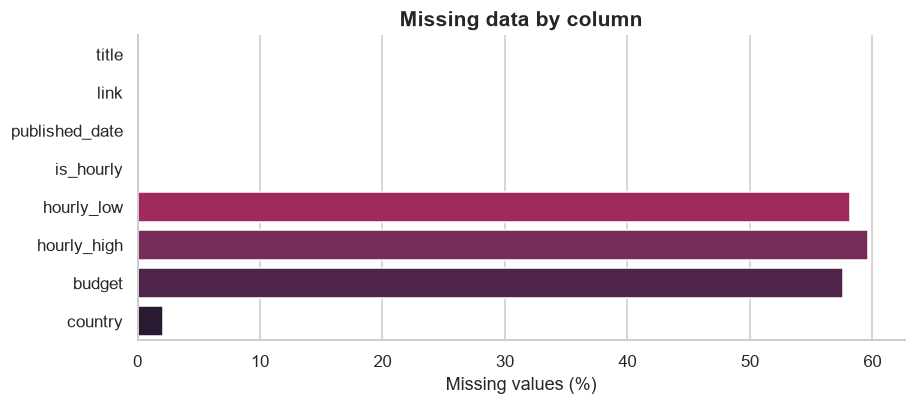

In [ ]:
quality = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(2),
    "unique_values": raw.nunique(),
})
display(quality)
print(f"Fully duplicated rows: {raw.duplicated().sum():,}")

fig, ax = plt.subplots(figsize=(9, 3.6))
sns.barplot(x=quality["missing_%"], y=quality.index, palette="rocket_r", ax=ax)
ax.set_xlabel("Missing values (%)"); ax.set_ylabel("")
ax.set_title("Missing data by column")
show_fig(fig, "00_missing_values")

Preprocessing

In [ ]:
#Standardising column names

def norm(c):
    return re.sub(r"[^a-z0-9]+", "_", str(c).strip().lower()).strip("_")

raw.columns = [norm(c) for c in raw.columns]
rename = {norm(src): canon for canon, src in COLS.items() if src}
absent = [s for s in rename if s not in raw.columns]
if absent:
    print("Columns from COLS not found in the file:", absent)
    print("Columns available:", list(raw.columns))
df = raw.rename(columns=rename).copy()
for need in ("title", "date"):
    assert need in df.columns, f"Required column '{need}' missing - fix COLS in the configuration cell."
print("Canonical columns present:", [c for c in COLS if c in df.columns])
steps = {"rows_loaded": len(df)}

Canonical columns present: ['title', 'date', 'is_hourly', 'hourly_low', 'hourly_high', 'budget', 'country']


### 3.2 Clean job titles
Lower-case, strip punctuation/emoji (keeps `c++`, `c#`), collapse spaces.

In [ ]:
df["title_raw"] = df["title"].astype(str)
t = (df["title_raw"].str.lower()
       .str.replace(r"[^a-z0-9+# ]+", " ", regex=True)
       .str.replace(r"\s+", " ", regex=True).str.strip())
df["title_clean"] = t.replace({"": np.nan, "nan": np.nan, "none": np.nan})
before = len(df)
df = df.dropna(subset=["title_clean"])
steps["dropped_missing_title"] = before - len(df)
df[["title_raw", "title_clean"]].sample(5, random_state=SEED)

,title_raw,title_clean
157943,Landscape architect for residential property i...,landscape architect for residential property i...
138523,Product Photo Editing - Changing Color,product photo editing changing color
117,Develop 1 simple android games on Libgdx / God...,develop 1 simple android games on libgdx godot...
193628,Solnet - Solana's .NET SDK and integration lib...,solnet solana s net sdk and integration librar...
69480,Are you a good Georgian to English subtitler? ...,are you a good georgian to english subtitler n...


Parse data

In [ ]:
try:
    parsed = pd.to_datetime(df["date"], errors="coerce", format="mixed", utc=True)
except (ValueError, TypeError):
    parsed = pd.to_datetime(df["date"], errors="coerce", utc=True)
df["date"] = parsed.dt.tz_localize(None)
before = len(df)
df = df.dropna(subset=["date"])
steps["dropped_bad_date"] = before - len(df)
df["day"] = df["date"].dt.normalize()
span = (df["date"].max() - df["date"].min()).days
print(f"Date range: {df['date'].min():%Y-%m-%d} -> {df['date'].max():%Y-%m-%d}  ({span} days)")

Date range: 2023-11-02 -> 2024-03-24  (143 days)


### 3.4 Pay columns → one numeric value per posting
Hourly postings use the midpoint of `hourly_low`/`hourly_high`; fixed-price postings use `budget`. The two are different units, so they are labelled with a **basis** and never mixed.

In [ ]:
def to_number(s):
    """'$1,250' -> 1250.0"""
    if s.dtype.kind in "if":
        return s.astype(float)
    cleaned = s.astype(str).str.replace(r"[^0-9.\-]", "", regex=True).replace({"": np.nan, "-": np.nan})
    return pd.to_numeric(cleaned, errors="coerce")

for c in ("hourly_low", "hourly_high", "budget"):
    df[c] = to_number(df[c]) if c in df.columns else np.nan
if "is_hourly" in df.columns:
    df["is_hourly"] = (df["is_hourly"].astype(str).str.strip().str.lower()
                       .map({"true": True, "false": False, "1": True, "0": False, "yes": True, "no": False}))

df["hourly_mid"] = df[["hourly_low", "hourly_high"]].mean(axis=1)   # skips NaN
df["salary_value"] = np.nan
df["salary_basis"] = pd.Series(pd.NA, index=df.index, dtype="object")

m = df["hourly_mid"] > 0
df.loc[m, "salary_value"] = df.loc[m, "hourly_mid"]
df.loc[m, "salary_basis"] = "hourly"
m = df["salary_value"].isna() & (df["budget"] > 0)
df.loc[m, "salary_value"] = df.loc[m, "budget"]
df.loc[m, "salary_basis"] = "fixed_price"
df["salary_value"] = df["salary_value"].astype(float)

print(df["salary_basis"].value_counts(dropna=False).rename("postings").to_frame())

              postings
salary_basis          
fixed_price     103872
hourly          102395
<NA>             38506


country, helper features, duplicates

In [ ]:
if "country" in df.columns:
    df["country"] = df["country"].astype(str).str.strip().str.title().replace({"Nan": np.nan, "": np.nan})

df["title_len"] = df["title_clean"].str.len()
df["n_words"] = df["title_clean"].str.split().str.len()
df["weekday"] = df["date"].dt.day_name()

keys = [c for c in ("title_clean", "date", "salary_value", "country") if c in df.columns]
before = len(df)
df = df.drop_duplicates(subset=keys)
steps["dropped_duplicates"] = before - len(df)
print(f"Removed {steps['dropped_duplicates']:,} duplicate postings")

Removed 14 duplicate postings


### 3.6 Flag pay outliers
Values outside the 1st–99th percentile (within each basis) are **flagged**, not deleted — Task 2 does not need pay, so those rows stay available.

In [ ]:
df["pay_outlier"] = False
for b, g in df.groupby("salary_basis"):
    lo, hi = g["salary_value"].quantile([0.01, 0.99])
    df.loc[g.index, "pay_outlier"] = (g["salary_value"] < lo) | (g["salary_value"] > hi)

df = df.reset_index(drop=True)
steps.update({"rows_after_cleaning": len(df), "rows_with_pay": int(df["salary_value"].notna().sum()),
              "pay_outliers_flagged": int(df["pay_outlier"].sum())})
display(pd.Series(steps, name="count").to_frame())
df.to_csv(OUTPUT_DIR / "jobs_clean.csv", index=False)
df.head()

,count
rows_loaded,244828
dropped_missing_title,55
dropped_bad_date,0
dropped_duplicates,14
rows_after_cleaning,244759
rows_with_pay,206257
pay_outliers_flagged,2572


,title,link,date,is_hourly,hourly_low,hourly_high,budget,country,title_raw,title_clean,day,hourly_mid,salary_value,salary_basis,title_len,n_words,weekday,pay_outlier
0,Experienced Media Buyer For Solar Pannel and R...,https://www.upwork.com/jobs/Experienced-Media-...,2024-02-17 09:09:54,False,NaN,NaN,500.00,NaN,Experienced Media Buyer For Solar Pannel and R...,experienced media buyer for solar pannel and r...,2024-02-17,NaN,500.00,fixed_price,75,10,Saturday,False
1,Full Stack Developer,https://www.upwork.com/jobs/Full-Stack-Develop...,2024-02-17 09:09:17,False,NaN,NaN,"1,100.00",United States,Full Stack Developer,full stack developer,2024-02-17,NaN,"1,100.00",fixed_price,20,3,Saturday,False
2,SMMA Bubble App,https://www.upwork.com/jobs/SMMA-Bubble-App_%7...,2024-02-17 09:08:46,True,10.00,30.00,NaN,United States,SMMA Bubble App,smma bubble app,2024-02-17,20.00,20.00,hourly,15,3,Saturday,False
3,Talent Hunter Specialized in Marketing,https://www.upwork.com/jobs/Talent-Hunter-Spec...,2024-02-17 09:08:08,True,NaN,NaN,NaN,United States,Talent Hunter Specialized in Marketing,talent hunter specialized in marketing,2024-02-17,NaN,NaN,<NA>,38,5,Saturday,False
4,Data Engineer,https://www.upwork.com/jobs/Data-Engineer_%7E0...,2024-02-17 09:07:42,False,NaN,NaN,650.00,India,Data Engineer,data engineer,2024-02-17,NaN,650.00,fixed_price,13,2,Saturday,False


EDA

In [ ]:
#overview
overview = {
    "Postings": f"{len(df):,}",
    "Date range": f"{df['date'].min():%Y-%m-%d} -> {df['date'].max():%Y-%m-%d}",
    "Postings with pay info": f"{df['salary_value'].notna().mean():.1%}",
    "Hourly postings": f"{(df['salary_basis'] == 'hourly').sum():,}",
    "Fixed-price postings": f"{(df['salary_basis'] == 'fixed_price').sum():,}",
    "Countries": f"{df['country'].nunique():,}" if "country" in df else "n/a",
    "Unique titles": f"{df['title_clean'].nunique():,}",
}
pd.Series(overview, name="value").to_frame()

,value
Postings,"244,759"
Date range,2023-11-02 -> 2024-03-24
Postings with pay info,84.3%
Hourly postings,"102,391"
Fixed-price postings,"103,866"
Countries,212
Unique titles,"200,122"


### 4.2 Posting activity over time

In [ ]:
# Convert day column into datetime format
df["day"] = pd.to_datetime(df["day"], errors="coerce")

# Create weekday column
df["weekday"] = df["day"].dt.day_name()

# Remove rows with invalid dates
df = df.dropna(subset=["day"])

# Sort data by date
df = df.sort_values("day")

print(df[["day", "weekday"]].head())

              day    weekday
214980 2023-11-02   Thursday
41688  2023-12-02   Saturday
69404  2023-12-05    Tuesday
188270 2023-12-11     Monday
6612   2023-12-13  Wednesday


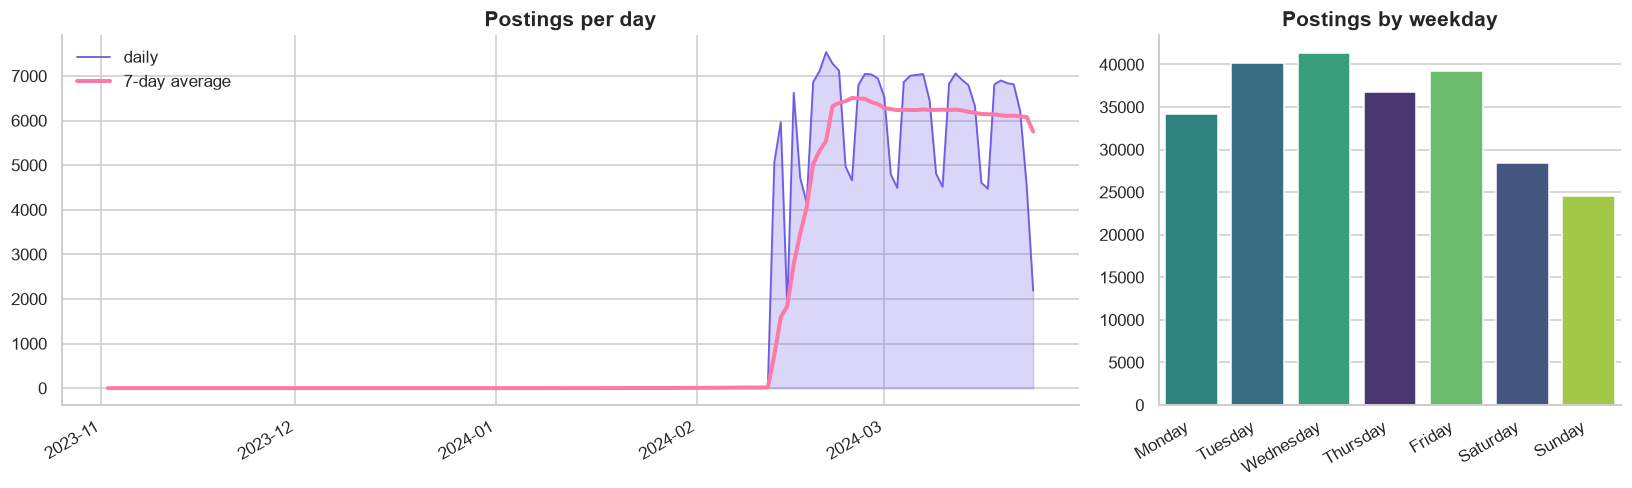

In [ ]:
daily = df.groupby("day").size()

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 4.6),
    gridspec_kw={"width_ratios": [2.2, 1]}
)

# Daily postings
axes[0].fill_between(
    daily.index, daily.values,
    color=PALETTE[0], alpha=.25
)

axes[0].plot(
    daily.index, daily.values,
    color=PALETTE[0], lw=1.2,
    label="daily"
)

axes[0].plot(
    daily.index,
    daily.rolling(7, min_periods=1).mean(),
    color=PALETTE[2], lw=2.6,
    label="7-day average"
)

axes[0].set_title("Postings per day")
axes[0].legend(frameon=False)

# Weekday postings
order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

sns.countplot(
    data=df,
    x="weekday",
    order=order,
    hue="weekday",
    palette="viridis",
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Postings by weekday")
axes[1].set_xlabel("")
axes[1].set_ylabel("")

plt.setp(
    axes[1].get_xticklabels(),
    rotation=40,
    ha="right"
)

fig.autofmt_xdate()
fig.tight_layout()

show_fig(fig, "01_posting_activity")

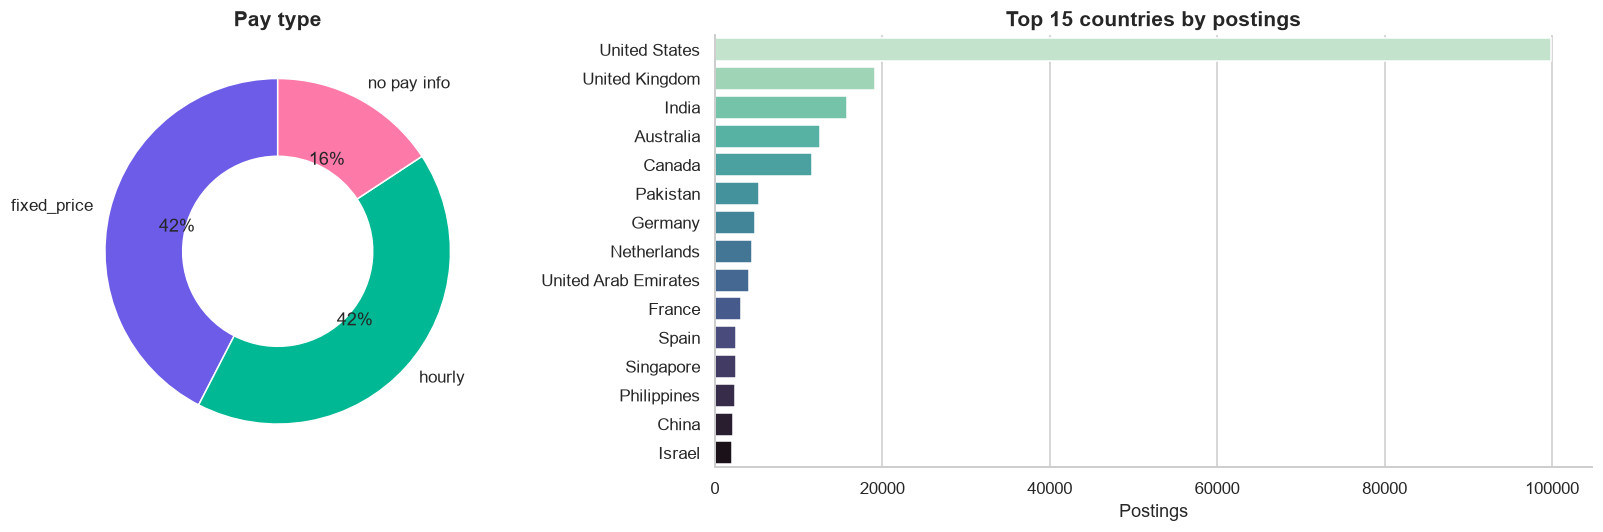

In [ ]:
#### 4.3 Pay type and top countries

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.8]})
basis_counts = df["salary_basis"].fillna("no pay info").value_counts()
axes[0].pie(basis_counts, labels=basis_counts.index, autopct="%1.0f%%", startangle=90,
            colors=PALETTE[:len(basis_counts)], wedgeprops=dict(width=.45, edgecolor="white"))
axes[0].set_title("Pay type")
if "country" in df.columns:
    top_c = df["country"].value_counts().head(15)
    sns.barplot(x=top_c.values, y=top_c.index, palette="mako_r", ax=axes[1])
    axes[1].set_title("Top 15 countries by postings"); axes[1].set_xlabel("Postings"); axes[1].set_ylabel("")
fig.tight_layout()
show_fig(fig, "02_paytype_countries")

### 4.4 Pay distributions
Log scale because pay is strongly right-skewed (1st–99th percentile shown).

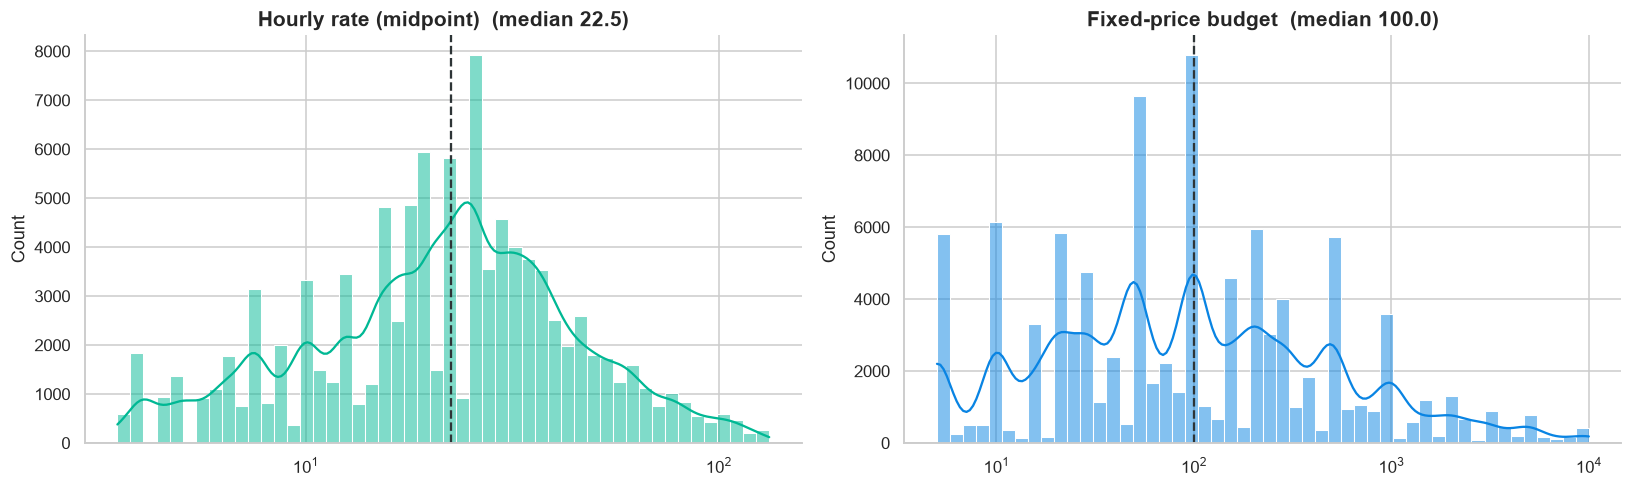

,count,mean,std,min,25%,50%,75%,95%,max
salary_basis,,,,,,,,,
fixed_price,"103,866.00",911.60,"15,731.63",5.00,25.00,100.00,300.00,"2,000.00","1,000,000.00"
hourly,"102,391.00",29.17,30.50,3.00,12.50,22.50,35.00,75.00,998.50


In [ ]:
panels = [("hourly", "Hourly rate (midpoint)", PALETTE[1]), ("fixed_price", "Fixed-price budget", PALETTE[3])]
panels = [p for p in panels if (df["salary_basis"] == p[0]).sum() > 20]
fig, axes = plt.subplots(1, max(1, len(panels)), figsize=(7.5 * max(1, len(panels)), 4.6), squeeze=False)
for ax, (b, label, col) in zip(axes[0], panels):
    v = df.loc[(df["salary_basis"] == b) & ~df["pay_outlier"], "salary_value"]
    sns.histplot(v, bins=50, kde=True, log_scale=True, color=col, ax=ax)
    ax.axvline(v.median(), color="#2d3436", ls="--"); ax.set_title(f"{label}  (median {v.median():,.1f})")
    ax.set_xlabel("")
fig.tight_layout()
show_fig(fig, "03_pay_distributions")
display(df.groupby("salary_basis")["salary_value"].describe(percentiles=[.25, .5, .75, .95]))

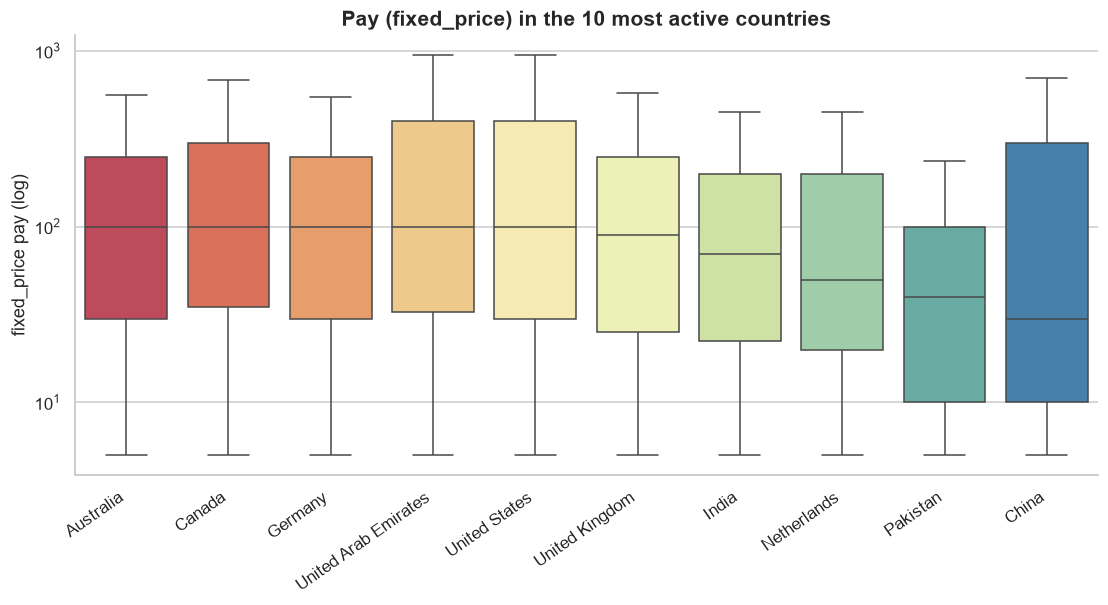

In [ ]:
#Pay by country

if "country" in df.columns and df["salary_basis"].notna().any():
    main_basis = df["salary_basis"].value_counts().idxmax()
    sub = df[(df["salary_basis"] == main_basis) & ~df["pay_outlier"]]
    top10 = sub["country"].value_counts().head(10).index
    order = sub[sub["country"].isin(top10)].groupby("country")["salary_value"].median().sort_values(ascending=False).index
    fig, ax = plt.subplots(figsize=(12, 5.2))
    sns.boxplot(data=sub[sub["country"].isin(top10)], x="country", y="salary_value", order=order,
                palette="Spectral", showfliers=False, ax=ax)
    ax.set_yscale("log"); ax.set_xlabel(""); ax.set_ylabel(f"{main_basis} pay (log)")
    ax.set_title(f"Pay ({main_basis}) in the 10 most active countries")
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
    show_fig(fig, "04_pay_by_country")

In [ ]:
# Check whether title column exists
print(df.columns.tolist())

# Calculate number of words in each title
df["n_words"] = (
    df["title"].fillna("").astype(str).str.split().str.len()
)

# Clean job titles
df["title_clean"] = (
    df["title"]
    .fillna("")
    .astype(str)
    .str.lower()
    .str.replace(r"[^a-zA-Z\s]", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print(df[["title", "n_words", "title_clean"]].head())

['title', 'link', 'date', 'is_hourly', 'hourly_low', 'hourly_high', 'budget', 'country', 'title_raw', 'title_clean', 'day', 'hourly_mid', 'salary_value', 'salary_basis', 'title_len', 'n_words', 'weekday', 'pay_outlier']
                                                    title  n_words  \
214980                  Senior .NET Architect (Team Lead)        5   
41688              Video editor for eCommerce ads needed.        6   
69404   URGENTLY HIRING!! Inside Sales Agents for a lo...       13   
188270                      Swedish Content writer needed        4   
6612            Recruiter (Full Time/Permanent/Long Term)        4   

                                              title_clean  
214980                     senior net architect team lead  
41688               video editor for ecommerce ads needed  
69404   urgently hiring inside sales agents for a long...  
188270                      swedish content writer needed  
6612              recruiter full time permanent long term  

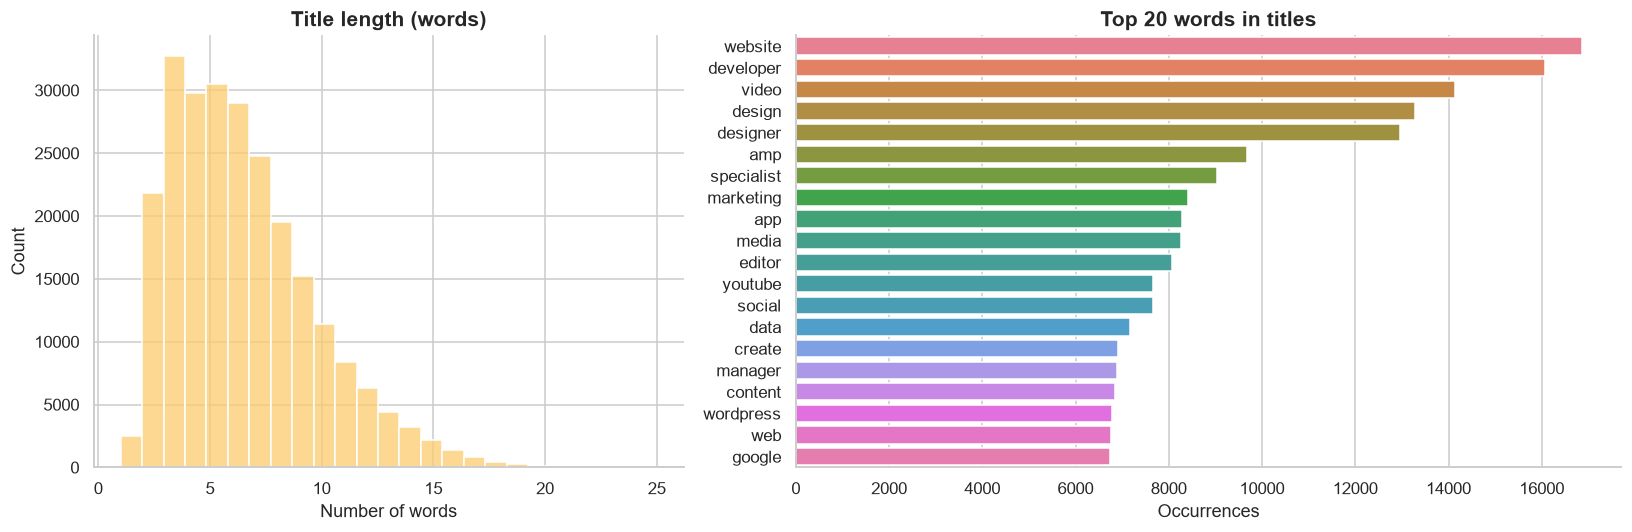

In [ ]:
#What do titles look like

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5),
    gridspec_kw={"width_ratios": [1, 1.4]}
)

# Title length distribution
sns.histplot(
    df["n_words"].clip(upper=25),
    bins=25,
    color=PALETTE[4],
    ax=axes[0]
)

axes[0].set_title("Title length (words)")
axes[0].set_xlabel("Number of words")

# Most frequent words in titles
cv = CountVectorizer(
    stop_words=STOP,
    token_pattern=TOKEN_PATTERN,
    max_features=3000
)

Xw = cv.fit_transform(df["title_clean"])

freq = pd.Series(
    np.asarray(Xw.sum(axis=0)).ravel(),
    index=cv.get_feature_names_out()
).nlargest(20)

sns.barplot(
    x=freq.values,
    y=freq.index,
    hue=freq.index,
    palette="husl",
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Top 20 words in titles")
axes[1].set_xlabel("Occurrences")
axes[1].set_ylabel("")

fig.tight_layout()

show_fig(fig, "05_title_words")

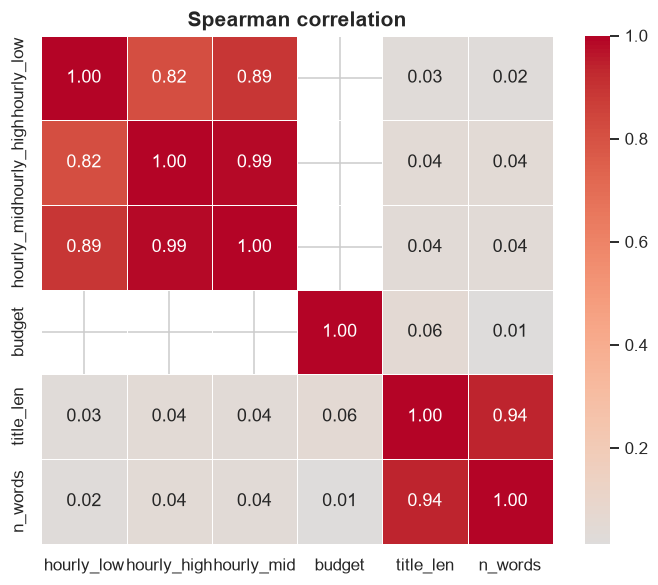

In [ ]:
# Correlations between numeric fields

num = df[["hourly_low", "hourly_high", "hourly_mid", "budget", "title_len", "n_words"]].dropna(axis=1, how="all")
corr = num.corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=.5, ax=ax)
ax.set_title("Spearman correlation")
show_fig(fig, "06_correlation")

## 5. Task 1 — Correlation between job-title keywords and offered pay

**Goal:** find which title keywords go with higher or lower pay.

**Method**
1. Convert titles to binary keyword features (single words and two-word phrases).
2. For every keyword compare log-pay of postings *with* vs *without* it — Mann-Whitney U test, Benjamini-Hochberg FDR correction (many keywords are tested at once), point-biserial correlation, rank-biserial effect size, and the % premium.
3. Fit a Ridge regression on all keywords together for *adjusted* premiums and a cross-validated R².

> Pay units are never mixed: the analysis runs on one basis (hourly **or** fixed-price).

In [ ]:
#### 5.1 Select the pay basis and build keyword features

t1 = df.dropna(subset=["title_clean", "salary_value"]).copy()
basis = t1["salary_basis"].value_counts().idxmax() if SALARY_BASIS == "auto" else SALARY_BASIS
t1 = t1[t1["salary_basis"] == basis]
n_before = len(t1)
t1 = t1[~t1["pay_outlier"]].reset_index(drop=True)
t1["log_pay"] = np.log(t1["salary_value"])
print(f"Basis: {basis} | postings: {len(t1):,} (removed {n_before - len(t1):,} outliers) | median pay: {t1['salary_value'].median():,.2f}")

vec = CountVectorizer(ngram_range=(1, 2), min_df=MIN_DOCS, binary=True,
                      stop_words=STOP, token_pattern=TOKEN_PATTERN)
X = vec.fit_transform(t1["title_clean"])
terms = vec.get_feature_names_out()
y_log, pay = t1["log_pay"].values, t1["salary_value"].values
print(f"Candidate keywords (appear in >= {MIN_DOCS} postings): {len(terms):,}")

Basis: fixed_price | postings: 103,199 (removed 667 outliers) | median pay: 100.00


Candidate keywords (appear in >= 30 postings): 2,832


In [ ]:
# ### 5.2 Keyword-level statistics

def bh_fdr(p):
    """Benjamini-Hochberg adjusted p-values (q-values)."""
    p = np.asarray(p, float); n = len(p)
    order = np.argsort(p)
    ranked = np.minimum.accumulate((p[order] * n / np.arange(1, n + 1))[::-1])[::-1]
    q = np.empty(n); q[order] = np.minimum(ranked, 1)
    return q

Xc = X.tocsc(); n_rows = X.shape[0]
rows = []
for j, term in enumerate(terms):
    idx = Xc.indices[Xc.indptr[j]:Xc.indptr[j + 1]]
    n_with = len(idx)
    if n_with < MIN_DOCS or (n_rows - n_with) < MIN_DOCS:
        continue
    mask = np.zeros(n_rows, dtype=bool); mask[idx] = True
    a, b = y_log[mask], y_log[~mask]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided", method="asymptotic")
    rows.append({
        "keyword": term, "n_postings": n_with,
        "median_with": np.median(pay[mask]), "median_without": np.median(pay[~mask]),
        "premium_pct": (np.exp(a.mean() - b.mean()) - 1) * 100,       # geometric-mean premium
        "corr_point_biserial": np.corrcoef(mask.astype(float), y_log)[0, 1],
        "rank_biserial": 2 * u / (len(a) * len(b)) - 1,
        "p_value": p,
    })
kw = pd.DataFrame(rows)
kw["q_value"] = bh_fdr(kw["p_value"])
kw["significant"] = kw["q_value"] < ALPHA
kw["direction"] = np.where(~kw["significant"], "Not significant", np.where(kw["premium_pct"] > 0, "Premium", "Discount"))
kw = kw.sort_values("premium_pct", ascending=False).reset_index(drop=True)
print(f"Keywords tested: {len(kw):,} | significant after FDR (q < {ALPHA}): {int(kw['significant'].sum()):,}")
kw.head(10)

Keywords tested: 2,832 | significant after FDR (q < 0.05): 1,476


,keyword,n_postings,median_with,median_without,premium_pct,corr_point_biserial,rank_biserial,p_value,q_value,significant,direction
0,closers,50,"5,000.00",100.00,"3,577.85",0.05,0.92,0.00,0.00,True,Premium
1,metaverse,34,"4,550.00",100.00,"3,263.29",0.04,0.86,0.00,0.00,True,Premium
2,term assistant,41,"3,050.00",100.00,"3,016.33",0.04,0.94,0.00,0.00,True,Premium
3,iphone application,42,"3,000.00",100.00,"2,463.35",0.04,0.92,0.00,0.00,True,Premium
4,application problem,41,"3,000.00",100.00,"2,447.98",0.04,0.92,0.00,0.00,True,Premium
5,app sign,35,"3,000.00",100.00,"2,332.83",0.04,0.92,0.00,0.00,True,Premium
6,high ticket,106,"2,000.00",100.00,"1,675.51",0.06,0.74,0.00,0.00,True,Premium
7,english languages,33,"2,000.00",100.00,"1,647.07",0.03,0.77,0.00,0.00,True,Premium
8,sme,43,"3,000.00",100.00,"1,387.64",0.03,0.72,0.00,0.00,True,Premium
9,translation documents,38,"2,250.00",100.00,"1,366.08",0.03,0.70,0.00,0.00,True,Premium


In [ ]:
#### 5.3 Combined (multivariate) model
#Individual keywords overlap (e.g. *senior* and *engineer*). A Ridge regression estimates each keyword's effect while holding the others constant.

freq_cols = np.argsort(np.asarray(X.sum(axis=0)).ravel())[::-1][:RIDGE_FEATURES]
Xr, tr = X[:, freq_cols], np.asarray(terms)[freq_cols]
kf = KFold(5, shuffle=True, random_state=SEED)
cv_scores = {a: cross_val_score(Ridge(alpha=a), Xr, y_log, cv=kf, scoring="r2").mean() for a in RIDGE_ALPHAS}
best_alpha = max(cv_scores, key=cv_scores.get)
ridge = Ridge(alpha=best_alpha).fit(Xr, y_log)
coefs = pd.DataFrame({"keyword": tr, "ridge_coef": ridge.coef_, "adj_premium_pct": (np.exp(ridge.coef_) - 1) * 100})
kw = kw.merge(coefs, on="keyword", how="left")
cv_r2 = cv_scores[best_alpha]
print(f"Cross-validated R² = {cv_r2:.3f}  (alpha = {best_alpha})")
print(f"-> title keywords alone explain about {cv_r2 * 100:.1f}% of the variation in log-pay.")
pd.Series(cv_scores, name="CV R²").rename_axis("ridge alpha").to_frame()

Cross-validated R² = 0.193  (alpha = 10)
-> title keywords alone explain about 19.3% of the variation in log-pay.


,CV R²
ridge alpha,
1,0.19
3,0.19
10,0.19
30,0.19
100,0.18


Charts

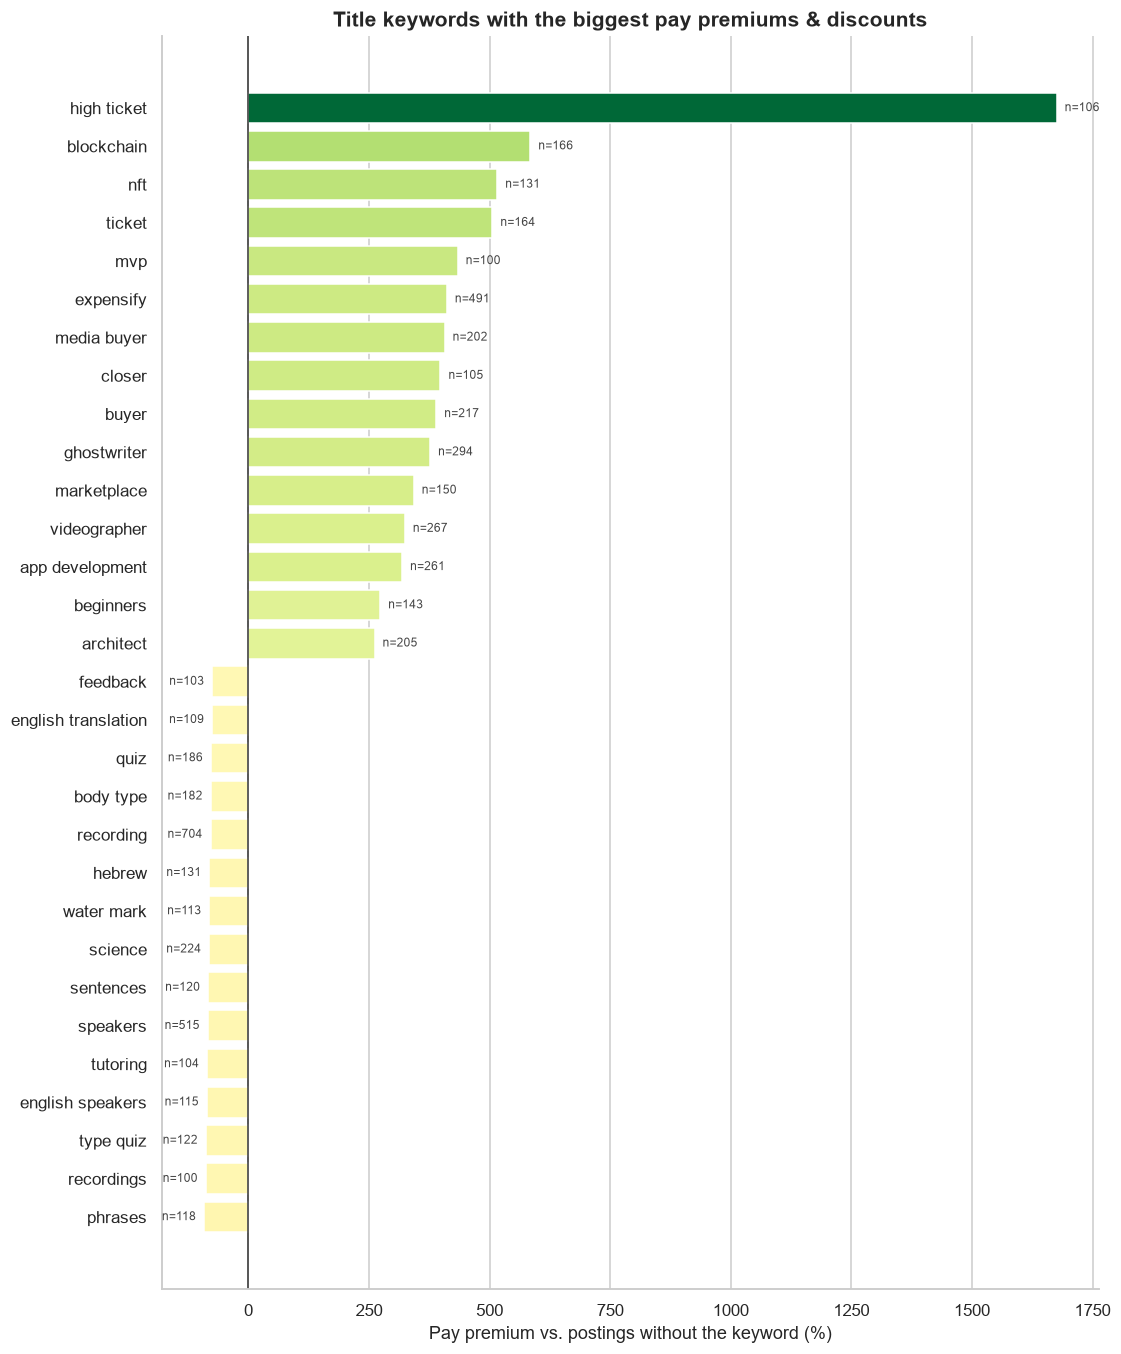

In [ ]:
# --- A. Biggest premiums and discounts (reliable keywords only) ---
pool = kw[kw["significant"] & (kw["n_postings"] >= HEADLINE_DOCS)]
pool = pool if len(pool) >= 4 else kw[kw["significant"]]
top = pd.concat([pool.nlargest(TOP_N, "premium_pct"), pool.nsmallest(TOP_N, "premium_pct")]).drop_duplicates("keyword")
top = top.sort_values("premium_pct")
lim = max(abs(top["premium_pct"]).max(), 1)
colors = plt.get_cmap("RdYlGn")(plt.Normalize(-lim, lim)(top["premium_pct"]))

fig, ax = plt.subplots(figsize=(11, 0.42 * len(top) + 2.2))
ax.barh(top["keyword"], top["premium_pct"], color=colors, edgecolor="white")
for i, (v, n) in enumerate(zip(top["premium_pct"], top["n_postings"])):
    ax.text(v + (lim * .01 if v >= 0 else -lim * .01), i, f"n={n:,}", va="center",
            ha="left" if v >= 0 else "right", fontsize=8, color="#444")
ax.axvline(0, color="#333", lw=1); ax.grid(axis="y", visible=False)
ax.set_xlabel("Pay premium vs. postings without the keyword (%)")
ax.set_title("Title keywords with the biggest pay premiums & discounts")
show_fig(fig, "t1_a_top_keywords")

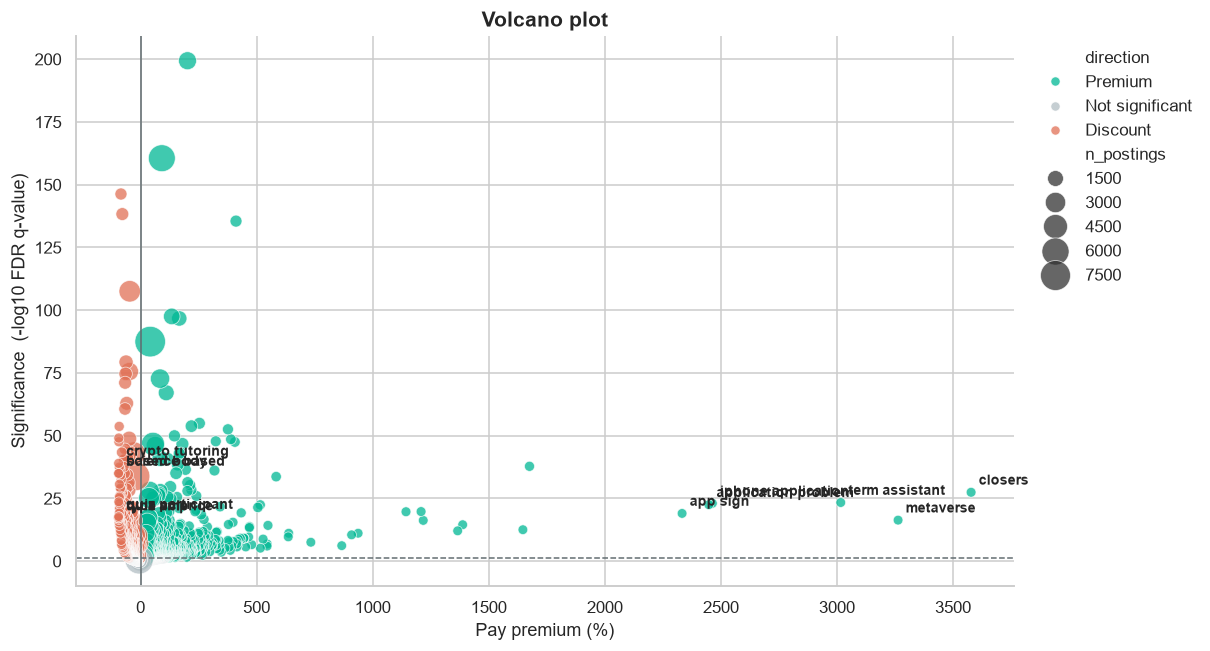

In [ ]:
# --- B. Volcano plot: effect size vs significance ---
v = kw.copy()
v["neglog10_q"] = -np.log10(v["q_value"].clip(lower=1e-300))
pal = {"Premium": "#00B894", "Discount": "#E17055", "Not significant": "#B2BEC3"}
fig, ax = plt.subplots(figsize=(11, 6.5))
sns.scatterplot(data=v, x="premium_pct", y="neglog10_q", hue="direction", palette=pal,
                size="n_postings", sizes=(40, 400), alpha=.75, edgecolor="white", ax=ax)
ax.axhline(-np.log10(ALPHA), ls="--", color="#636e72", lw=1); ax.axvline(0, color="#636e72", lw=1)
for _, r in pd.concat([v.nlargest(6, "premium_pct"), v.nsmallest(6, "premium_pct")]).iterrows():
    ax.annotate(r["keyword"], (r["premium_pct"], r["neglog10_q"]), xytext=(5, 5),
                textcoords="offset points", fontsize=9, fontweight="bold")
ax.set_xlabel("Pay premium (%)"); ax.set_ylabel("Significance  (-log10 FDR q-value)")
ax.set_title("Volcano plot"); ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
show_fig(fig, "t1_b_volcano")

px.scatter(v, x="premium_pct", y="neglog10_q", color="direction", size="n_postings", hover_name="keyword",
           color_discrete_map=pal, labels={"premium_pct": "Pay premium (%)", "neglog10_q": "-log10(q)"},
           hover_data={"median_with": ":,.1f", "median_without": ":,.1f", "n_postings": True, "neglog10_q": False},
           title="Interactive volcano - hover for details").update_layout(template="plotly_white").show()

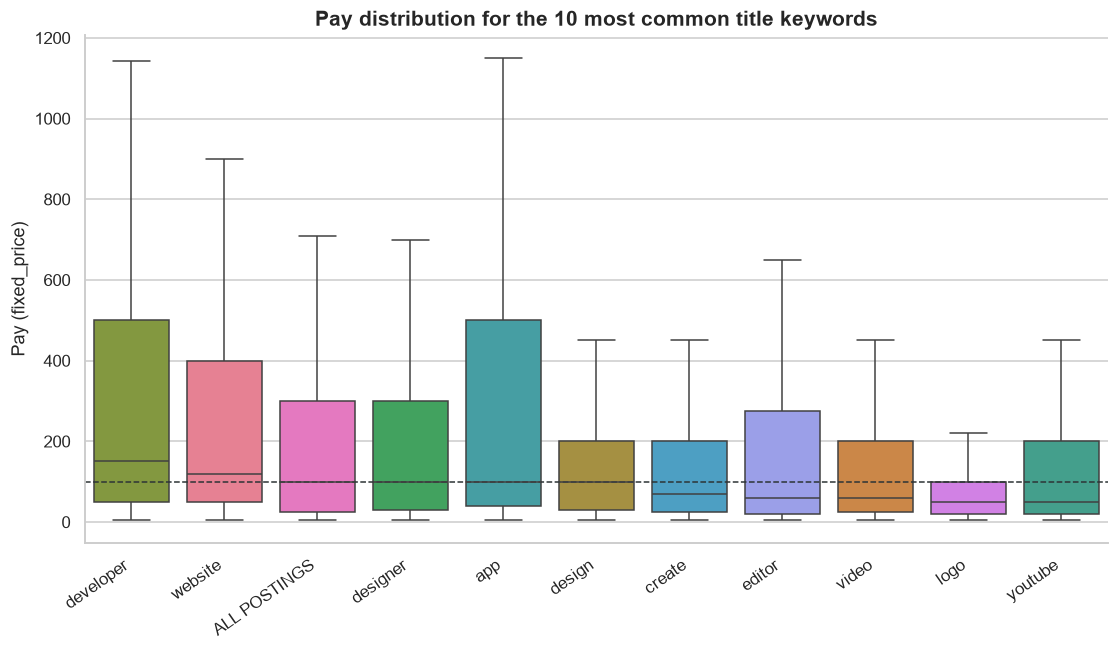

In [ ]:
# --- C. Pay distributions for the 10 most common keywords ---
index_of = {t: i for i, t in enumerate(terms)}
top_common = kw.nlargest(10, "n_postings")["keyword"].tolist()
parts = [pd.DataFrame({"keyword": k, "pay": pay[Xc.indices[Xc.indptr[index_of[k]]:Xc.indptr[index_of[k] + 1]]]})
         for k in top_common]
parts.append(pd.DataFrame({"keyword": "ALL POSTINGS", "pay": pay}))
long = pd.concat(parts)
order = long.groupby("keyword")["pay"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=long, x="keyword", y="pay", order=order, palette="husl", hue="keyword", legend=False,
            showfliers=False, ax=ax)
ax.axhline(np.median(pay), ls="--", color="#2d3436", lw=1)
ax.set_xlabel(""); ax.set_ylabel(f"Pay ({basis})"); ax.set_title("Pay distribution for the 10 most common title keywords")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
show_fig(fig, "t1_c_distributions")

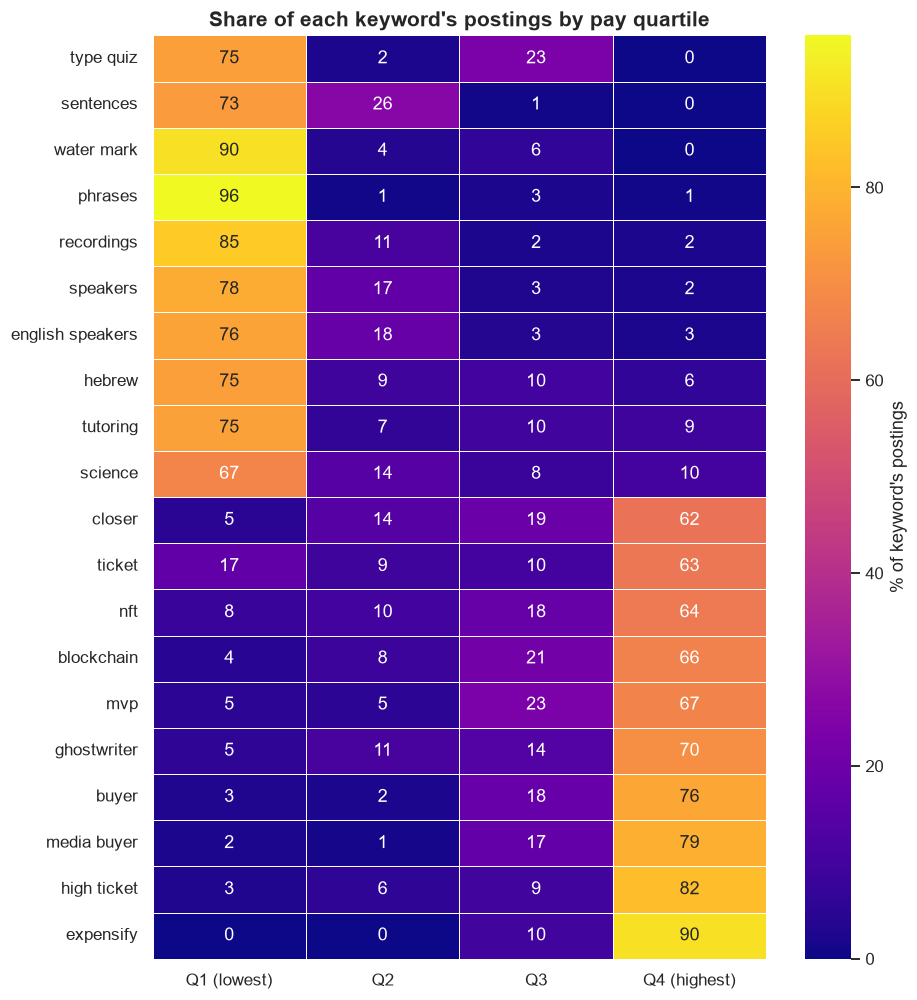

In [ ]:
# --- D. Where do keyword postings fall in the pay range? ---
sel = pd.concat([pool.nlargest(10, "premium_pct"), pool.nsmallest(10, "premium_pct")])["keyword"].drop_duplicates()
qlab = ["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"]
quart = pd.qcut(pd.Series(pay).rank(method="first"), 4, labels=qlab)
mat = {k: quart.iloc[Xc.indices[Xc.indptr[index_of[k]]:Xc.indptr[index_of[k] + 1]]]
          .value_counts(normalize=True).reindex(qlab) * 100 for k in sel}
hm = pd.DataFrame(mat).T.sort_values("Q4 (highest)")
fig, ax = plt.subplots(figsize=(9, 0.42 * len(hm) + 2.5))
sns.heatmap(hm, annot=True, fmt=".0f", cmap="plasma", linewidths=.5, ax=ax, cbar_kws={"label": "% of keyword's postings"})
ax.set_ylabel(""); ax.set_title("Share of each keyword's postings by pay quartile")
show_fig(fig, "t1_d_quartile_heatmap")

# --- E. Popularity vs pay (interactive) ---
lim = max(abs(kw["premium_pct"]).max(), 1)
px.scatter(kw, x="n_postings", y="median_with", size="n_postings", color="premium_pct", hover_name="keyword",
           log_x=True, size_max=45, color_continuous_scale="Turbo", range_color=(-lim, lim),
           labels={"n_postings": "Postings with keyword (log)", "median_with": "Median pay with keyword",
                   "premium_pct": "Premium %"},
           title="Keyword popularity vs. pay (colour = premium)").update_layout(template="plotly_white").show()

In [ ]:
#Results

cols = ["keyword", "n_postings", "median_with", "median_without", "premium_pct", "adj_premium_pct", "q_value"]
print("Strongest single-keyword correlations with pay (point-biserial):")
display(kw.reindex(kw["corr_point_biserial"].abs().sort_values(ascending=False).index)
          .head(8)[["keyword", "n_postings", "corr_point_biserial", "premium_pct"]])
print("\nBiggest PREMIUMS (reliable keywords):")
display(pool.nlargest(10, "premium_pct")[cols])
print("Biggest DISCOUNTS (reliable keywords):")
display(pool.nsmallest(10, "premium_pct")[cols])
kw.to_csv(OUTPUT_DIR / "tables" / "task1_keyword_pay_stats.csv", index=False)

Strongest single-keyword correlations with pay (point-biserial):


,keyword,n_postings,corr_point_biserial,premium_pct
162,development,2172,0.09,202.27
464,developer,5881,0.09,91.72
2791,speakers,515,-0.08,-84.37
2764,recording,704,-0.08,-78.45
2429,logo,3457,-0.07,-46.62
45,expensify,491,0.07,411.22
208,sales,1358,0.07,166.73
289,build,1718,0.07,134.29



Biggest PREMIUMS (reliable keywords):


,keyword,n_postings,median_with,median_without,premium_pct,adj_premium_pct,q_value
6,high ticket,106,"2,000.00",100.00,"1,675.51",205.59,0.00
19,blockchain,166,600.00,100.00,584.18,223.24,0.00
25,nft,131,600.00,100.00,515.66,308.72,0.00
26,ticket,164,"1,000.00",100.00,505.53,31.69,0.00
36,mvp,100,500.00,100.00,433.69,105.41,0.00
45,expensify,491,500.00,100.00,411.22,652.15,0.00
46,media buyer,202,500.00,100.00,406.55,47.85,0.00
48,closer,105,500.00,100.00,397.91,60.20,0.00
50,buyer,217,500.00,100.00,389.18,112.74,0.00
56,ghostwriter,294,750.00,100.00,376.48,204.98,0.00


Biggest DISCOUNTS (reliable keywords):


,keyword,n_postings,median_with,median_without,premium_pct,adj_premium_pct,q_value
2816,phrases,118,5.00,100.00,-91.95,-45.26,0.00
2802,recordings,100,7.00,100.00,-88.40,-60.26,0.00
2801,type quiz,122,5.00,100.00,-88.36,-42.32,0.00
2795,english speakers,115,7.00,100.00,-86.26,42.16,0.00
2792,tutoring,104,5.00,100.00,-85.53,-57.58,0.00
2791,speakers,515,10.00,100.00,-84.37,-57.23,0.00
2788,sentences,120,15.00,100.00,-83.35,-38.37,0.00
2773,science,224,5.00,100.00,-81.08,-63.20,0.00
2772,water mark,113,15.00,100.00,-81.02,-35.63,0.00
2771,hebrew,131,9.00,100.00,-80.93,-49.02,0.00


**How to read this:** a premium of +40% means postings containing the keyword pay about 40% more (geometric mean) than those without it.
The *adjusted* premium removes overlap with the other keywords. Correlation is not causation — keywords proxy for scope, skill level and client type.

## 6. Task 2 — Emerging job categories from posting frequency

**Goal:** find new and fast-growing job categories.

**Method**
1. Give every posting a category (use the dataset's column, or **derive categories by clustering titles**).
2. Count postings per category per period (month / week / day — chosen automatically from the data span) and convert to **market share**, so overall market growth isn't mistaken for category growth.
3. Per category: recent-vs-baseline share growth, Kendall-tau trend test, linear slope, first-seen date.
4. Classify: *Emerging · New entrant · Established & growing · Declining · Stable* and rank by a composite score.

In [ ]:
#Assign categories

t2 = df.copy()
if COLS.get("category") and "category" in t2.columns and t2["category"].notna().mean() >= .5:
    t2["category"] = t2["category"].fillna("Uncategorised")
    cat_source = "dataset column"
else:
    k = min(N_CLUSTERS, max(2, len(t2) // 50))
    tf = TfidfVectorizer(stop_words=STOP, ngram_range=(1, 2), min_df=5, max_features=5000, token_pattern=TOKEN_PATTERN)
    Xt = tf.fit_transform(t2["title_clean"])
    km = MiniBatchKMeans(n_clusters=k, n_init=3, random_state=SEED, batch_size=2048)
    labels = km.fit_predict(Xt)
    vocab = np.array(tf.get_feature_names_out())
    def cluster_name(centre, k_terms=3):
        picked, used = [], set()
        for w in vocab[np.argsort(centre)[::-1][:30]]:
            parts = set(w.split())
            if parts & used:          # skip terms that repeat an already-chosen word
                continue
            picked.append(w.title()); used |= parts
            if len(picked) == k_terms:
                break
        return " / ".join(picked)
    names = {i: cluster_name(c) for i, c in enumerate(km.cluster_centers_)}
    # make duplicate names unique
    seen = {}
    for i in names:
        seen[names[i]] = seen.get(names[i], 0) + 1
        if seen[names[i]] > 1:
            names[i] += f" ({seen[names[i]]})"
    t2["category"] = pd.Series(labels, index=t2.index).map(names)
    cat_source = f"derived from titles (TF-IDF + KMeans, k={k})"
print(f"Category source: {cat_source} | categories: {t2['category'].nunique()}")

preview = (t2.groupby("category")["title_raw"]
             .agg(postings="size", examples=lambda s: " | ".join(s.sample(min(3, len(s)), random_state=SEED).str[:45]))
             .sort_values("postings", ascending=False))
preview.head(25)

Category source: derived from titles (TF-IDF + KMeans, k=25) | categories: 25


,postings,examples
category,,
Specialist / Marketing / Writer,125168,Photos Amendments | Online reputation manageme...
Developer / Stack / Web,12104,"Web Designer, Web Developer, or Front-end Dev ..."
Website / Development / Seo,9224,Website Developer | Website Building and Consu...
Google / Ads / App,7862,Looking for an Excel / Google Sheets expert | ...
Design / Graphic / Interior,7862,Add Text To Adobe Template (design) | Experien...
Video / Editing / Creator,7004,Concept Video Creator | Voice Over Artists For...
Designer / Ui / Ux,6929,Web Designer and UI/UX Specialist | UX/UI Desi...
Social Media / Manager / Marketing,6540,Social Media Manager | Social Media and Email ...
Data / Entry / Analyst,5120,Data Scientist for Sentiment Analysis and Top ...


### 6.2 Choose the time granularity and build category × period counts

In [ ]:
span_days = (t2["date"].max() - t2["date"].min()).days
freq = GRANULARITY if GRANULARITY != "auto" else ("M" if span_days >= 150 else "W" if span_days >= 49 else "D")
label = {"M": "month", "W": "week", "D": "day"}[freq]
print(f"Data span: {span_days} days -> analysing by {label}")

t2["period"] = t2["date"].dt.to_period(freq).dt.start_time

# drop partial first / last periods (they would distort counts)
if freq in ("M", "W"):
    tol = pd.Timedelta(days=3 if freq == "M" else 2)
    p_min, p_max = t2["period"].min(), t2["period"].max()
    p_end = (p_max.to_period(freq)).end_time
    if t2["date"].min() > p_min + tol:
        t2 = t2[t2["period"] > p_min]; print(f"Dropped partial first {label}: {p_min:%Y-%m-%d}")
    if t2["date"].max() < p_end - tol:
        t2 = t2[t2["period"] < p_max]; print(f"Dropped partial last {label}: {p_max:%Y-%m-%d}")

counts = t2.groupby(["period", "category"]).size().unstack(fill_value=0)
full = pd.date_range(counts.index.min(), counts.index.max(), freq={"M": "MS", "W": "W-MON", "D": "D"}[freq])
counts = counts.reindex(full, fill_value=0); counts.index.name = "period"
assert len(counts) >= 6, f"Only {len(counts)} {label}s of data - need at least 6 periods for trend analysis."
total = counts.sum(axis=1)
share = counts.div(total, axis=0) * 100          # % of that period's postings
print(f"{len(counts)} {label}s | {int(counts.values.sum()):,} postings | {counts.shape[1]} categories")
counts.tail()

Data span: 143 days -> analysing by week
Dropped partial first week: 2023-10-30
17 weeks | 244,758 postings | 25 categories


category,Assistant / Virtual / Executive,Data / Entry / Analyst,Design / Graphic / Interior,Designer / Ui / Ux,Developer / Stack / Web,Development / Web / App,English / Translation / Spanish,Estate / Real / Cold,Google / Ads / App,Graphic / Designer / Design,Landing / Book / Page,Logo / Design / Company,Long Term / Editor / Video,Manager / Marketing / Ads,Page / Website / Seo,Research / Market / Product,Shopify / Store / Website,Social Media / Manager / Marketing,Specialist / Marketing / Writer,Video / Editing / Creator,Video Editor / Youtube / Channel,Website / Development / Seo,Website / Wordpress / Design,Wordpress / Site / Developer,Youtube / Channel / Script Writer
period,,,,,,,,,,,,,,,,,,,,,,,,,
2024-02-19,870,1205,1351,1321,2100,768,1086,431,1299,674,553,628,296,709,458,479,785,1181,23542,1211,877,1714,376,822,802
2024-02-26,715,835,1419,1225,2226,703,801,431,1382,633,503,707,317,736,429,450,815,1176,22310,1213,888,1677,350,849,842
2024-03-04,717,815,1377,1241,2242,758,748,442,1385,696,490,723,306,750,442,437,775,1211,22216,1309,949,1643,370,822,842
2024-03-11,715,839,1474,1245,2122,753,741,448,1489,635,498,691,332,733,410,457,808,1176,21691,1298,867,1580,351,839,797
2024-03-18,611,774,1303,1122,1966,703,618,386,1412,663,470,596,260,666,402,426,742,1036,20672,1187,825,1530,321,797,791


In [ ]:
#Growth metrics and classification
n = len(counts)
rec_n = max(1, int(np.ceil(n * RECENT_FRAC)))
base_n = max(1, min(rec_n, n - rec_n))
recent, base = slice(n - rec_n, n), slice(n - rec_n - base_n, n - rec_n)
eps = 0.5 / total.mean() * 100                      # add-half smoothing (in % points)
x = np.arange(n)
new_cut = counts.index[n - rec_n]
print(f"Recent window: last {rec_n} {label}s | baseline: the {base_n} {label}s before that")

rows = []
for cat in counts.columns:
    s, c = share[cat].values, counts[cat].values
    rec_s, base_s = s[recent].mean(), s[base].mean()
    if np.ptp(s) > 0:
        tau, p = stats.kendalltau(x, s); slope = stats.linregress(x, s).slope
    else:
        tau, p, slope = 0.0, 1.0, 0.0
    seen = counts.index[c >= MIN_FIRST_SEEN]
    first = seen.min() if len(seen) else pd.NaT
    rows.append({
        "category": cat, "total_postings": int(c.sum()), "recent_postings": int(c[recent].sum()),
        "recent_share_pct": rec_s, "baseline_share_pct": base_s,
        "share_growth_pct": ((rec_s + eps) / (base_s + eps) - 1) * 100,
        "trend_tau": 0.0 if np.isnan(tau) else tau, "trend_p": 1.0 if np.isnan(p) else p,
        "slope_pp_per_period": slope, "first_seen": first,
        "is_new": bool(pd.notna(first) and first >= new_cut and n > rec_n + base_n),
    })
met = pd.DataFrame(rows)

def classify(r):
    enough = r["recent_postings"] >= MIN_RECENT_POSTS
    up = r["trend_tau"] > 0 and r["trend_p"] < ALPHA and r["share_growth_pct"] >= MIN_GROWTH_PCT
    if r["is_new"] and enough:
        return "New entrant"
    if up and enough:
        return "Emerging" if r["recent_share_pct"] <= MAX_SHARE_PCT else "Established & growing"
    if r["trend_tau"] < 0 and r["trend_p"] < ALPHA and r["share_growth_pct"] <= -MIN_GROWTH_PCT and enough:
        return "Declining"
    return "Stable"

met["status"] = met.apply(classify, axis=1)
met["emergence_score"] = (met["share_growth_pct"].rank(pct=True) + met["trend_tau"].rank(pct=True)
                          + np.log1p(met["recent_postings"]).rank(pct=True)) / 3 * 100
met = met.sort_values("emergence_score", ascending=False).reset_index(drop=True)
emerging = met[met["status"].isin(["Emerging", "New entrant"])]
print(met["status"].value_counts().to_dict())
met.head(10)

Recent window: last 5 weeks | baseline: the 5 weeks before that
{'Stable': 13, 'Emerging': 12}


,category,total_postings,recent_postings,recent_share_pct,baseline_share_pct,share_growth_pct,trend_tau,trend_p,slope_pp_per_period,first_seen,is_new,status,emergence_score
0,Wordpress / Site / Developer,4635,4129,1.91,0.54,252.79,0.80,0.00,0.16,2024-02-12,False,Emerging,82.67
1,Website / Development / Seo,9224,8144,3.77,1.49,152.08,0.66,0.00,0.32,2024-02-05,False,Emerging,82.00
2,Design / Graphic / Interior,7862,6924,3.21,1.43,123.78,0.72,0.00,0.27,2024-02-12,False,Emerging,80.00
3,Google / Ads / App,7862,6967,3.23,2.85,13.44,0.69,0.00,0.30,2024-02-05,False,Stable,74.67
4,Youtube / Channel / Script Writer,4575,4074,1.89,1.01,86.12,0.77,0.00,0.17,2024-02-12,False,Emerging,70.67
5,Video Editor / Youtube / Channel,4966,4406,2.04,0.39,413.76,0.46,0.02,-1.80,2024-02-12,False,Emerging,70.67
6,Landing / Book / Page,2835,2514,1.16,0.23,407.43,0.66,0.00,0.09,2024-02-12,False,Emerging,68.00
7,Logo / Design / Company,3805,3345,1.55,0.32,373.29,0.60,0.00,0.13,2024-02-12,False,Emerging,62.67
8,Page / Website / Seo,2427,2141,0.99,0.38,156.20,0.66,0.00,0.08,2024-02-12,False,Emerging,58.00
9,Graphic / Designer / Design,3721,3301,1.53,0.66,130.42,0.64,0.00,0.13,2024-02-12,False,Emerging,57.33


Charts

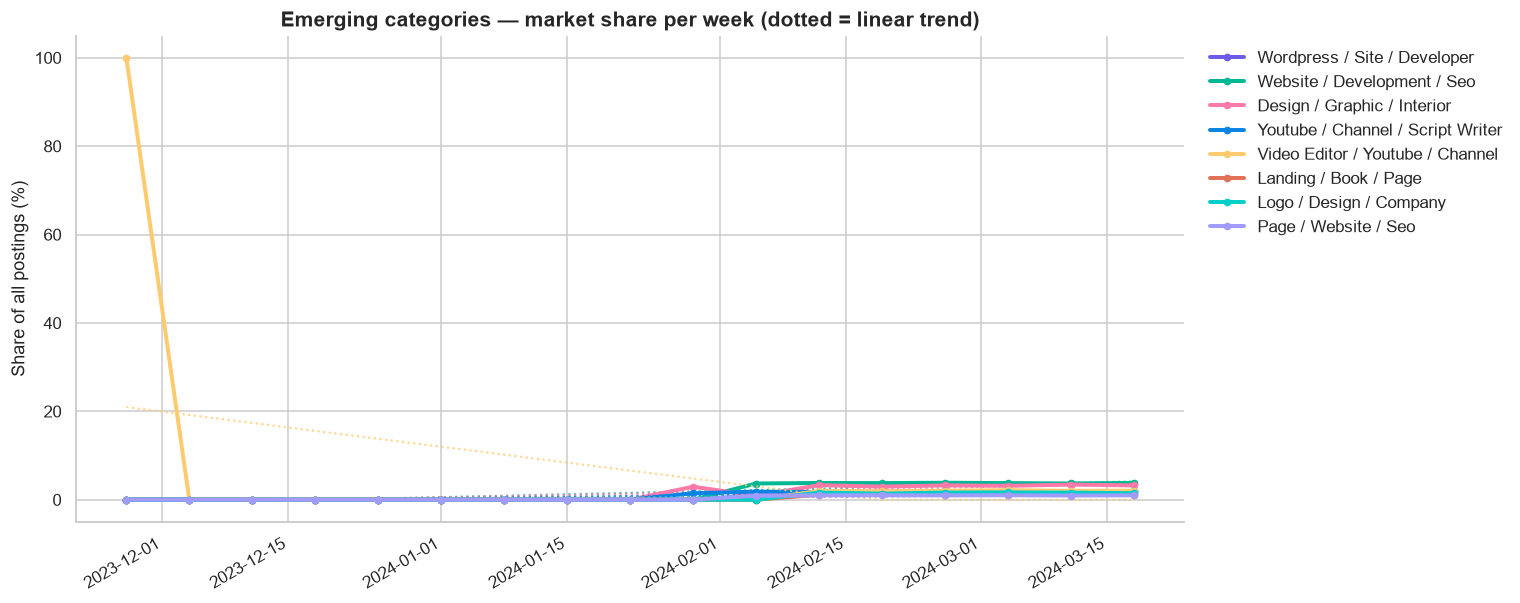

In [ ]:
STATUS_COLORS = {"Emerging": "#00B894", "New entrant": "#6C5CE7", "Established & growing": "#FDCB6E",
                 "Stable": "#B2BEC3", "Declining": "#E17055"}

# --- A. Share over time for top emerging categories ---
top_cats = (emerging if len(emerging) else met).head(TASK2_TOP_N_PLOT)["category"].tolist()
fig, ax = plt.subplots(figsize=(13, 6.5))
for i, cat in enumerate(top_cats):
    col = PALETTE[i % len(PALETTE)]
    ax.plot(share.index, share[cat], marker="o", lw=2.6, ms=4, color=col, label=cat)
    z = np.polyfit(x, share[cat].values, 1)
    ax.plot(share.index, np.clip(np.polyval(z, x), 0, None), ls=":", lw=1.4, color=col, alpha=.8)
ax.set_ylabel("Share of all postings (%)")
ax.set_title(f"Emerging categories — market share per {label} (dotted = linear trend)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False); fig.autofmt_xdate()
show_fig(fig, "t2_a_emerging_trends")

long = share[top_cats].reset_index().melt("period", var_name="category", value_name="share_pct")
px.line(long, x="period", y="share_pct", color="category", markers=True, color_discrete_sequence=PALETTE,
        labels={"share_pct": "Share of postings (%)"},
        title="Emerging categories — interactive (click legend to toggle)").update_layout(template="plotly_white").show()

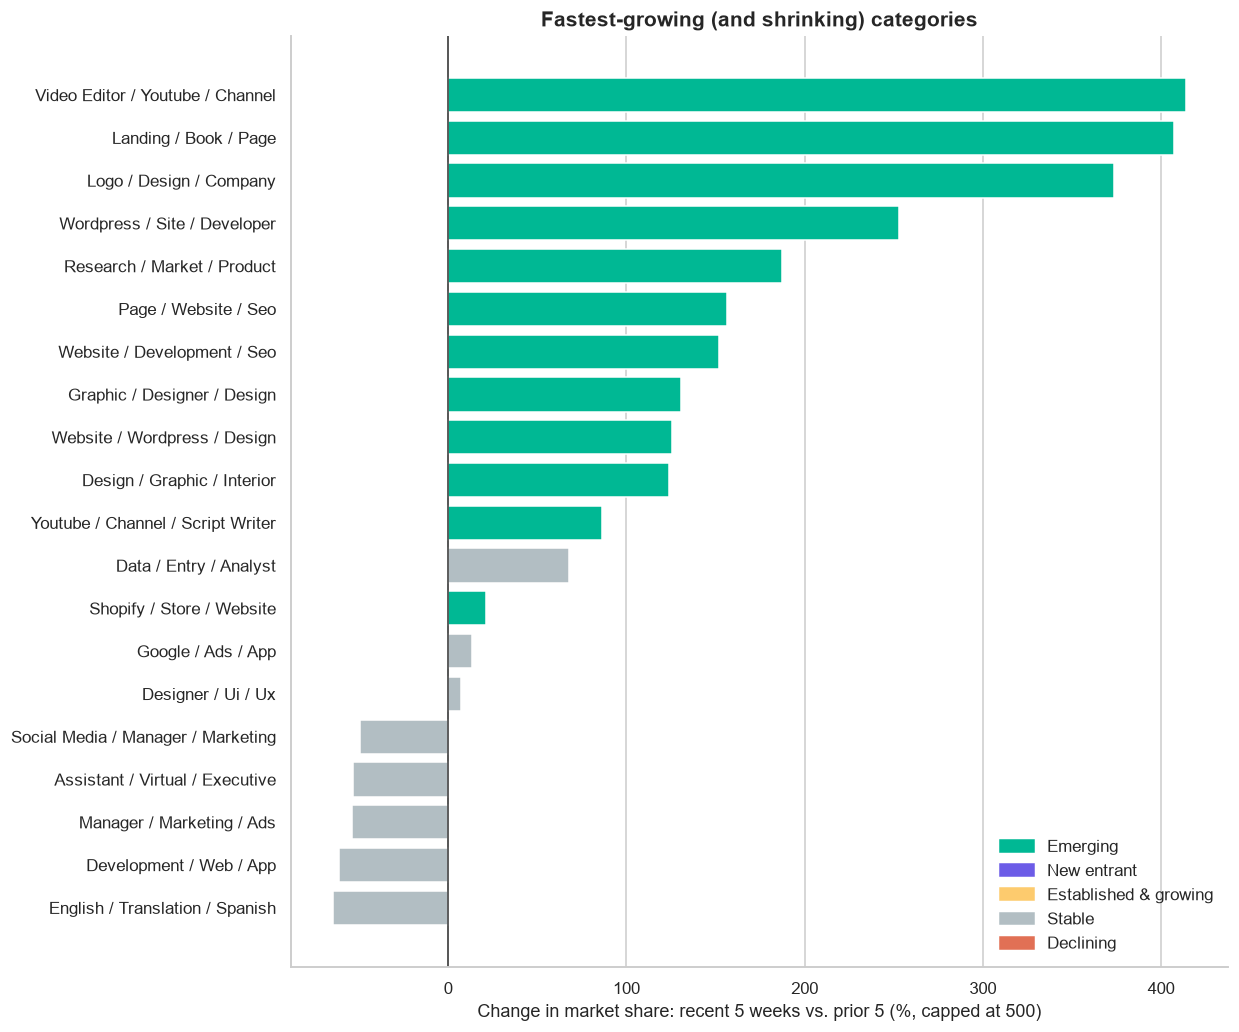

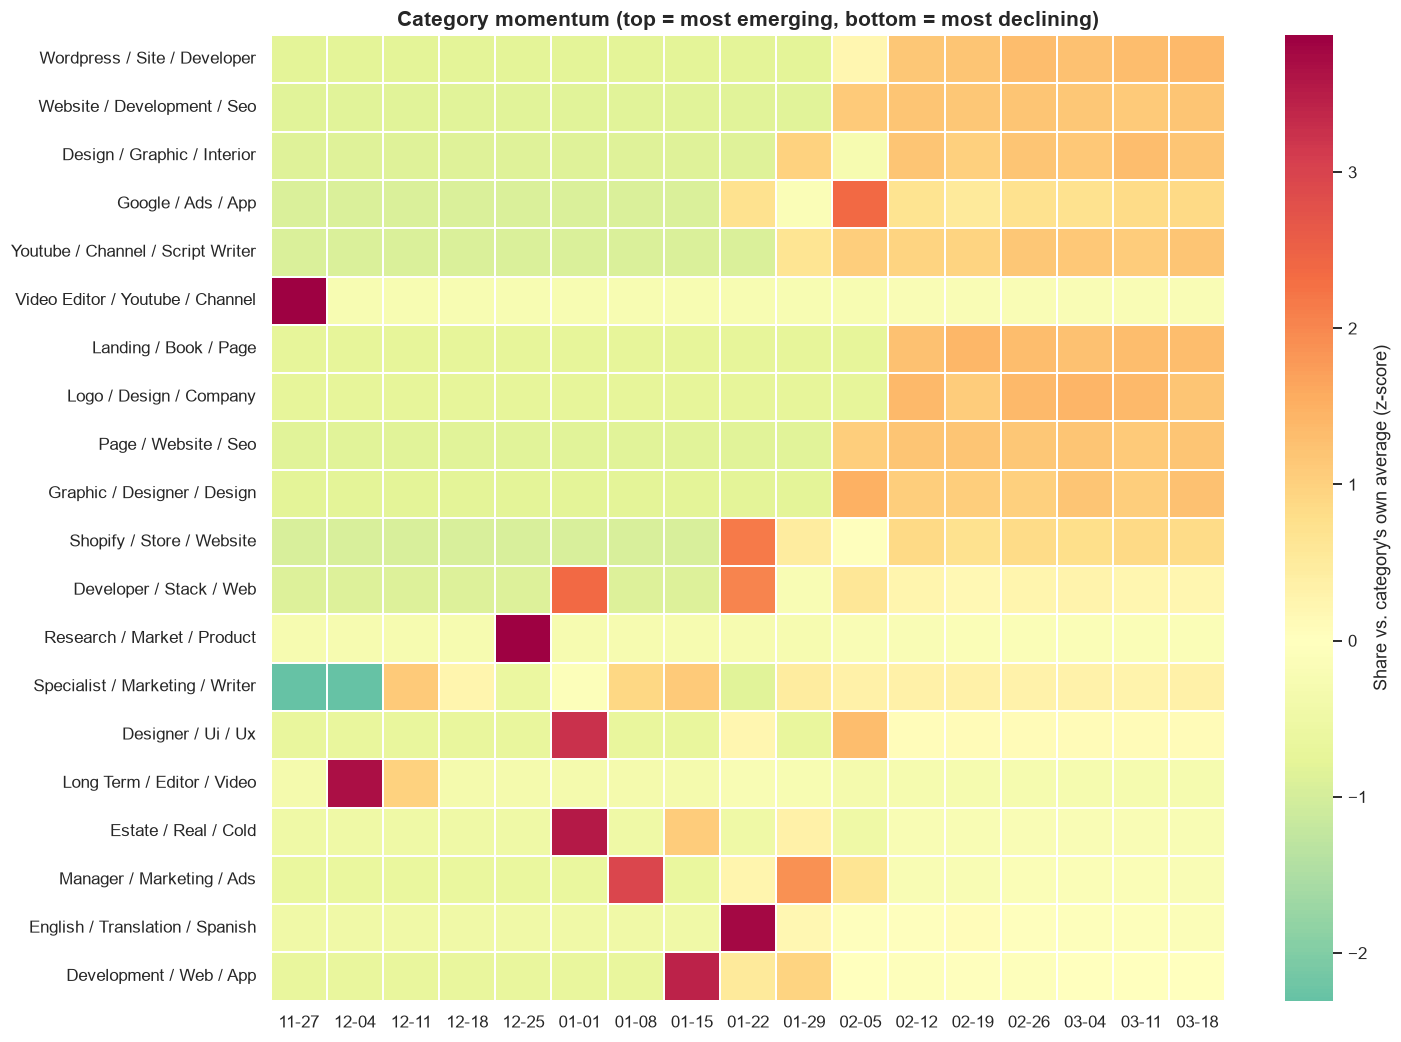

In [ ]:
# --- B. Fastest growing / shrinking ---
d = met[met["recent_postings"] >= MIN_RECENT_POSTS]
d = pd.concat([d.nlargest(15, "share_growth_pct"), d.nsmallest(5, "share_growth_pct")]).drop_duplicates("category")
d = d.sort_values("share_growth_pct")
fig, ax = plt.subplots(figsize=(11, 0.45 * len(d) + 2))
ax.barh(d["category"], d["share_growth_pct"].clip(upper=500), color=d["status"].map(STATUS_COLORS), edgecolor="white")
ax.axvline(0, color="#333", lw=1); ax.grid(axis="y", visible=False)
ax.set_xlabel(f"Change in market share: recent {rec_n} {label}s vs. prior {base_n} (%, capped at 500)")
ax.set_title("Fastest-growing (and shrinking) categories")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in STATUS_COLORS.values()], STATUS_COLORS.keys(),
          loc="lower right", frameon=False)
show_fig(fig, "t2_b_growth_bars")

# --- C. Momentum heatmap ---
cats = pd.concat([met.nlargest(15, "emergence_score"), met.nsmallest(5, "emergence_score")])["category"].unique()
z = share[cats].apply(lambda s: (s - s.mean()) / (s.std() or 1))
z.index = z.index.strftime("%Y-%m" if freq == "M" else "%m-%d")
fig, ax = plt.subplots(figsize=(14, 0.42 * len(cats) + 3))
sns.heatmap(z.T, cmap="Spectral_r", center=0, linewidths=.3, ax=ax,
            cbar_kws={"label": "Share vs. category's own average (z-score)"})
ax.set_title("Category momentum (top = most emerging, bottom = most declining)"); ax.set_xlabel(""); ax.set_ylabel("")
show_fig(fig, "t2_c_momentum_heatmap")

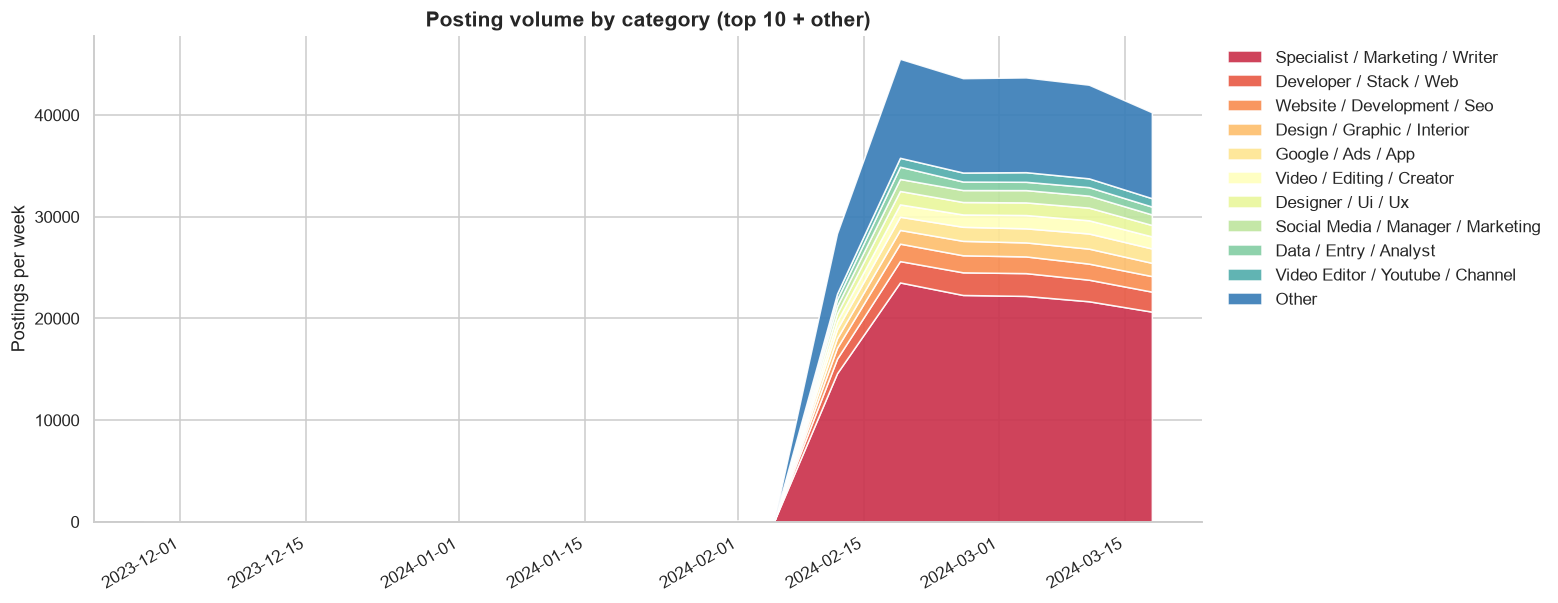

In [ ]:
# --- D. Stacked volume ---
top10 = counts.sum().nlargest(10).index
v = counts[top10].copy(); v["Other"] = counts.drop(columns=top10).sum(axis=1)
fig, ax = plt.subplots(figsize=(13, 6.5))
ax.stackplot(v.index, v.T.values, labels=v.columns, colors=sns.color_palette("Spectral", len(v.columns)), alpha=.92)
ax.set_ylabel(f"Postings per {label}"); ax.set_title("Posting volume by category (top 10 + other)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False); fig.autofmt_xdate()
show_fig(fig, "t2_d_volume_area")

# --- E. Landscape (interactive) ---
met["growth_capped"] = met["share_growth_pct"].clip(-100, 500)
px.scatter(met, x="recent_postings", y="growth_capped", size="recent_share_pct", color="status",
           color_discrete_map=STATUS_COLORS, hover_name="category", log_x=True, size_max=50,
           hover_data={"share_growth_pct": ":.0f", "trend_tau": ":.2f", "recent_share_pct": ":.2f", "growth_capped": False},
           labels={"recent_postings": "Recent postings (log)", "growth_capped": "Share growth % (capped)"},
           title="Category landscape: size vs. growth").update_layout(template="plotly_white").show()

Results- emerging categories

In [ ]:
cols = ["category", "status", "recent_postings", "recent_share_pct", "baseline_share_pct",
        "share_growth_pct", "trend_tau", "first_seen"]
print(f"Period: {counts.index.min():%Y-%m-%d} -> {counts.index.max():%Y-%m-%d} ({len(counts)} {label}s) | categories: {counts.shape[1]}")
print("\nEmerging & new categories:")
display(emerging[cols] if len(emerging) else pd.DataFrame({"note": ["none met the thresholds - lower MIN_GROWTH_PCT / MIN_RECENT_POSTS"]}))
print("Fastest-declining categories:")
display(met[met["status"] == "Declining"].nsmallest(5, "share_growth_pct")[cols])

emerging.to_csv(OUTPUT_DIR / "tables" / "task2_emerging_categories.csv", index=False)
met.to_csv(OUTPUT_DIR / "tables" / "task2_category_metrics.csv", index=False)
counts.reset_index().to_csv(OUTPUT_DIR / "tables" / "task2_period_counts.csv", index=False)

Period: 2023-11-27 -> 2024-03-18 (17 weeks) | categories: 25

Emerging & new categories:


,category,status,recent_postings,recent_share_pct,baseline_share_pct,share_growth_pct,trend_tau,first_seen
0,Wordpress / Site / Developer,Emerging,4129,1.91,0.54,252.79,0.80,2024-02-12
1,Website / Development / Seo,Emerging,8144,3.77,1.49,152.08,0.66,2024-02-05
2,Design / Graphic / Interior,Emerging,6924,3.21,1.43,123.78,0.72,2024-02-12
4,Youtube / Channel / Script Writer,Emerging,4074,1.89,1.01,86.12,0.77,2024-02-12
5,Video Editor / Youtube / Channel,Emerging,4406,2.04,0.39,413.76,0.46,2024-02-12
6,Landing / Book / Page,Emerging,2514,1.16,0.23,407.43,0.66,2024-02-12
7,Logo / Design / Company,Emerging,3345,1.55,0.32,373.29,0.60,2024-02-12
8,Page / Website / Seo,Emerging,2141,0.99,0.38,156.20,0.66,2024-02-12
9,Graphic / Designer / Design,Emerging,3301,1.53,0.66,130.42,0.64,2024-02-12
10,Shopify / Store / Website,Emerging,3925,1.82,1.50,21.05,0.61,2024-02-12


Fastest-declining categories:


,category,status,recent_postings,recent_share_pct,baseline_share_pct,share_growth_pct,trend_tau,first_seen


**Definitions** — *Share growth*: change in a category's share of postings (recent vs. baseline window). *Emerging*: growth ≥ `MIN_GROWTH_PCT`,
significant upward Kendall trend, enough recent postings, share ≤ `MAX_SHARE_PCT`. *New entrant*: first seen only in the recent window.
Derived (clustered) categories are only as meaningful as the clusters — review the category preview in 6.1 and adjust `N_CLUSTERS` if needed.

## 7. Task 3 — Predict high-demand job roles from posting patterns over time

**Goal:** forecast which roles will be most in demand, with accuracy metrics and a visual of demand trends.

**Method**
1. *Roles* = the categories built in Task 2 (the dataset's own category column if it has one, otherwise clusters of similar titles). Demand = postings per role per period.
2. One model for all roles (a "panel" model) learns to predict next-period demand from each role's own recent history: lags, rolling mean/volatility, momentum and slope.
3. Honest evaluation, always forward in time:
   * **one-step holdout** — compare Ridge / Random Forest / Gradient Boosting against two naive baselines;
   * **multi-step backtest** — hide the last *H* periods, forecast them recursively, compare with what really happened;
   * **high-demand classification** — can the model flag the roles that end up in the top quartile of demand?
4. Refit on all data, forecast *H* periods ahead, and rank roles (with approximate 80% prediction bands).

> Requires the Task 2 cells to have been run (they create `counts`, `freq` and `label`).

### 7.1 Parameters and demand series

In [ ]:
# ---- Task 3 parameters
LAGS              = 4      # periods of history used as features
TEST_FRAC         = 0.25   # last 25% of periods = holdout for model comparison
FORECAST_H        = None   # None -> auto (~15% of the history, at least 2 periods)
TOP_K_ROLES       = 10     # roles reported as the high-demand list
HIGH_DEMAND_Q     = 0.75   # 'high demand' = above this quantile of demand within a period
MIN_ROLE_POSTINGS = 30     # ignore roles with fewer postings overall (too noisy to forecast)

role_counts = counts.loc[:, counts.sum() >= MIN_ROLE_POSTINGS]
n_per = len(role_counts)
H = FORECAST_H or max(2, int(round(n_per * 0.15)))
test_n = max(2, int(round(n_per * TEST_FRAC)))
assert n_per >= LAGS + test_n + 4, f"Only {n_per} {label}s of history - not enough to train a forecasting model."
pd_freq = {"M": "MS", "W": "W-MON", "D": "D"}[freq]
log_counts = np.log1p(role_counts)           # model works on log(1 + postings)

print(f"Roles modelled: {role_counts.shape[1]} (of {counts.shape[1]}) | history: {n_per} {label}s")
print(f"Holdout: last {test_n} {label}s | forecast horizon: {H} {label}s")

Roles modelled: 25 (of 25) | history: 17 weeks
Holdout: last 4 weeks | forecast horizon: 3 weeks


### 7.2 Feature engineering
Every feature for period *t* uses only information from periods **before** *t* — no leakage.

In [ ]:
FEATURES = [f"lag_{i}" for i in range(1, LAGS + 1)] + \
           ["roll_mean_3", "roll_std_3", "long_run_mean", "momentum", "last_change", "slope"]

def feat_vec(h):
    """h = 1-D array of log-demand up to the period BEFORE the one being predicted."""
    lags = h[-LAGS:][::-1]                                   # lag_1 (most recent) ... lag_L
    return np.array([*lags,
                     h[-3:].mean(), h[-3:].std(), h.mean(),  # rolling level, volatility, long-run level
                     lags[0] - h[-LAGS:].mean(),             # momentum vs. recent average
                     lags[0] - lags[1],                      # last change
                     np.polyfit(np.arange(LAGS), h[-LAGS:], 1)[0]])   # slope over the lag window

def build_panel(log_df, t_from, t_to):
    """Supervised rows (one per role x target period) for target positions t_from .. t_to-1."""
    X, y, meta = [], [], []
    for role in log_df.columns:
        h = log_df[role].values
        for t in range(max(LAGS, t_from), t_to):
            X.append(feat_vec(h[:t])); y.append(h[t]); meta.append((role, t))
    return np.array(X), np.array(y), pd.DataFrame(meta, columns=["role", "t"])

split = n_per - test_n
Xtr, ytr, mtr = build_panel(log_counts, LAGS, split)
Xte, yte, mte = build_panel(log_counts, split, n_per)
print(f"Training rows: {len(ytr):,} | holdout rows: {len(yte):,} | features: {len(FEATURES)}")
pd.DataFrame(Xtr[:5], columns=FEATURES).round(2)

Training rows: 225 | holdout rows: 100 | features: 10


,lag_1,lag_2,lag_3,lag_4,roll_mean_3,roll_std_3,long_run_mean,momentum,last_change,slope
0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
3,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
4,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


### 7.3 Model comparison on the holdout (one-step-ahead)

In [ ]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import Ridge

In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from scipy import stats
import numpy as np
import pandas as pd

In [ ]:
models = {
    "Ridge (lags)": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingRegressor(max_iter=250, learning_rate=0.05, max_leaf_nodes=8,
                                                       min_samples_leaf=8, l2_regularization=1.0, random_state=SEED),
}
preds = {"Naive (last value)": Xte[:, 0],                               # lag_1
         "Moving avg (3)": Xte[:, FEATURES.index("roll_mean_3")]}
for name, mdl in models.items():
    preds[name] = mdl.fit(Xtr, ytr).predict(Xte)

def evaluate(y_log_true, y_log_pred, meta):
    y_log_pred = np.clip(y_log_pred, 0, None)
    yt, yp = np.expm1(y_log_true), np.expm1(y_log_pred)
    d = meta.assign(actual=yt, pred=yp)
    def top_flag(col):                                       # top quartile of demand within each period
        thr = d.groupby("t")[col].transform(lambda s: s.quantile(HIGH_DEMAND_Q))
        return ((d[col] >= thr) & (d[col] > 0)).astype(int)
    a_hi, p_hi = top_flag("actual"), top_flag("pred")
    rho = [stats.spearmanr(g["actual"], g["pred"])[0] for _, g in d.groupby("t") if g["actual"].nunique() > 1]
    return {"MAE": mean_absolute_error(yt, yp), "RMSE": np.sqrt(mean_squared_error(yt, yp)),
            "WAPE_%": np.abs(yt - yp).sum() / yt.sum() * 100, "R2": r2_score(yt, yp),
            "RMSLE": np.sqrt(mean_squared_error(y_log_true, y_log_pred)),
            "Rank_corr": np.nanmean(rho) if rho else np.nan,
            "HighDemand_Acc": accuracy_score(a_hi, p_hi), "HighDemand_Prec": precision_score(a_hi, p_hi, zero_division=0),
            "HighDemand_Rec": recall_score(a_hi, p_hi, zero_division=0), "HighDemand_F1": f1_score(a_hi, p_hi, zero_division=0)}

res = pd.DataFrame({name: evaluate(yte, p, mte) for name, p in preds.items()}).T
best_name = res.loc[list(models)].sort_values("WAPE_%").index[0]
print(f"Best learned model by WAPE: {best_name}")
res.sort_values("WAPE_%")

Best learned model by WAPE: Gradient Boosting


,MAE,RMSE,WAPE_%,R2,RMSLE,Rank_corr,HighDemand_Acc,HighDemand_Prec,HighDemand_Rec,HighDemand_F1
Naive (last value),78.63,184.61,4.61,1.00,0.08,0.98,1.00,1.00,1.00,1.00
Moving avg (3),488.79,"2,031.61",28.65,0.76,1.03,0.96,0.98,0.96,0.96,0.96
Gradient Boosting,"1,411.57","4,010.32",82.74,0.05,1.02,0.28,0.59,0.37,0.68,0.48
Random Forest,"1,575.74","4,246.15",92.36,-0.07,1.39,0.84,0.86,0.75,0.75,0.75
Ridge (lags),"32,658,165.15","200,426,963.20","1,914,244.82","-2,377,602,406.09",8.10,0.97,0.98,0.96,0.96,0.96


**Metric guide** — *WAPE*: total absolute error ÷ total actual postings (lower is better; weights big roles more). *R²*: share of variance explained. *Rank_corr*: Spearman correlation between predicted and actual role ranking in each period. *HighDemand_\**: accuracy / precision / recall / F1 for flagging the roles in the top quartile of demand.

### 7.4 What drives the predictions? (permutation importance)

In [ ]:
from sklearn.inspection import permutation_importance

In [ ]:
imp = permutation_importance(models[best_name], Xte, yte, n_repeats=15, random_state=SEED,
                             scoring="neg_mean_squared_error")
imp_df = pd.DataFrame({"feature": FEATURES, "importance": imp.importances_mean,
                       "std": imp.importances_std}).sort_values("importance", ascending=False)
imp_df.round(4)

,feature,importance,std
3,lag_4,0.73,0.12
2,lag_3,0.50,0.06
5,roll_std_3,0.17,0.06
9,slope,0.11,0.06
8,last_change,0.03,0.02
0,lag_1,0.00,0.00
1,lag_2,0.00,0.00
4,roll_mean_3,0.00,0.00
6,long_run_mean,0.00,0.00
7,momentum,-0.09,0.03


### 7.5 Multi-step backtest
Pretend we are standing *H* periods ago: train only on the earlier data, forecast the hidden periods recursively (each forecast feeds the next step), then compare with reality. This is the honest test of the final forecast.

In [ ]:
from sklearn.base import clone

In [ ]:
def recursive_forecast(model, log_df, steps):
    """Forecast `steps` periods ahead for every role; each prediction becomes input for the next step."""
    hist = {r: list(log_df[r].values) for r in log_df.columns}
    rows = []
    for _ in range(steps):
        Xs = np.array([feat_vec(np.array(hist[r])) for r in hist])
        p = np.clip(model.predict(Xs), 0, None)
        for r, v in zip(hist, p):
            hist[r].append(float(v))
        rows.append(p)
    return pd.DataFrame(rows, columns=list(hist))

def horizon_metrics(actual, pred):
    yt, yp = actual.values.ravel(), pred.values.ravel()
    tot_a, tot_p = actual.sum(), pred.sum()
    k = max(3, int(round(len(tot_a) * (1 - HIGH_DEMAND_Q))))
    overlap = len(set(tot_a.nlargest(k).index) & set(tot_p.nlargest(k).index)) / k
    return {"MAE": mean_absolute_error(yt, yp), "RMSE": np.sqrt(mean_squared_error(yt, yp)),
            "WAPE_%": np.abs(yt - yp).sum() / yt.sum() * 100, "R2": r2_score(yt, yp),
            "Rank_corr_total": stats.spearmanr(tot_a, tot_p)[0], "TopK_overlap": overlap}

bt_start = n_per - H
if bt_start >= LAGS + 6:
    Xb, yb, _ = build_panel(log_counts.iloc[:bt_start], LAGS, bt_start)
    bt_model = clone(models[best_name]).fit(Xb, yb)
    bt_fc = recursive_forecast(bt_model, log_counts.iloc[:bt_start], H)
    actual_h = role_counts.iloc[bt_start:]
    wrap = lambda arr: pd.DataFrame(arr, index=actual_h.index, columns=role_counts.columns)
    last_log = log_counts.iloc[bt_start - 1].values
    ma_log = log_counts.iloc[bt_start - 3:bt_start].mean().values
    backtest = pd.DataFrame({
        f"{best_name} (recursive)": horizon_metrics(actual_h, wrap(np.expm1(bt_fc.values))),
        "Naive (last value)": horizon_metrics(actual_h, wrap(np.expm1(np.tile(last_log, (H, 1))))),
        "Moving avg (3)": horizon_metrics(actual_h, wrap(np.expm1(np.tile(ma_log, (H, 1))))),
    }).T
    k_bt = max(3, int(round(role_counts.shape[1] * (1 - HIGH_DEMAND_Q))))
    print(f"Backtest: trained up to {role_counts.index[bt_start - 1]:%Y-%m-%d}, forecast the next {H} {label}s "
          f"(TopK_overlap uses K = {k_bt} roles)")
    display(backtest)
else:
    backtest = None
    print("Not enough history for a multi-step backtest - skipped.")

Backtest: trained up to 2024-02-26, forecast the next 3 weeks (TopK_overlap uses K = 6 roles)


,MAE,RMSE,WAPE_%,R2,Rank_corr_total,TopK_overlap
Gradient Boosting (recursive),"1,166.27","3,999.67",68.89,0.04,0.65,0.67
Naive (last value),74.80,212.38,4.42,1.00,0.99,0.83
Moving avg (3),172.63,403.12,10.20,0.99,0.97,0.83


### 7.6 Final forecast
Refit on all history and forecast the next *H* periods. Bands are approximate 80% intervals from the holdout error, widening with the horizon.

In [ ]:
Xall, yall, _ = build_panel(log_counts, LAGS, n_per)
final_model = clone(models[best_name]).fit(Xall, yall)
fc_log = recursive_forecast(final_model, log_counts, H)
future_idx = pd.date_range(role_counts.index[-1], periods=H + 1, freq=pd_freq)[1:]

sigma = np.std(yte - preds[best_name])                       # holdout residual std (log scale)
steps = np.arange(1, H + 1)[:, None]
band = 1.2816 * sigma * np.sqrt(steps)
mk = lambda arr: pd.DataFrame(arr, index=future_idx, columns=role_counts.columns)
fc = mk(np.expm1(fc_log.values))
lo = mk(np.expm1(np.clip(fc_log.values - band, 0, None)))
hi = mk(np.expm1(fc_log.values + band))

summary = pd.DataFrame({"role": role_counts.columns,
                        "recent_avg": role_counts.iloc[-H:].mean().values,
                        "forecast_avg": fc.mean().values,
                        "forecast_total": fc.sum().values})
summary["growth_pct"] = ((summary["forecast_avg"] + .5) / (summary["recent_avg"] + .5) - 1) * 100
summary["demand_share_pct"] = summary["forecast_avg"] / summary["forecast_avg"].sum() * 100
summary["rank"] = summary["forecast_avg"].rank(ascending=False, method="first").astype(int)
summary["high_demand"] = summary["forecast_avg"] >= summary["forecast_avg"].quantile(HIGH_DEMAND_Q)
summary["trend"] = pd.cut(summary["growth_pct"], [-np.inf, -10, 10, np.inf], labels=["Falling", "Stable", "Rising"])
summary = summary.sort_values("rank").reset_index(drop=True)
print(f"Forecast window: {future_idx[0]:%Y-%m-%d} -> {future_idx[-1]:%Y-%m-%d} ({H} {label}s)")
summary.head(TOP_K_ROLES)

Forecast window: 2024-03-25 -> 2024-04-08 (3 weeks)


,role,recent_avg,forecast_avg,forecast_total,growth_pct,demand_share_pct,rank,high_demand,trend
0,Social Media / Manager / Marketing,"1,141.00","11,056.51","33,169.52",868.64,11.95,1,True,Rising
1,Specialist / Marketing / Writer,"21,526.33","9,556.95","28,670.85",-55.60,10.33,2,True,Falling
2,Developer / Stack / Web,"2,110.00","8,462.07","25,386.21",300.97,9.14,3,True,Rising
3,Assistant / Virtual / Executive,681.00,"7,017.77","21,053.31",929.83,7.58,4,True,Rising
4,English / Translation / Spanish,702.33,"7,017.77","21,053.31",898.57,7.58,5,True,Rising
5,Design / Graphic / Interior,"1,384.67","6,862.54","20,587.61",395.47,7.41,6,True,Rising
6,Manager / Marketing / Ads,716.33,"6,385.28","19,155.85",790.83,6.90,7,True,Rising
7,Logo / Design / Company,670.00,"6,220.83","18,662.50",827.86,6.72,8,False,Rising
8,Designer / Ui / Ux,"1,202.67","5,471.72","16,415.15",354.82,5.91,9,False,Rising
9,Website / Development / Seo,"1,584.33","3,606.96","10,820.89",127.62,3.90,10,False,Rising


Charts

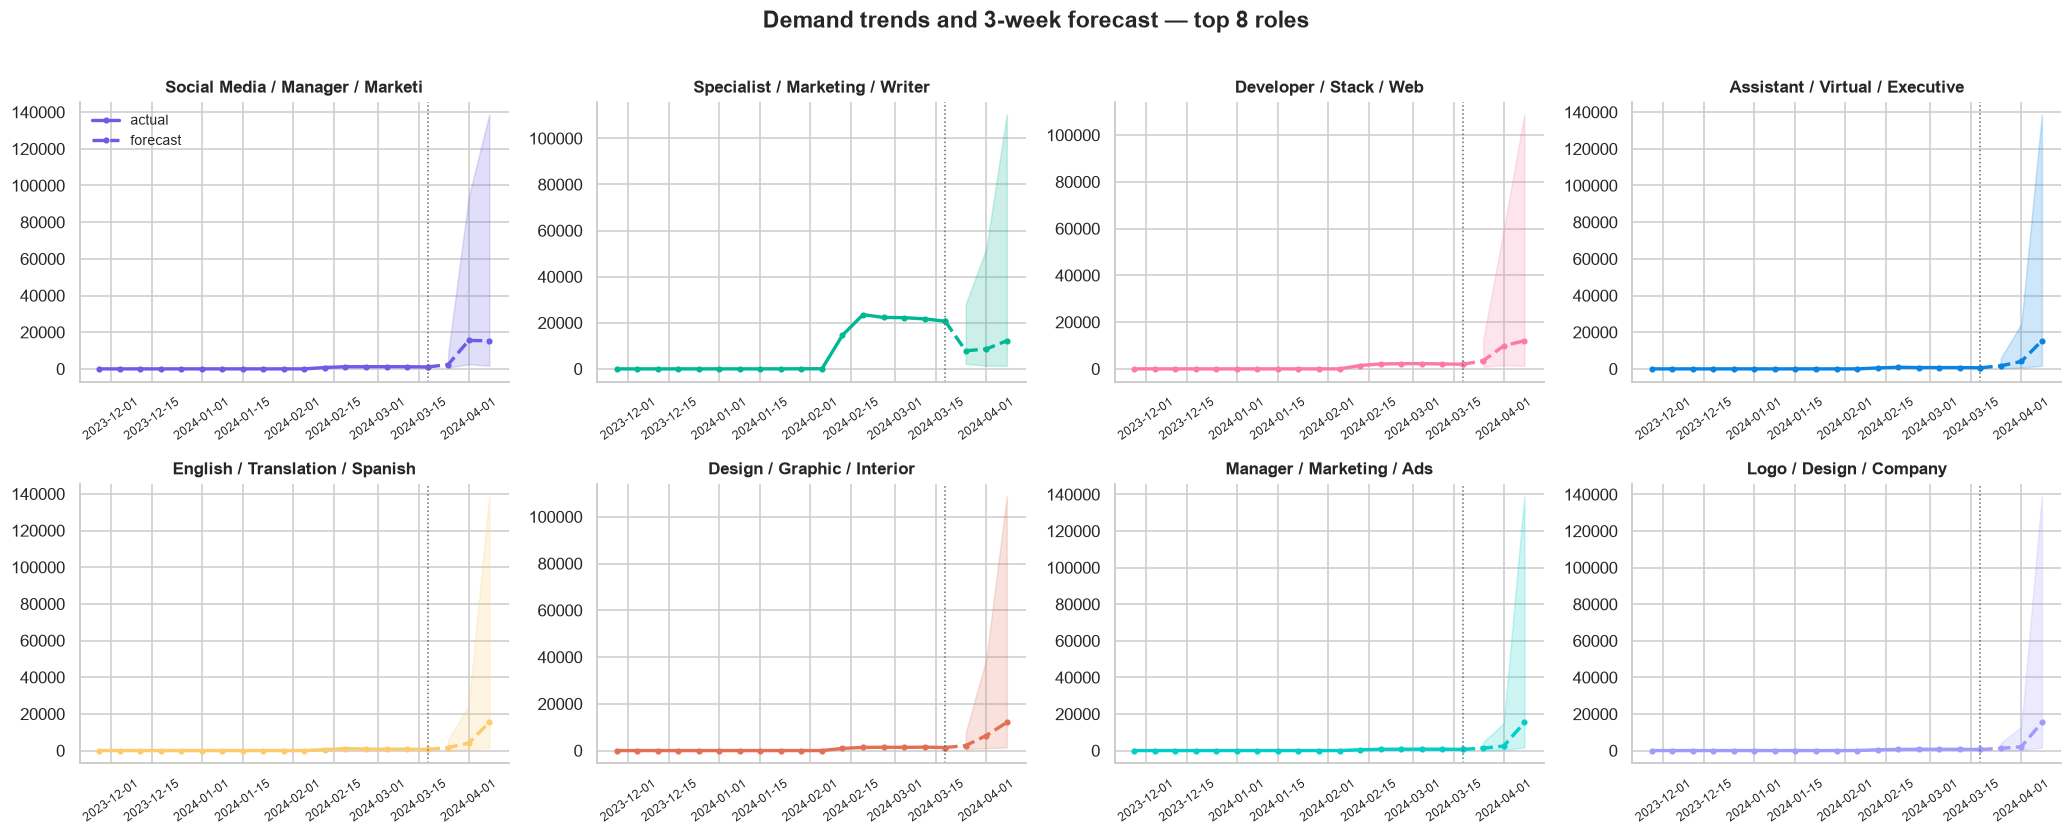

In [ ]:
# --- A. Demand trends + forecast for the 8 highest-demand roles (small multiples) ---
top8 = summary.head(8)["role"].tolist()
fig, axes = plt.subplots(2, 4, figsize=(19, 7.5))
for ax, role, col in zip(axes.ravel(), top8, PALETTE + PALETTE):
    hist = role_counts[role]
    ax.plot(hist.index, hist.values, color=col, lw=2.2, marker="o", ms=3, label="actual")
    ax.plot([hist.index[-1], *fc.index], [hist.iloc[-1], *fc[role].values], color=col, ls="--", lw=2.2, marker="o", ms=3, label="forecast")
    ax.fill_between(fc.index, lo[role], hi[role], color=col, alpha=.2)
    ax.axvline(hist.index[-1], color="#636e72", ls=":", lw=1)
    ax.set_title(role[:32], fontsize=11); ax.tick_params(axis="x", rotation=35, labelsize=8)
axes[0, 0].legend(frameon=False, fontsize=9)
fig.suptitle(f"Demand trends and {H}-{label} forecast — top 8 roles", fontweight="bold", fontsize=15, y=1.01)
fig.tight_layout()
show_fig(fig, "t3_a_demand_forecast")

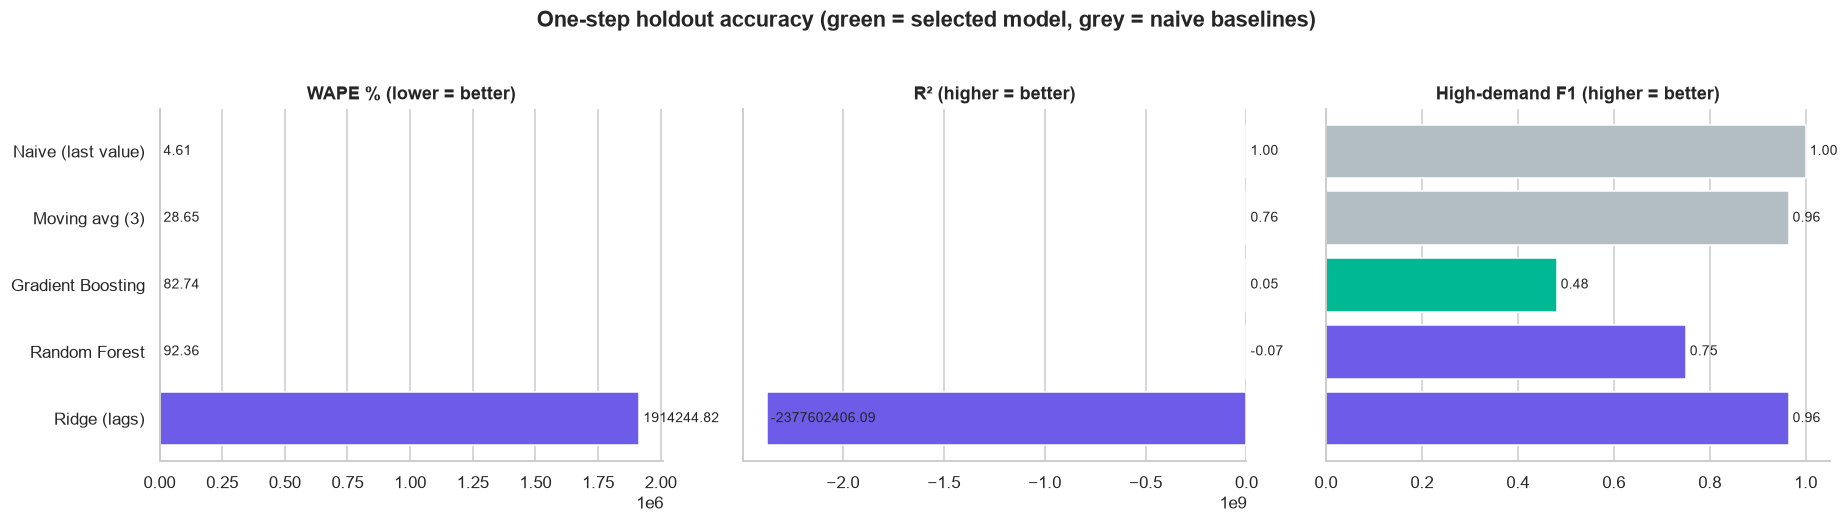

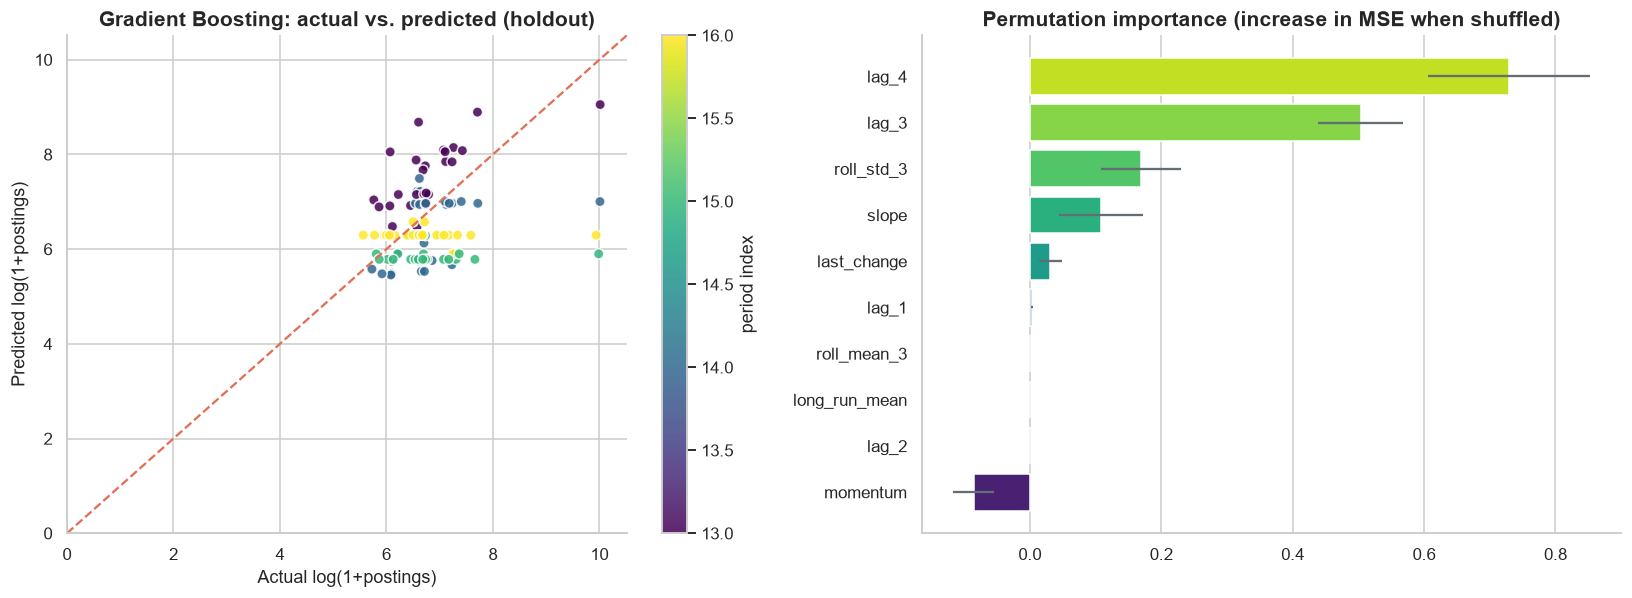

In [ ]:
# --- B. Model comparison ---
order = res.sort_values("WAPE_%").index
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, (metric, title, asc) in zip(axes, [("WAPE_%", "WAPE % (lower = better)", True),
                                          ("R2", "R² (higher = better)", False),
                                          ("HighDemand_F1", "High-demand F1 (higher = better)", False)]):
    vals = res.loc[order, metric]
    cols = [PALETTE[1] if n == best_name else PALETTE[0] if n in models else "#B2BEC3" for n in order]
    ax.barh(order, vals, color=cols, edgecolor="white")
    ax.invert_yaxis(); ax.set_title(title, fontsize=12); ax.grid(axis="y", visible=False)
    for i, v in enumerate(vals):
        ax.text(v, i, f" {v:.2f}", va="center", fontsize=9)
axes[1].set_yticklabels([]); axes[2].set_yticklabels([])
fig.suptitle("One-step holdout accuracy (green = selected model, grey = naive baselines)", fontweight="bold", y=1.03)
fig.tight_layout()
show_fig(fig, "t3_b_model_comparison")

# --- C. Actual vs predicted ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
pt = np.clip(preds[best_name], 0, None)
sc = axes[0].scatter(yte, pt, c=mte["t"], cmap="viridis", s=45, alpha=.85, edgecolor="white")
lim = [0, max(yte.max(), pt.max()) * 1.05]
axes[0].plot(lim, lim, color="#E17055", ls="--"); axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_xlabel("Actual log(1+postings)"); axes[0].set_ylabel("Predicted log(1+postings)")
axes[0].set_title(f"{best_name}: actual vs. predicted (holdout)")
plt.colorbar(sc, ax=axes[0], label="period index")
# --- D. Importance ---
d = imp_df.sort_values("importance")
axes[1].barh(d["feature"], d["importance"], xerr=d["std"], color=sns.color_palette("viridis", len(d)), ecolor="#636e72")
axes[1].set_title("Permutation importance (increase in MSE when shuffled)"); axes[1].grid(axis="y", visible=False)
fig.tight_layout()
show_fig(fig, "t3_c_fit_and_importance")

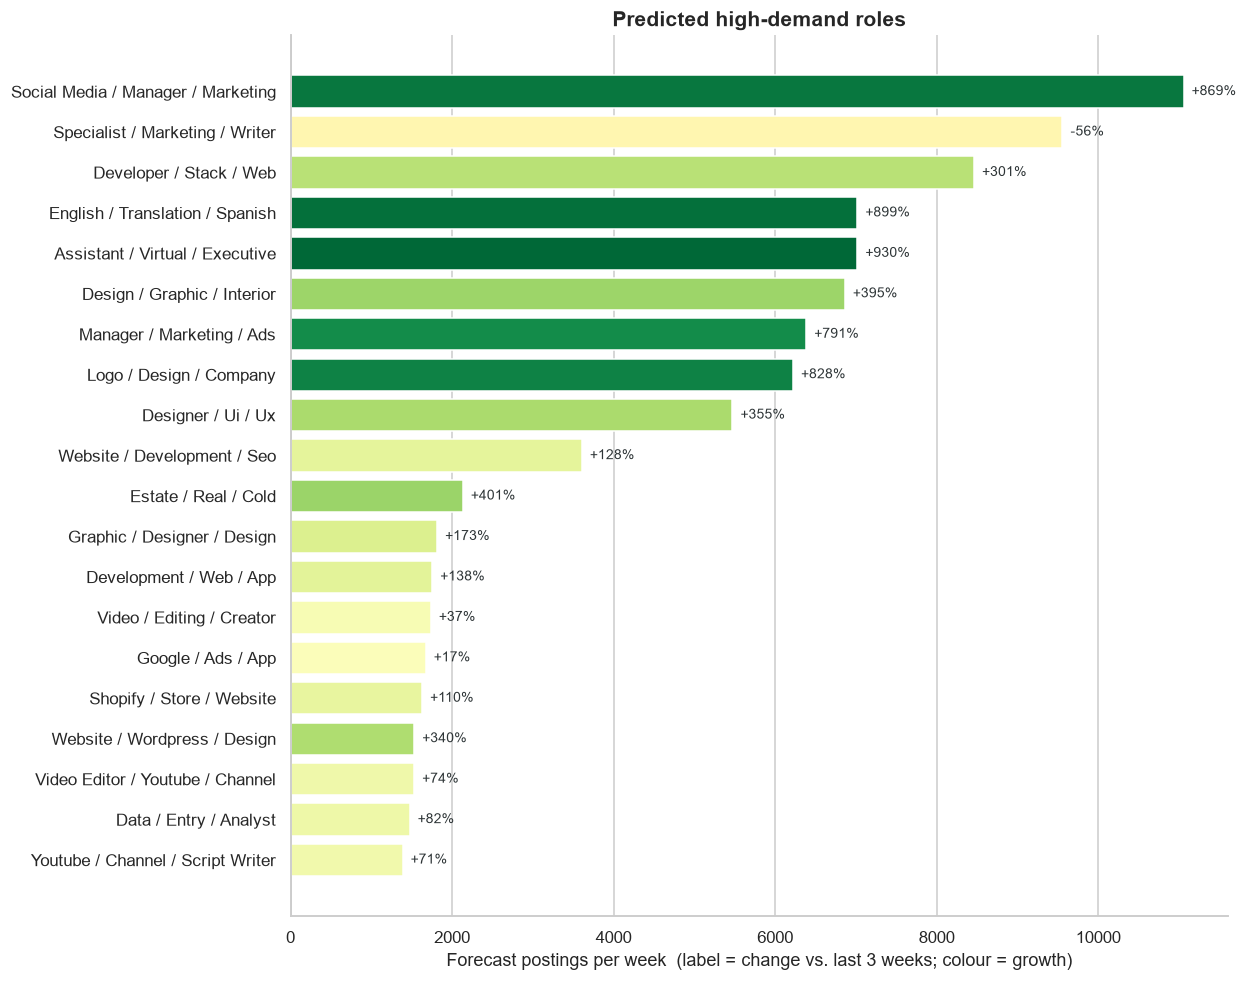

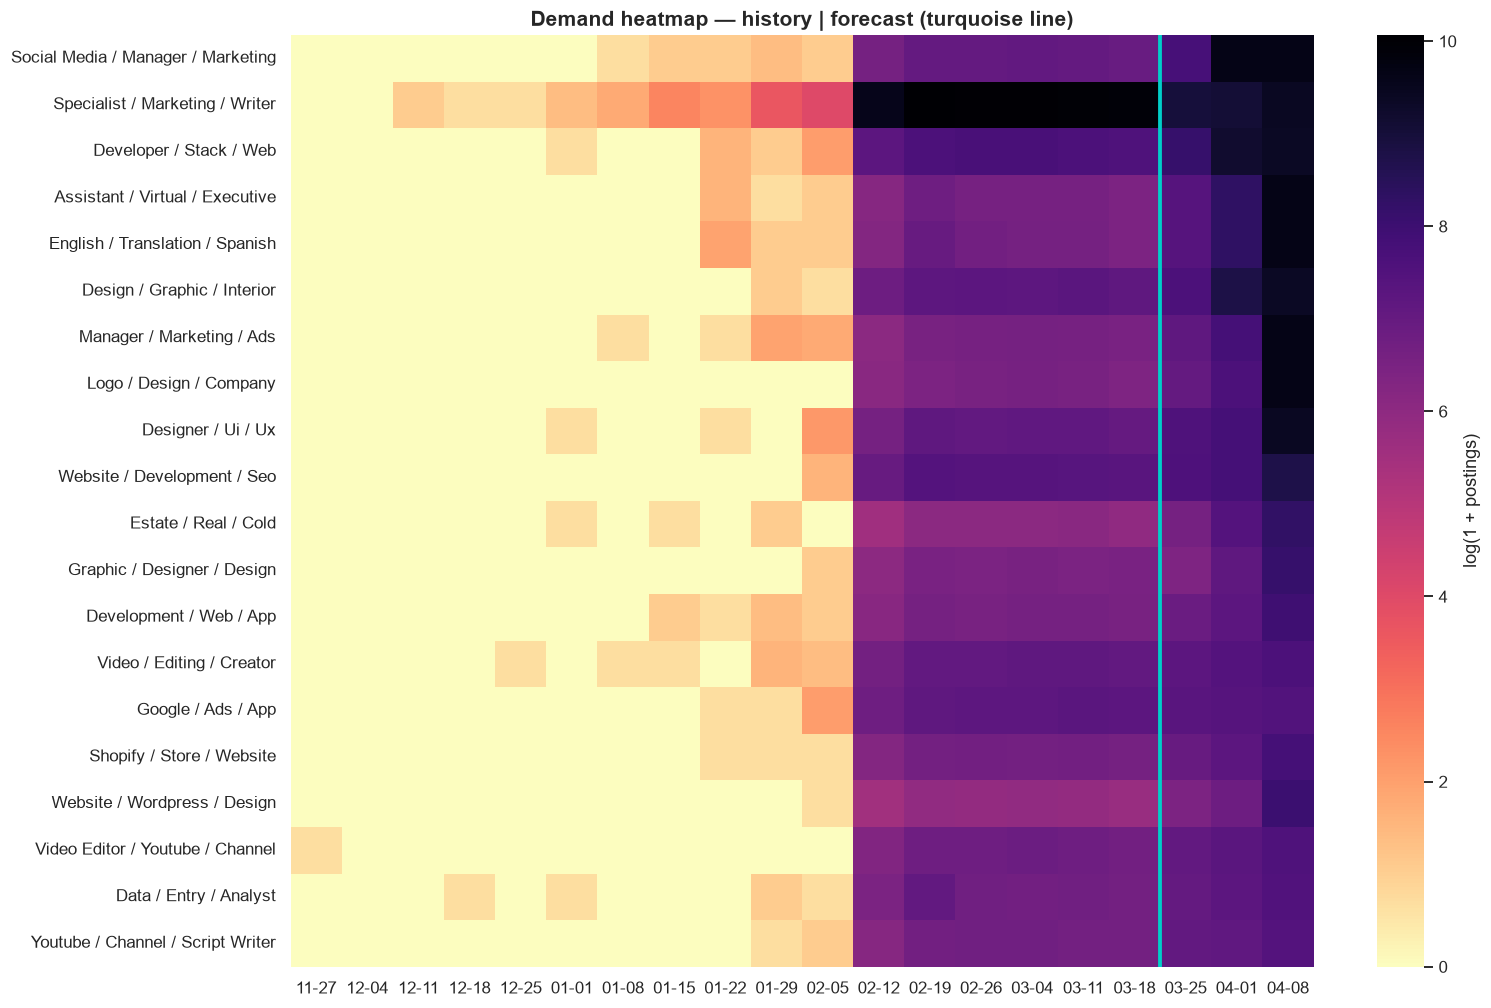

In [ ]:
# --- E. Forecast ranking ---
d = summary.head(TOP_K_ROLES * 2).sort_values("forecast_avg")
lim = max(abs(d["growth_pct"]).max(), 1)
colors = plt.get_cmap("RdYlGn")(plt.Normalize(-lim, lim)(d["growth_pct"]))
fig, ax = plt.subplots(figsize=(11, 0.42 * len(d) + 2))
ax.barh(d["role"], d["forecast_avg"], color=colors, edgecolor="white")
for i, (v, g) in enumerate(zip(d["forecast_avg"], d["growth_pct"])):
    ax.text(v, i, f"  {g:+.0f}%", va="center", fontsize=9, color="#2d3436")
ax.grid(axis="y", visible=False)
ax.set_xlabel(f"Forecast postings per {label}  (label = change vs. last {H} {label}s; colour = growth)")
ax.set_title("Predicted high-demand roles")
show_fig(fig, "t3_d_forecast_ranking")

# --- F. Demand heatmap incl. forecast ---
order20 = summary.head(20)["role"]
comb = pd.concat([role_counts[order20], fc[order20]]).T
fmt = "%Y-%m" if freq == "M" else "%m-%d"
step = max(1, comb.shape[1] // 12)
xl = [d_.strftime(fmt) if i % step == 0 else "" for i, d_ in enumerate(comb.columns)]
fig, ax = plt.subplots(figsize=(15, 0.4 * len(order20) + 3))
sns.heatmap(np.log1p(comb), cmap="magma_r", ax=ax, xticklabels=xl, cbar_kws={"label": "log(1 + postings)"})
ax.axvline(len(role_counts), color="#00CEC9", lw=2.5)
ax.set_title("Demand heatmap — history | forecast (turquoise line)"); ax.set_xlabel(""); ax.set_ylabel("")
show_fig(fig, "t3_e_demand_heatmap")

In [ ]:
import plotly.graph_objects as go

In [ ]:
# --- G. Interactive: all top roles, actual + forecast ---
figp = go.Figure()
for i, role in enumerate(summary.head(TOP_K_ROLES)["role"]):
    col = PALETTE[i % len(PALETTE)]
    hist = role_counts[role]
    figp.add_trace(go.Scatter(x=hist.index, y=hist.values, mode="lines+markers", name=role, legendgroup=role,
                              line=dict(color=col, width=2.5)))
    figp.add_trace(go.Scatter(x=[hist.index[-1], *fc.index], y=[hist.iloc[-1], *fc[role].values], mode="lines+markers",
                              name=f"{role} (forecast)", legendgroup=role, showlegend=False,
                              line=dict(color=col, width=2.5, dash="dash")))
figp.update_layout(template="plotly_white", title=f"Demand trends and forecast — top {TOP_K_ROLES} roles (click legend to toggle)",
                   yaxis_title=f"Postings per {label}", hovermode="x unified")
figp.show()

Results

In [ ]:
print(f"Selected model: {best_name}  |  one-step holdout WAPE = {res.loc[best_name, 'WAPE_%']:.1f}%, "
      f"R² = {res.loc[best_name, 'R2']:.2f}, high-demand F1 = {res.loc[best_name, 'HighDemand_F1']:.2f}")
base = res.loc[["Naive (last value)", "Moving avg (3)"], "WAPE_%"].min()
print("Beats the best naive baseline." if res.loc[best_name, "WAPE_%"] < base else
      "Does NOT beat the best naive baseline - treat the forecast as indicative only.")

print("\nPredicted HIGH-DEMAND roles:")
display(summary[summary["high_demand"]][["rank", "role", "recent_avg", "forecast_avg", "growth_pct", "demand_share_pct", "trend"]])
print("Fastest-RISING roles among those with meaningful volume:")
display(summary[summary["recent_avg"] >= summary["recent_avg"].median()].nlargest(5, "growth_pct")
        [["role", "recent_avg", "forecast_avg", "growth_pct", "trend"]])

res.to_csv(OUTPUT_DIR / "tables" / "task3_model_comparison.csv")
if backtest is not None:
    backtest.to_csv(OUTPUT_DIR / "tables" / "task3_backtest.csv")
summary.to_csv(OUTPUT_DIR / "tables" / "task3_role_forecast.csv", index=False)
fc.reset_index().rename(columns={"index": "period"}).to_csv(OUTPUT_DIR / "tables" / "task3_forecast_by_period.csv", index=False)

Selected model: Gradient Boosting  |  one-step holdout WAPE = 82.7%, R² = 0.05, high-demand F1 = 0.48
Does NOT beat the best naive baseline - treat the forecast as indicative only.

Predicted HIGH-DEMAND roles:


,rank,role,recent_avg,forecast_avg,growth_pct,demand_share_pct,trend
0,1,Social Media / Manager / Marketing,"1,141.00","11,056.51",868.64,11.95,Rising
1,2,Specialist / Marketing / Writer,"21,526.33","9,556.95",-55.60,10.33,Falling
2,3,Developer / Stack / Web,"2,110.00","8,462.07",300.97,9.14,Rising
3,4,Assistant / Virtual / Executive,681.00,"7,017.77",929.83,7.58,Rising
4,5,English / Translation / Spanish,702.33,"7,017.77",898.57,7.58,Rising
5,6,Design / Graphic / Interior,"1,384.67","6,862.54",395.47,7.41,Rising
6,7,Manager / Marketing / Ads,716.33,"6,385.28",790.83,6.90,Rising


Fastest-RISING roles among those with meaningful volume:


,role,recent_avg,forecast_avg,growth_pct,trend
0,Social Media / Manager / Marketing,"1,141.00","11,056.51",868.64,Rising
5,Design / Graphic / Interior,"1,384.67","6,862.54",395.47,Rising
8,Designer / Ui / Ux,"1,202.67","5,471.72",354.82,Rising
2,Developer / Stack / Web,"2,110.00","8,462.07",300.97,Rising
9,Website / Development / Seo,"1,584.33","3,606.96",127.62,Rising


**Reading the results:** compare the learned models with the naive baselines first — if they do not clearly win, the history is too short or too noisy for more than a trend-following forecast.
The backtest is the most honest number because it forecasts several periods without seeing them. Bands are approximate; demand shocks (seasonality, platform changes) are not modelled,
and with only a few months of data seasonality cannot be learned at all.

## 8. Task 4 — Compare average hourly rates across countries

**Goal:** compare the hourly rates offered in different countries, with an interactive map/charts.

**Method**
1. Use hourly postings only (fixed-price budgets are a different unit), excluding flagged outliers.
2. Per country: number of postings, mean, **median**, 10%-trimmed mean, spread (IQR), and a distribution-free 95% confidence interval for the median.
3. Test whether countries differ (Kruskal-Wallis) and whether each country differs from the rest (Mann-Whitney with FDR correction).
4. **Mix adjustment:** countries post different kinds of jobs, so also compute each country's premium *after* removing the typical pay of each job category.
5. Interactive world maps + ranked and distribution charts.

> Countries with fewer than `MIN_COUNTRY_N` hourly postings are excluded from rankings — small samples give unreliable averages.

In [ ]:
#Assign categories
t2 = df.copy()
if COLS.get("category") and "category" in t2.columns and t2["category"].notna().mean() >= .5:
    t2["category"] = t2["category"].fillna("Uncategorised")
    cat_source = "dataset column"
else:
    k = min(N_CLUSTERS, max(2, len(t2) // 50))
    tf = TfidfVectorizer(stop_words=STOP, ngram_range=(1, 2), min_df=5, max_features=5000, token_pattern=TOKEN_PATTERN)
    Xt = tf.fit_transform(t2["title_clean"])
    km = MiniBatchKMeans(n_clusters=k, n_init=3, random_state=SEED, batch_size=2048)
    labels = km.fit_predict(Xt)
    vocab = np.array(tf.get_feature_names_out())
    def cluster_name(centre, k_terms=3):
        picked, used = [], set()
        for w in vocab[np.argsort(centre)[::-1][:30]]:
            parts = set(w.split())
            if parts & used:          # skip terms that repeat an already-chosen word
                continue
            picked.append(w.title()); used |= parts
            if len(picked) == k_terms:
                break
        return " / ".join(picked)
    names = {i: cluster_name(c) for i, c in enumerate(km.cluster_centers_)}
    # make duplicate names unique
    seen = {}
    for i in names:
        seen[names[i]] = seen.get(names[i], 0) + 1
        if seen[names[i]] > 1:
            names[i] += f" ({seen[names[i]]})"
    t2["category"] = pd.Series(labels, index=t2.index).map(names)
    cat_source = f"derived from titles (TF-IDF + KMeans, k={k})"
print(f"Category source: {cat_source} | categories: {t2['category'].nunique()}")

preview = (t2.groupby("category")["title_raw"]
             .agg(postings="size", examples=lambda s: " | ".join(s.sample(min(3, len(s)), random_state=SEED).str[:45]))
             .sort_values("postings", ascending=False))
preview.head(25)

Category source: derived from titles (TF-IDF + KMeans, k=25) | categories: 25


,postings,examples
category,,
Specialist / Marketing / Writer,125168,Photos Amendments | Online reputation manageme...
Developer / Stack / Web,12104,"Web Designer, Web Developer, or Front-end Dev ..."
Website / Development / Seo,9224,Website Developer | Website Building and Consu...
Google / Ads / App,7862,Looking for an Excel / Google Sheets expert | ...
Design / Graphic / Interior,7862,Add Text To Adobe Template (design) | Experien...
Video / Editing / Creator,7004,Concept Video Creator | Voice Over Artists For...
Designer / Ui / Ux,6929,Web Designer and UI/UX Specialist | UX/UI Desi...
Social Media / Manager / Marketing,6540,Social Media Manager | Social Media and Email ...
Data / Entry / Analyst,5120,Data Scientist for Sentiment Analysis and Top ...


### 6.2 Choose the time granularity and build category × period counts

In [ ]:
span_days = (t2["date"].max() - t2["date"].min()).days
freq = GRANULARITY if GRANULARITY != "auto" else ("M" if span_days >= 150 else "W" if span_days >= 49 else "D")
label = {"M": "month", "W": "week", "D": "day"}[freq]
print(f"Data span: {span_days} days -> analysing by {label}")

t2["period"] = t2["date"].dt.to_period(freq).dt.start_time

# drop partial first / last periods (they would distort counts)
if freq in ("M", "W"):
    tol = pd.Timedelta(days=3 if freq == "M" else 2)
    p_min, p_max = t2["period"].min(), t2["period"].max()
    p_end = (p_max.to_period(freq)).end_time
    if t2["date"].min() > p_min + tol:
        t2 = t2[t2["period"] > p_min]; print(f"Dropped partial first {label}: {p_min:%Y-%m-%d}")
    if t2["date"].max() < p_end - tol:
        t2 = t2[t2["period"] < p_max]; print(f"Dropped partial last {label}: {p_max:%Y-%m-%d}")

counts = t2.groupby(["period", "category"]).size().unstack(fill_value=0)
full = pd.date_range(counts.index.min(), counts.index.max(), freq={"M": "MS", "W": "W-MON", "D": "D"}[freq])
counts = counts.reindex(full, fill_value=0); counts.index.name = "period"
assert len(counts) >= 6, f"Only {len(counts)} {label}s of data - need at least 6 periods for trend analysis."
total = counts.sum(axis=1)
share = counts.div(total, axis=0) * 100          # % of that period's postings
print(f"{len(counts)} {label}s | {int(counts.values.sum()):,} postings | {counts.shape[1]} categories")
counts.tail()

Data span: 143 days -> analysing by week
Dropped partial first week: 2023-10-30
17 weeks | 244,758 postings | 25 categories


category,Assistant / Virtual / Executive,Data / Entry / Analyst,Design / Graphic / Interior,Designer / Ui / Ux,Developer / Stack / Web,Development / Web / App,English / Translation / Spanish,Estate / Real / Cold,Google / Ads / App,Graphic / Designer / Design,Landing / Book / Page,Logo / Design / Company,Long Term / Editor / Video,Manager / Marketing / Ads,Page / Website / Seo,Research / Market / Product,Shopify / Store / Website,Social Media / Manager / Marketing,Specialist / Marketing / Writer,Video / Editing / Creator,Video Editor / Youtube / Channel,Website / Development / Seo,Website / Wordpress / Design,Wordpress / Site / Developer,Youtube / Channel / Script Writer
period,,,,,,,,,,,,,,,,,,,,,,,,,
2024-02-19,870,1205,1351,1321,2100,768,1086,431,1299,674,553,628,296,709,458,479,785,1181,23542,1211,877,1714,376,822,802
2024-02-26,715,835,1419,1225,2226,703,801,431,1382,633,503,707,317,736,429,450,815,1176,22310,1213,888,1677,350,849,842
2024-03-04,717,815,1377,1241,2242,758,748,442,1385,696,490,723,306,750,442,437,775,1211,22216,1309,949,1643,370,822,842
2024-03-11,715,839,1474,1245,2122,753,741,448,1489,635,498,691,332,733,410,457,808,1176,21691,1298,867,1580,351,839,797
2024-03-18,611,774,1303,1122,1966,703,618,386,1412,663,470,596,260,666,402,426,742,1036,20672,1187,825,1530,321,797,791


### 6.3 Growth metrics and classification

In [ ]:
n = len(counts)
rec_n = max(1, int(np.ceil(n * RECENT_FRAC)))
base_n = max(1, min(rec_n, n - rec_n))
recent, base = slice(n - rec_n, n), slice(n - rec_n - base_n, n - rec_n)
eps = 0.5 / total.mean() * 100                      # add-half smoothing (in % points)
x = np.arange(n)
new_cut = counts.index[n - rec_n]
print(f"Recent window: last {rec_n} {label}s | baseline: the {base_n} {label}s before that")

rows = []
for cat in counts.columns:
    s, c = share[cat].values, counts[cat].values
    rec_s, base_s = s[recent].mean(), s[base].mean()
    if np.ptp(s) > 0:
        tau, p = stats.kendalltau(x, s); slope = stats.linregress(x, s).slope
    else:
        tau, p, slope = 0.0, 1.0, 0.0
    seen = counts.index[c >= MIN_FIRST_SEEN]
    first = seen.min() if len(seen) else pd.NaT
    rows.append({
        "category": cat, "total_postings": int(c.sum()), "recent_postings": int(c[recent].sum()),
        "recent_share_pct": rec_s, "baseline_share_pct": base_s,
        "share_growth_pct": ((rec_s + eps) / (base_s + eps) - 1) * 100,
        "trend_tau": 0.0 if np.isnan(tau) else tau, "trend_p": 1.0 if np.isnan(p) else p,
        "slope_pp_per_period": slope, "first_seen": first,
        "is_new": bool(pd.notna(first) and first >= new_cut and n > rec_n + base_n),
    })
met = pd.DataFrame(rows)

def classify(r):
    enough = r["recent_postings"] >= MIN_RECENT_POSTS
    up = r["trend_tau"] > 0 and r["trend_p"] < ALPHA and r["share_growth_pct"] >= MIN_GROWTH_PCT
    if r["is_new"] and enough:
        return "New entrant"
    if up and enough:
        return "Emerging" if r["recent_share_pct"] <= MAX_SHARE_PCT else "Established & growing"
    if r["trend_tau"] < 0 and r["trend_p"] < ALPHA and r["share_growth_pct"] <= -MIN_GROWTH_PCT and enough:
        return "Declining"
    return "Stable"

met["status"] = met.apply(classify, axis=1)
met["emergence_score"] = (met["share_growth_pct"].rank(pct=True) + met["trend_tau"].rank(pct=True)
                          + np.log1p(met["recent_postings"]).rank(pct=True)) / 3 * 100
met = met.sort_values("emergence_score", ascending=False).reset_index(drop=True)
emerging = met[met["status"].isin(["Emerging", "New entrant"])]
print(met["status"].value_counts().to_dict())
met.head(10)

Recent window: last 5 weeks | baseline: the 5 weeks before that
{'Stable': 13, 'Emerging': 12}


,category,total_postings,recent_postings,recent_share_pct,baseline_share_pct,share_growth_pct,trend_tau,trend_p,slope_pp_per_period,first_seen,is_new,status,emergence_score
0,Wordpress / Site / Developer,4635,4129,1.91,0.54,252.79,0.80,0.00,0.16,2024-02-12,False,Emerging,82.67
1,Website / Development / Seo,9224,8144,3.77,1.49,152.08,0.66,0.00,0.32,2024-02-05,False,Emerging,82.00
2,Design / Graphic / Interior,7862,6924,3.21,1.43,123.78,0.72,0.00,0.27,2024-02-12,False,Emerging,80.00
3,Google / Ads / App,7862,6967,3.23,2.85,13.44,0.69,0.00,0.30,2024-02-05,False,Stable,74.67
4,Youtube / Channel / Script Writer,4575,4074,1.89,1.01,86.12,0.77,0.00,0.17,2024-02-12,False,Emerging,70.67
5,Video Editor / Youtube / Channel,4966,4406,2.04,0.39,413.76,0.46,0.02,-1.80,2024-02-12,False,Emerging,70.67
6,Landing / Book / Page,2835,2514,1.16,0.23,407.43,0.66,0.00,0.09,2024-02-12,False,Emerging,68.00
7,Logo / Design / Company,3805,3345,1.55,0.32,373.29,0.60,0.00,0.13,2024-02-12,False,Emerging,62.67
8,Page / Website / Seo,2427,2141,0.99,0.38,156.20,0.66,0.00,0.08,2024-02-12,False,Emerging,58.00
9,Graphic / Designer / Design,3721,3301,1.53,0.66,130.42,0.64,0.00,0.13,2024-02-12,False,Emerging,57.33


Charts

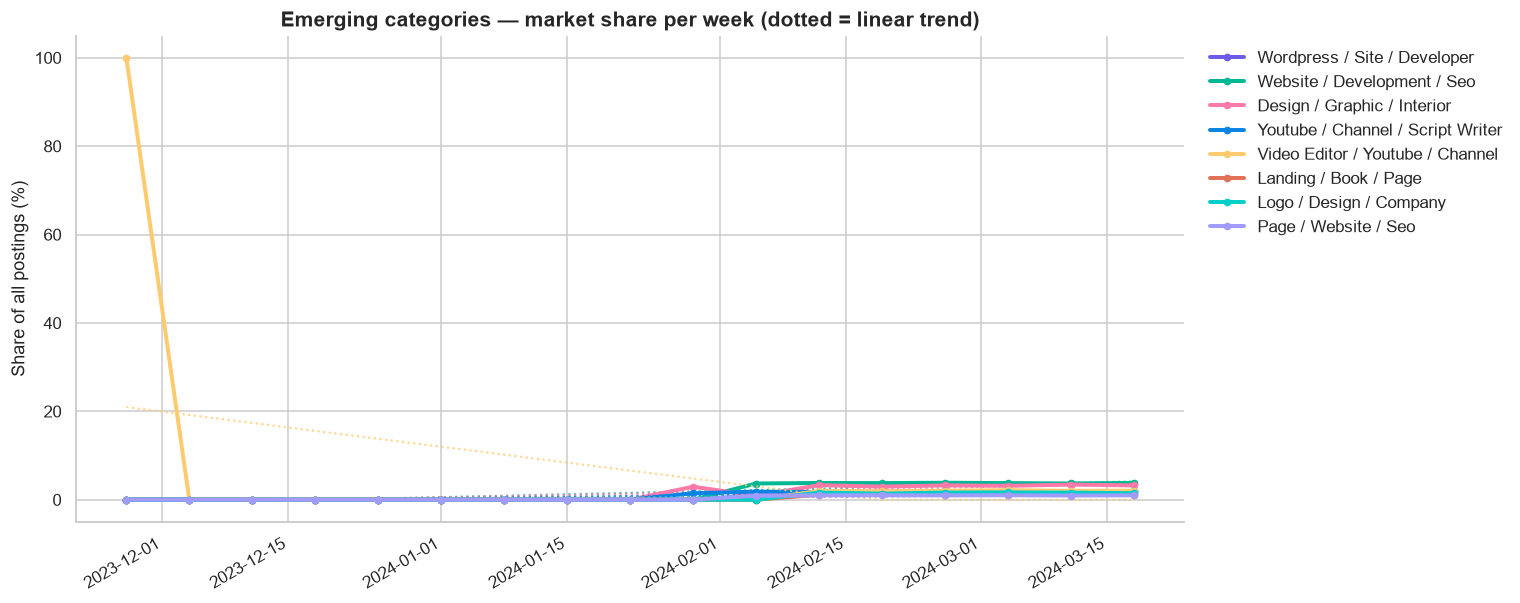

In [ ]:
STATUS_COLORS = {"Emerging": "#00B894", "New entrant": "#6C5CE7", "Established & growing": "#FDCB6E",
                 "Stable": "#B2BEC3", "Declining": "#E17055"}

# --- A. Share over time for top emerging categories ---
top_cats = (emerging if len(emerging) else met).head(TASK2_TOP_N_PLOT)["category"].tolist()
fig, ax = plt.subplots(figsize=(13, 6.5))
for i, cat in enumerate(top_cats):
    col = PALETTE[i % len(PALETTE)]
    ax.plot(share.index, share[cat], marker="o", lw=2.6, ms=4, color=col, label=cat)
    z = np.polyfit(x, share[cat].values, 1)
    ax.plot(share.index, np.clip(np.polyval(z, x), 0, None), ls=":", lw=1.4, color=col, alpha=.8)
ax.set_ylabel("Share of all postings (%)")
ax.set_title(f"Emerging categories — market share per {label} (dotted = linear trend)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False); fig.autofmt_xdate()
show_fig(fig, "t2_a_emerging_trends")

long = share[top_cats].reset_index().melt("period", var_name="category", value_name="share_pct")
px.line(long, x="period", y="share_pct", color="category", markers=True, color_discrete_sequence=PALETTE,
        labels={"share_pct": "Share of postings (%)"},
        title="Emerging categories — interactive (click legend to toggle)").update_layout(template="plotly_white").show()

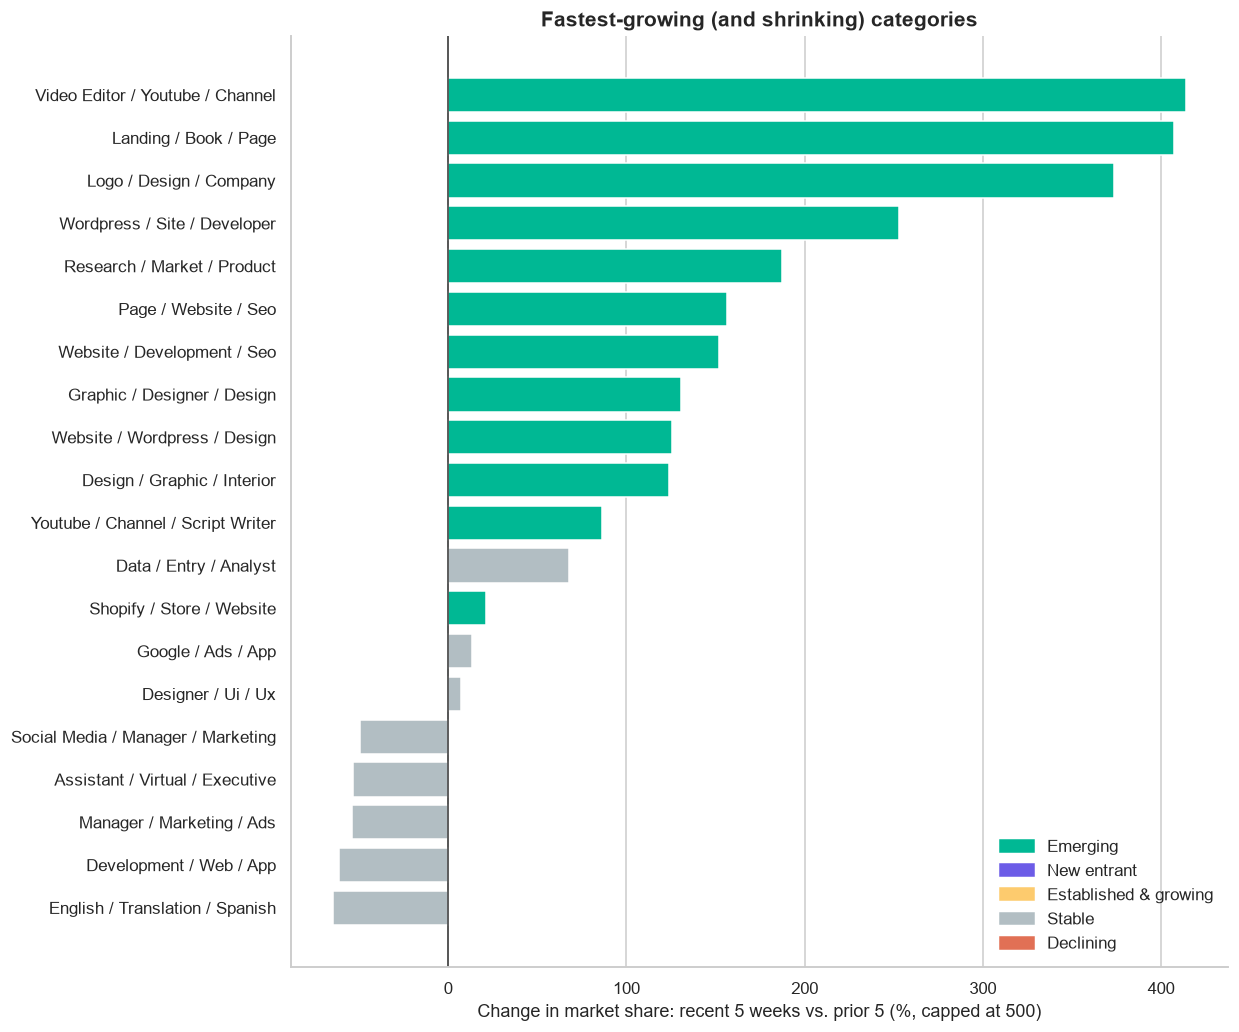

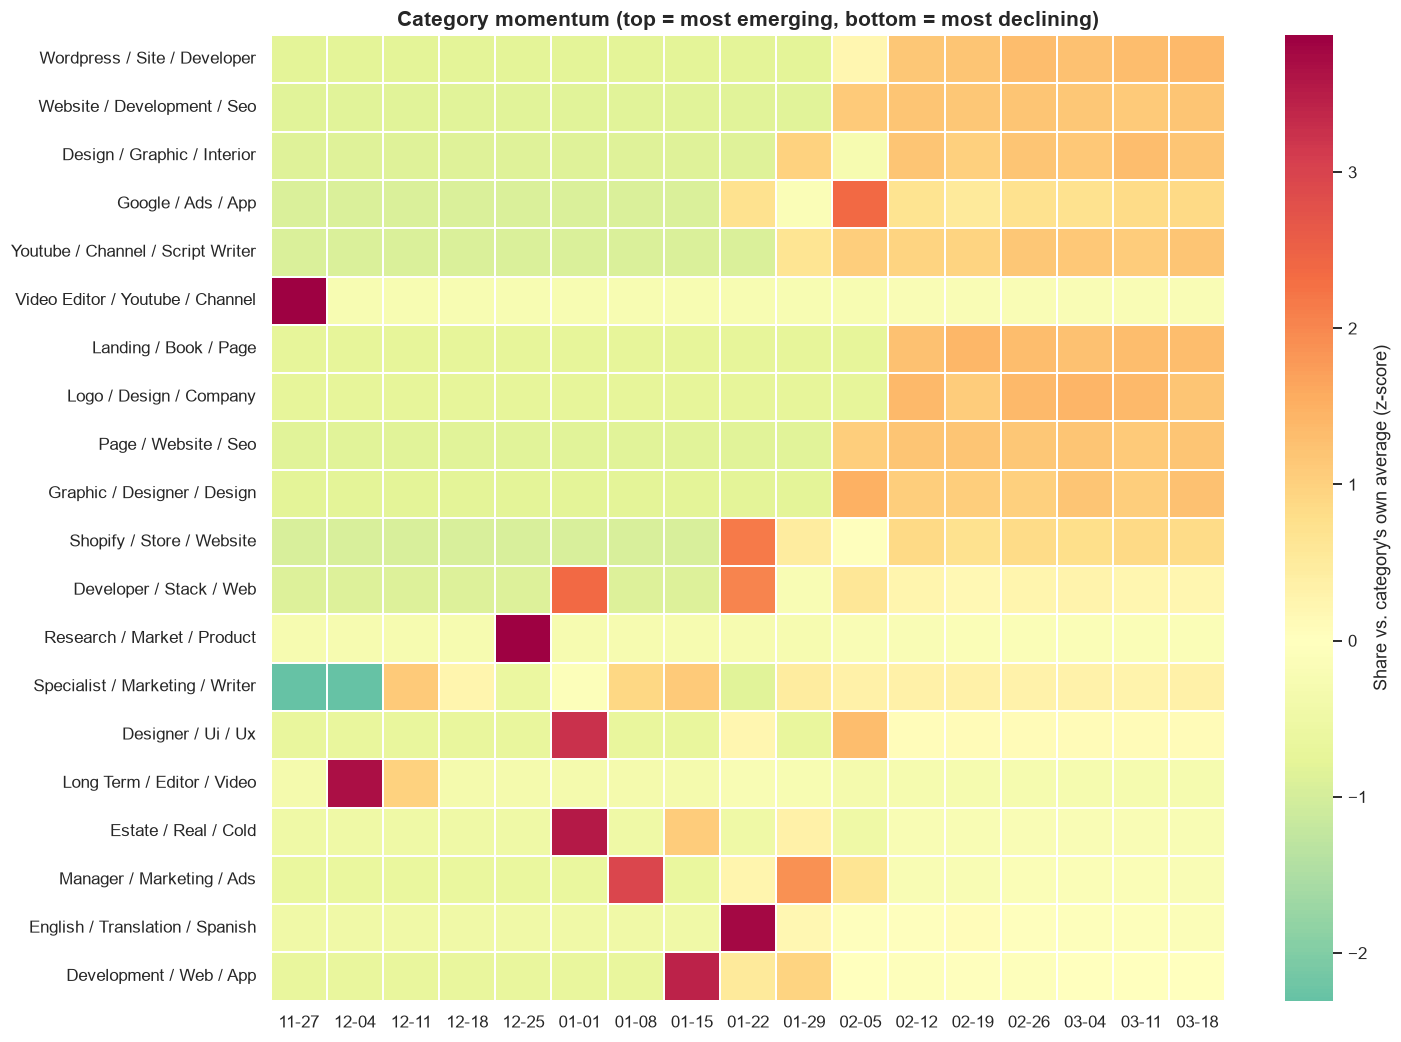

In [ ]:
# --- B. Fastest growing / shrinking ---
d = met[met["recent_postings"] >= MIN_RECENT_POSTS]
d = pd.concat([d.nlargest(15, "share_growth_pct"), d.nsmallest(5, "share_growth_pct")]).drop_duplicates("category")
d = d.sort_values("share_growth_pct")
fig, ax = plt.subplots(figsize=(11, 0.45 * len(d) + 2))
ax.barh(d["category"], d["share_growth_pct"].clip(upper=500), color=d["status"].map(STATUS_COLORS), edgecolor="white")
ax.axvline(0, color="#333", lw=1); ax.grid(axis="y", visible=False)
ax.set_xlabel(f"Change in market share: recent {rec_n} {label}s vs. prior {base_n} (%, capped at 500)")
ax.set_title("Fastest-growing (and shrinking) categories")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in STATUS_COLORS.values()], STATUS_COLORS.keys(),
          loc="lower right", frameon=False)
show_fig(fig, "t2_b_growth_bars")

# --- C. Momentum heatmap ---
cats = pd.concat([met.nlargest(15, "emergence_score"), met.nsmallest(5, "emergence_score")])["category"].unique()
z = share[cats].apply(lambda s: (s - s.mean()) / (s.std() or 1))
z.index = z.index.strftime("%Y-%m" if freq == "M" else "%m-%d")
fig, ax = plt.subplots(figsize=(14, 0.42 * len(cats) + 3))
sns.heatmap(z.T, cmap="Spectral_r", center=0, linewidths=.3, ax=ax,
            cbar_kws={"label": "Share vs. category's own average (z-score)"})
ax.set_title("Category momentum (top = most emerging, bottom = most declining)"); ax.set_xlabel(""); ax.set_ylabel("")
show_fig(fig, "t2_c_momentum_heatmap")

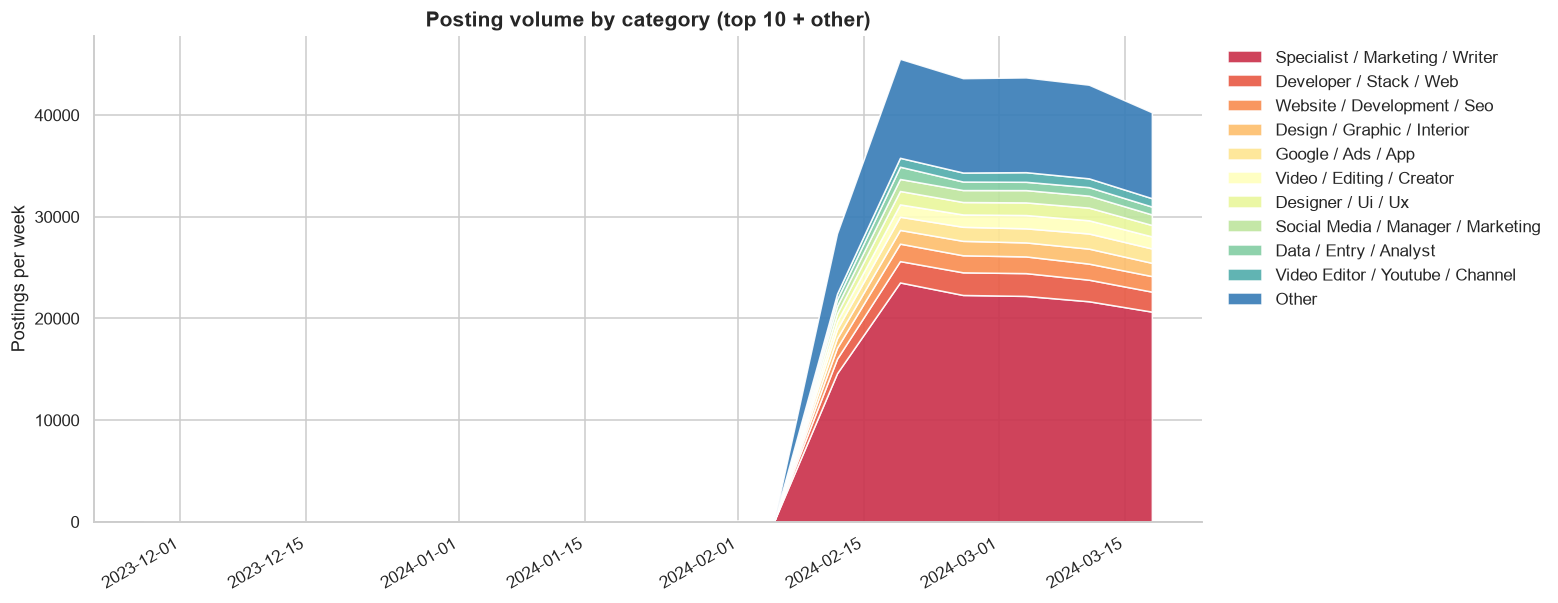

In [ ]:
# --- D. Stacked volume ---
top10 = counts.sum().nlargest(10).index
v = counts[top10].copy(); v["Other"] = counts.drop(columns=top10).sum(axis=1)
fig, ax = plt.subplots(figsize=(13, 6.5))
ax.stackplot(v.index, v.T.values, labels=v.columns, colors=sns.color_palette("Spectral", len(v.columns)), alpha=.92)
ax.set_ylabel(f"Postings per {label}"); ax.set_title("Posting volume by category (top 10 + other)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False); fig.autofmt_xdate()
show_fig(fig, "t2_d_volume_area")

# --- E. Landscape (interactive) ---
met["growth_capped"] = met["share_growth_pct"].clip(-100, 500)
px.scatter(met, x="recent_postings", y="growth_capped", size="recent_share_pct", color="status",
           color_discrete_map=STATUS_COLORS, hover_name="category", log_x=True, size_max=50,
           hover_data={"share_growth_pct": ":.0f", "trend_tau": ":.2f", "recent_share_pct": ":.2f", "growth_capped": False},
           labels={"recent_postings": "Recent postings (log)", "growth_capped": "Share growth % (capped)"},
           title="Category landscape: size vs. growth").update_layout(template="plotly_white").show()

Results- emgering categories

In [ ]:
cols = ["category", "status", "recent_postings", "recent_share_pct", "baseline_share_pct",
        "share_growth_pct", "trend_tau", "first_seen"]
print(f"Period: {counts.index.min():%Y-%m-%d} -> {counts.index.max():%Y-%m-%d} ({len(counts)} {label}s) | categories: {counts.shape[1]}")
print("\nEmerging & new categories:")
display(emerging[cols] if len(emerging) else pd.DataFrame({"note": ["none met the thresholds - lower MIN_GROWTH_PCT / MIN_RECENT_POSTS"]}))
print("Fastest-declining categories:")
display(met[met["status"] == "Declining"].nsmallest(5, "share_growth_pct")[cols])

emerging.to_csv(OUTPUT_DIR / "tables" / "task2_emerging_categories.csv", index=False)
met.to_csv(OUTPUT_DIR / "tables" / "task2_category_metrics.csv", index=False)
counts.reset_index().to_csv(OUTPUT_DIR / "tables" / "task2_period_counts.csv", index=False)

Period: 2023-11-27 -> 2024-03-18 (17 weeks) | categories: 25

Emerging & new categories:


,category,status,recent_postings,recent_share_pct,baseline_share_pct,share_growth_pct,trend_tau,first_seen
0,Wordpress / Site / Developer,Emerging,4129,1.91,0.54,252.79,0.80,2024-02-12
1,Website / Development / Seo,Emerging,8144,3.77,1.49,152.08,0.66,2024-02-05
2,Design / Graphic / Interior,Emerging,6924,3.21,1.43,123.78,0.72,2024-02-12
4,Youtube / Channel / Script Writer,Emerging,4074,1.89,1.01,86.12,0.77,2024-02-12
5,Video Editor / Youtube / Channel,Emerging,4406,2.04,0.39,413.76,0.46,2024-02-12
6,Landing / Book / Page,Emerging,2514,1.16,0.23,407.43,0.66,2024-02-12
7,Logo / Design / Company,Emerging,3345,1.55,0.32,373.29,0.60,2024-02-12
8,Page / Website / Seo,Emerging,2141,0.99,0.38,156.20,0.66,2024-02-12
9,Graphic / Designer / Design,Emerging,3301,1.53,0.66,130.42,0.64,2024-02-12
10,Shopify / Store / Website,Emerging,3925,1.82,1.50,21.05,0.61,2024-02-12


Fastest-declining categories:


,category,status,recent_postings,recent_share_pct,baseline_share_pct,share_growth_pct,trend_tau,first_seen


**Definitions** — *Share growth*: change in a category's share of postings (recent vs. baseline window). *Emerging*: growth ≥ `MIN_GROWTH_PCT`,
significant upward Kendall trend, enough recent postings, share ≤ `MAX_SHARE_PCT`. *New entrant*: first seen only in the recent window.
Derived (clustered) categories are only as meaningful as the clusters — review the category preview in 6.1 and adjust `N_CLUSTERS` if needed.

## 7. Task 3 — Predict high-demand job roles from posting patterns over time

**Goal:** forecast which roles will be most in demand, with accuracy metrics and a visual of demand trends.

**Method**
1. *Roles* = the categories built in Task 2 (the dataset's own category column if it has one, otherwise clusters of similar titles). Demand = postings per role per period.
2. One model for all roles (a "panel" model) learns to predict next-period demand from each role's own recent history: lags, rolling mean/volatility, momentum and slope.
3. Honest evaluation, always forward in time:
   * **one-step holdout** — compare Ridge / Random Forest / Gradient Boosting against two naive baselines;
   * **multi-step backtest** — hide the last *H* periods, forecast them recursively, compare with what really happened;
   * **high-demand classification** — can the model flag the roles that end up in the top quartile of demand?
4. Refit on all data, forecast *H* periods ahead, and rank roles (with approximate 80% prediction bands).

> Requires the Task 2 cells to have been run (they create `counts`, `freq` and `label`).

### 7.1 Parameters and demand series

In [ ]:
# ---- Task 3 parameters
LAGS              = 4      # periods of history used as features
TEST_FRAC         = 0.25   # last 25% of periods = holdout for model comparison
FORECAST_H        = None   # None -> auto (~15% of the history, at least 2 periods)
TOP_K_ROLES       = 10     # roles reported as the high-demand list
HIGH_DEMAND_Q     = 0.75   # 'high demand' = above this quantile of demand within a period
MIN_ROLE_POSTINGS = 30     # ignore roles with fewer postings overall (too noisy to forecast)

role_counts = counts.loc[:, counts.sum() >= MIN_ROLE_POSTINGS]
n_per = len(role_counts)
H = FORECAST_H or max(2, int(round(n_per * 0.15)))
test_n = max(2, int(round(n_per * TEST_FRAC)))
assert n_per >= LAGS + test_n + 4, f"Only {n_per} {label}s of history - not enough to train a forecasting model."
pd_freq = {"M": "MS", "W": "W-MON", "D": "D"}[freq]
log_counts = np.log1p(role_counts)           # model works on log(1 + postings)

print(f"Roles modelled: {role_counts.shape[1]} (of {counts.shape[1]}) | history: {n_per} {label}s")
print(f"Holdout: last {test_n} {label}s | forecast horizon: {H} {label}s")

Roles modelled: 25 (of 25) | history: 17 weeks
Holdout: last 4 weeks | forecast horizon: 3 weeks


### 7.2 Feature engineering
Every feature for period *t* uses only information from periods **before** *t* — no leakage.

In [ ]:
FEATURES = [f"lag_{i}" for i in range(1, LAGS + 1)] + \
           ["roll_mean_3", "roll_std_3", "long_run_mean", "momentum", "last_change", "slope"]

def feat_vec(h):
    """h = 1-D array of log-demand up to the period BEFORE the one being predicted."""
    lags = h[-LAGS:][::-1]                                   # lag_1 (most recent) ... lag_L
    return np.array([*lags,
                     h[-3:].mean(), h[-3:].std(), h.mean(),  # rolling level, volatility, long-run level
                     lags[0] - h[-LAGS:].mean(),             # momentum vs. recent average
                     lags[0] - lags[1],                      # last change
                     np.polyfit(np.arange(LAGS), h[-LAGS:], 1)[0]])   # slope over the lag window

def build_panel(log_df, t_from, t_to):
    """Supervised rows (one per role x target period) for target positions t_from .. t_to-1."""
    X, y, meta = [], [], []
    for role in log_df.columns:
        h = log_df[role].values
        for t in range(max(LAGS, t_from), t_to):
            X.append(feat_vec(h[:t])); y.append(h[t]); meta.append((role, t))
    return np.array(X), np.array(y), pd.DataFrame(meta, columns=["role", "t"])

split = n_per - test_n
Xtr, ytr, mtr = build_panel(log_counts, LAGS, split)
Xte, yte, mte = build_panel(log_counts, split, n_per)
print(f"Training rows: {len(ytr):,} | holdout rows: {len(yte):,} | features: {len(FEATURES)}")
pd.DataFrame(Xtr[:5], columns=FEATURES).round(2)

Training rows: 225 | holdout rows: 100 | features: 10


,lag_1,lag_2,lag_3,lag_4,roll_mean_3,roll_std_3,long_run_mean,momentum,last_change,slope
0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
3,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
4,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


### 7.3 Model comparison on the holdout (one-step-ahead)

In [ ]:
models = {
    "Ridge (lags)": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingRegressor(max_iter=250, learning_rate=0.05, max_leaf_nodes=8,
                                                       min_samples_leaf=8, l2_regularization=1.0, random_state=SEED),
}
preds = {"Naive (last value)": Xte[:, 0],                               # lag_1
         "Moving avg (3)": Xte[:, FEATURES.index("roll_mean_3")]}
for name, mdl in models.items():
    preds[name] = mdl.fit(Xtr, ytr).predict(Xte)

def evaluate(y_log_true, y_log_pred, meta):
    y_log_pred = np.clip(y_log_pred, 0, None)
    yt, yp = np.expm1(y_log_true), np.expm1(y_log_pred)
    d = meta.assign(actual=yt, pred=yp)
    def top_flag(col):                                       # top quartile of demand within each period
        thr = d.groupby("t")[col].transform(lambda s: s.quantile(HIGH_DEMAND_Q))
        return ((d[col] >= thr) & (d[col] > 0)).astype(int)
    a_hi, p_hi = top_flag("actual"), top_flag("pred")
    rho = [stats.spearmanr(g["actual"], g["pred"])[0] for _, g in d.groupby("t") if g["actual"].nunique() > 1]
    return {"MAE": mean_absolute_error(yt, yp), "RMSE": np.sqrt(mean_squared_error(yt, yp)),
            "WAPE_%": np.abs(yt - yp).sum() / yt.sum() * 100, "R2": r2_score(yt, yp),
            "RMSLE": np.sqrt(mean_squared_error(y_log_true, y_log_pred)),
            "Rank_corr": np.nanmean(rho) if rho else np.nan,
            "HighDemand_Acc": accuracy_score(a_hi, p_hi), "HighDemand_Prec": precision_score(a_hi, p_hi, zero_division=0),
            "HighDemand_Rec": recall_score(a_hi, p_hi, zero_division=0), "HighDemand_F1": f1_score(a_hi, p_hi, zero_division=0)}

res = pd.DataFrame({name: evaluate(yte, p, mte) for name, p in preds.items()}).T
best_name = res.loc[list(models)].sort_values("WAPE_%").index[0]
print(f"Best learned model by WAPE: {best_name}")
res.sort_values("WAPE_%")

Best learned model by WAPE: Gradient Boosting


,MAE,RMSE,WAPE_%,R2,RMSLE,Rank_corr,HighDemand_Acc,HighDemand_Prec,HighDemand_Rec,HighDemand_F1
Naive (last value),78.63,184.61,4.61,1.00,0.08,0.98,1.00,1.00,1.00,1.00
Moving avg (3),488.79,"2,031.61",28.65,0.76,1.03,0.96,0.98,0.96,0.96,0.96
Gradient Boosting,"1,411.57","4,010.32",82.74,0.05,1.02,0.28,0.59,0.37,0.68,0.48
Random Forest,"1,575.74","4,246.15",92.36,-0.07,1.39,0.84,0.86,0.75,0.75,0.75
Ridge (lags),"32,658,165.15","200,426,963.20","1,914,244.82","-2,377,602,406.09",8.10,0.97,0.98,0.96,0.96,0.96


**Metric guide** — *WAPE*: total absolute error ÷ total actual postings (lower is better; weights big roles more). *R²*: share of variance explained. *Rank_corr*: Spearman correlation between predicted and actual role ranking in each period. *HighDemand_\**: accuracy / precision / recall / F1 for flagging the roles in the top quartile of demand.

### 7.4 What drives the predictions? (permutation importance)

In [ ]:
imp = permutation_importance(models[best_name], Xte, yte, n_repeats=15, random_state=SEED,
                             scoring="neg_mean_squared_error")
imp_df = pd.DataFrame({"feature": FEATURES, "importance": imp.importances_mean,
                       "std": imp.importances_std}).sort_values("importance", ascending=False)
imp_df.round(4)

,feature,importance,std
3,lag_4,0.73,0.12
2,lag_3,0.50,0.06
5,roll_std_3,0.17,0.06
9,slope,0.11,0.06
8,last_change,0.03,0.02
0,lag_1,0.00,0.00
1,lag_2,0.00,0.00
4,roll_mean_3,0.00,0.00
6,long_run_mean,0.00,0.00
7,momentum,-0.09,0.03


### 7.5 Multi-step backtest
Pretend we are standing *H* periods ago: train only on the earlier data, forecast the hidden periods recursively (each forecast feeds the next step), then compare with reality. This is the honest test of the final forecast.

In [ ]:
def recursive_forecast(model, log_df, steps):
    """Forecast `steps` periods ahead for every role; each prediction becomes input for the next step."""
    hist = {r: list(log_df[r].values) for r in log_df.columns}
    rows = []
    for _ in range(steps):
        Xs = np.array([feat_vec(np.array(hist[r])) for r in hist])
        p = np.clip(model.predict(Xs), 0, None)
        for r, v in zip(hist, p):
            hist[r].append(float(v))
        rows.append(p)
    return pd.DataFrame(rows, columns=list(hist))

def horizon_metrics(actual, pred):
    yt, yp = actual.values.ravel(), pred.values.ravel()
    tot_a, tot_p = actual.sum(), pred.sum()
    k = max(3, int(round(len(tot_a) * (1 - HIGH_DEMAND_Q))))
    overlap = len(set(tot_a.nlargest(k).index) & set(tot_p.nlargest(k).index)) / k
    return {"MAE": mean_absolute_error(yt, yp), "RMSE": np.sqrt(mean_squared_error(yt, yp)),
            "WAPE_%": np.abs(yt - yp).sum() / yt.sum() * 100, "R2": r2_score(yt, yp),
            "Rank_corr_total": stats.spearmanr(tot_a, tot_p)[0], "TopK_overlap": overlap}

bt_start = n_per - H
if bt_start >= LAGS + 6:
    Xb, yb, _ = build_panel(log_counts.iloc[:bt_start], LAGS, bt_start)
    bt_model = clone(models[best_name]).fit(Xb, yb)
    bt_fc = recursive_forecast(bt_model, log_counts.iloc[:bt_start], H)
    actual_h = role_counts.iloc[bt_start:]
    wrap = lambda arr: pd.DataFrame(arr, index=actual_h.index, columns=role_counts.columns)
    last_log = log_counts.iloc[bt_start - 1].values
    ma_log = log_counts.iloc[bt_start - 3:bt_start].mean().values
    backtest = pd.DataFrame({
        f"{best_name} (recursive)": horizon_metrics(actual_h, wrap(np.expm1(bt_fc.values))),
        "Naive (last value)": horizon_metrics(actual_h, wrap(np.expm1(np.tile(last_log, (H, 1))))),
        "Moving avg (3)": horizon_metrics(actual_h, wrap(np.expm1(np.tile(ma_log, (H, 1))))),
    }).T
    k_bt = max(3, int(round(role_counts.shape[1] * (1 - HIGH_DEMAND_Q))))
    print(f"Backtest: trained up to {role_counts.index[bt_start - 1]:%Y-%m-%d}, forecast the next {H} {label}s "
          f"(TopK_overlap uses K = {k_bt} roles)")
    display(backtest)
else:
    backtest = None
    print("Not enough history for a multi-step backtest - skipped.")

Backtest: trained up to 2024-02-26, forecast the next 3 weeks (TopK_overlap uses K = 6 roles)


,MAE,RMSE,WAPE_%,R2,Rank_corr_total,TopK_overlap
Gradient Boosting (recursive),"1,166.27","3,999.67",68.89,0.04,0.65,0.67
Naive (last value),74.80,212.38,4.42,1.00,0.99,0.83
Moving avg (3),172.63,403.12,10.20,0.99,0.97,0.83


### 7.6 Final forecast
Refit on all history and forecast the next *H* periods. Bands are approximate 80% intervals from the holdout error, widening with the horizon.

In [ ]:
Xall, yall, _ = build_panel(log_counts, LAGS, n_per)
final_model = clone(models[best_name]).fit(Xall, yall)
fc_log = recursive_forecast(final_model, log_counts, H)
future_idx = pd.date_range(role_counts.index[-1], periods=H + 1, freq=pd_freq)[1:]

sigma = np.std(yte - preds[best_name])                       # holdout residual std (log scale)
steps = np.arange(1, H + 1)[:, None]
band = 1.2816 * sigma * np.sqrt(steps)
mk = lambda arr: pd.DataFrame(arr, index=future_idx, columns=role_counts.columns)
fc = mk(np.expm1(fc_log.values))
lo = mk(np.expm1(np.clip(fc_log.values - band, 0, None)))
hi = mk(np.expm1(fc_log.values + band))

summary = pd.DataFrame({"role": role_counts.columns,
                        "recent_avg": role_counts.iloc[-H:].mean().values,
                        "forecast_avg": fc.mean().values,
                        "forecast_total": fc.sum().values})
summary["growth_pct"] = ((summary["forecast_avg"] + .5) / (summary["recent_avg"] + .5) - 1) * 100
summary["demand_share_pct"] = summary["forecast_avg"] / summary["forecast_avg"].sum() * 100
summary["rank"] = summary["forecast_avg"].rank(ascending=False, method="first").astype(int)
summary["high_demand"] = summary["forecast_avg"] >= summary["forecast_avg"].quantile(HIGH_DEMAND_Q)
summary["trend"] = pd.cut(summary["growth_pct"], [-np.inf, -10, 10, np.inf], labels=["Falling", "Stable", "Rising"])
summary = summary.sort_values("rank").reset_index(drop=True)
print(f"Forecast window: {future_idx[0]:%Y-%m-%d} -> {future_idx[-1]:%Y-%m-%d} ({H} {label}s)")
summary.head(TOP_K_ROLES)

Forecast window: 2024-03-25 -> 2024-04-08 (3 weeks)


,role,recent_avg,forecast_avg,forecast_total,growth_pct,demand_share_pct,rank,high_demand,trend
0,Social Media / Manager / Marketing,"1,141.00","11,056.51","33,169.52",868.64,11.95,1,True,Rising
1,Specialist / Marketing / Writer,"21,526.33","9,556.95","28,670.85",-55.60,10.33,2,True,Falling
2,Developer / Stack / Web,"2,110.00","8,462.07","25,386.21",300.97,9.14,3,True,Rising
3,Assistant / Virtual / Executive,681.00,"7,017.77","21,053.31",929.83,7.58,4,True,Rising
4,English / Translation / Spanish,702.33,"7,017.77","21,053.31",898.57,7.58,5,True,Rising
5,Design / Graphic / Interior,"1,384.67","6,862.54","20,587.61",395.47,7.41,6,True,Rising
6,Manager / Marketing / Ads,716.33,"6,385.28","19,155.85",790.83,6.90,7,True,Rising
7,Logo / Design / Company,670.00,"6,220.83","18,662.50",827.86,6.72,8,False,Rising
8,Designer / Ui / Ux,"1,202.67","5,471.72","16,415.15",354.82,5.91,9,False,Rising
9,Website / Development / Seo,"1,584.33","3,606.96","10,820.89",127.62,3.90,10,False,Rising


Charts

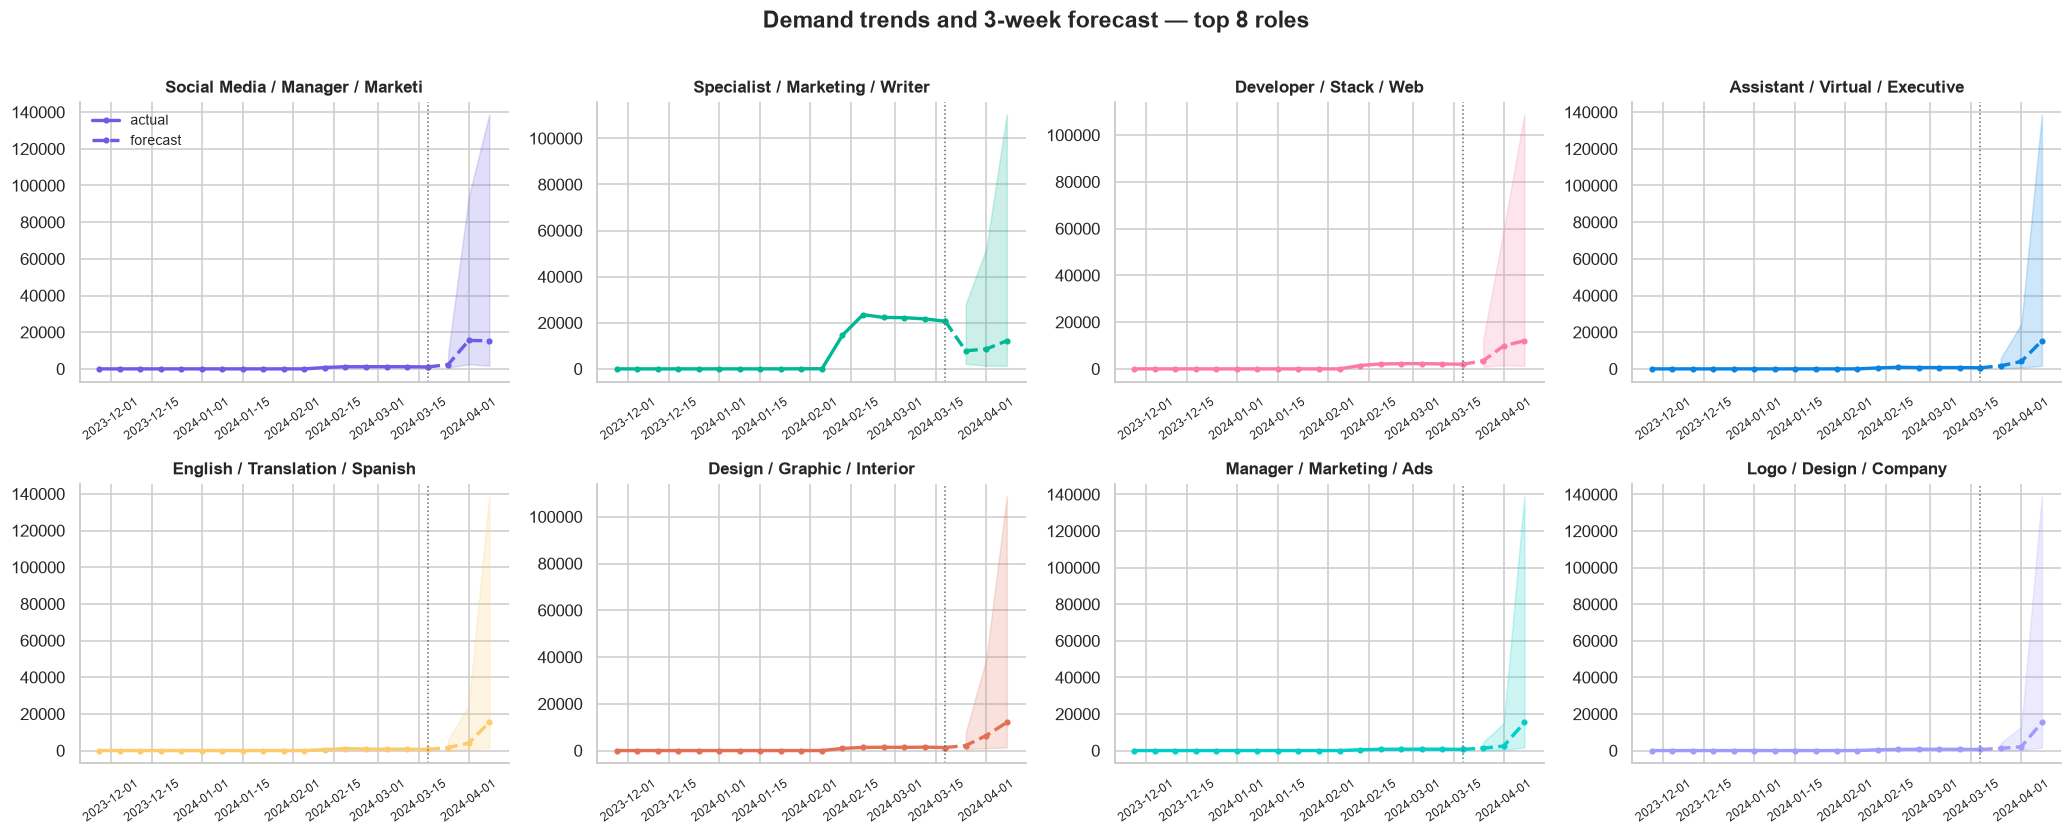

In [ ]:
# --- A. Demand trends + forecast for the 8 highest-demand roles (small multiples) ---
top8 = summary.head(8)["role"].tolist()
fig, axes = plt.subplots(2, 4, figsize=(19, 7.5))
for ax, role, col in zip(axes.ravel(), top8, PALETTE + PALETTE):
    hist = role_counts[role]
    ax.plot(hist.index, hist.values, color=col, lw=2.2, marker="o", ms=3, label="actual")
    ax.plot([hist.index[-1], *fc.index], [hist.iloc[-1], *fc[role].values], color=col, ls="--", lw=2.2, marker="o", ms=3, label="forecast")
    ax.fill_between(fc.index, lo[role], hi[role], color=col, alpha=.2)
    ax.axvline(hist.index[-1], color="#636e72", ls=":", lw=1)
    ax.set_title(role[:32], fontsize=11); ax.tick_params(axis="x", rotation=35, labelsize=8)
axes[0, 0].legend(frameon=False, fontsize=9)
fig.suptitle(f"Demand trends and {H}-{label} forecast — top 8 roles", fontweight="bold", fontsize=15, y=1.01)
fig.tight_layout()
show_fig(fig, "t3_a_demand_forecast")

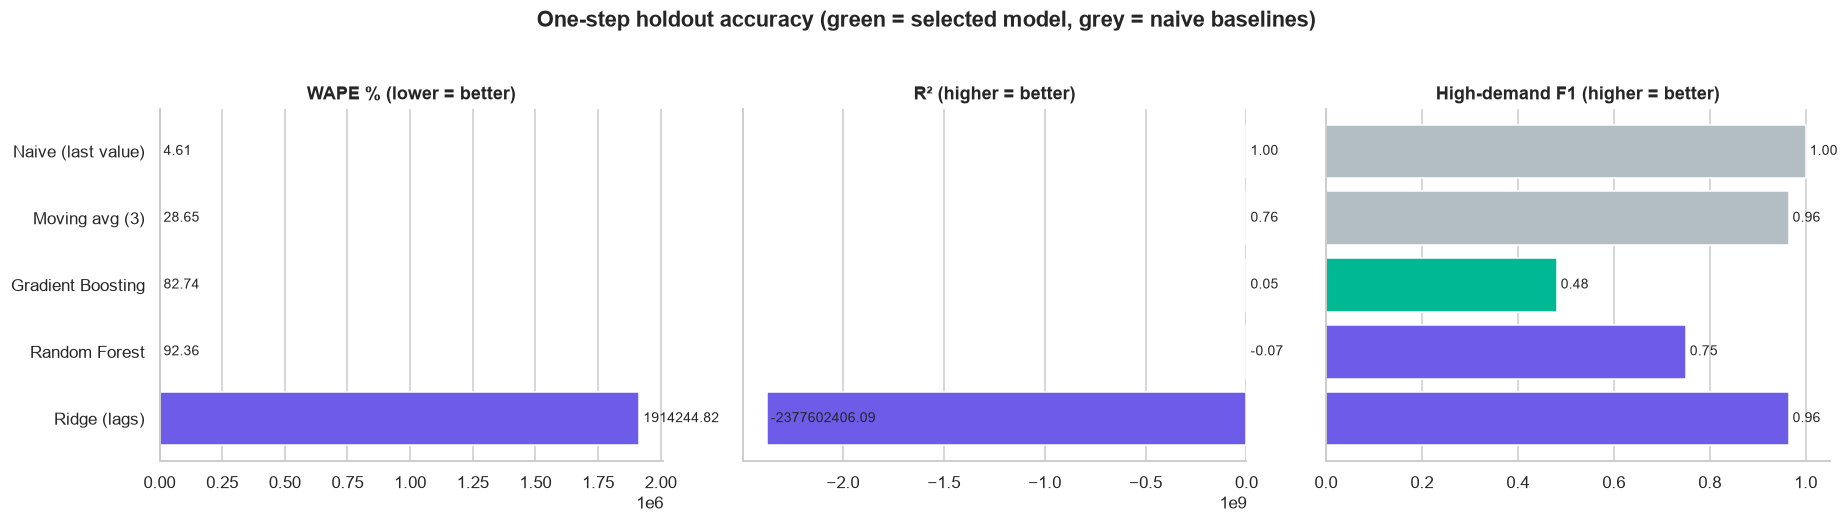

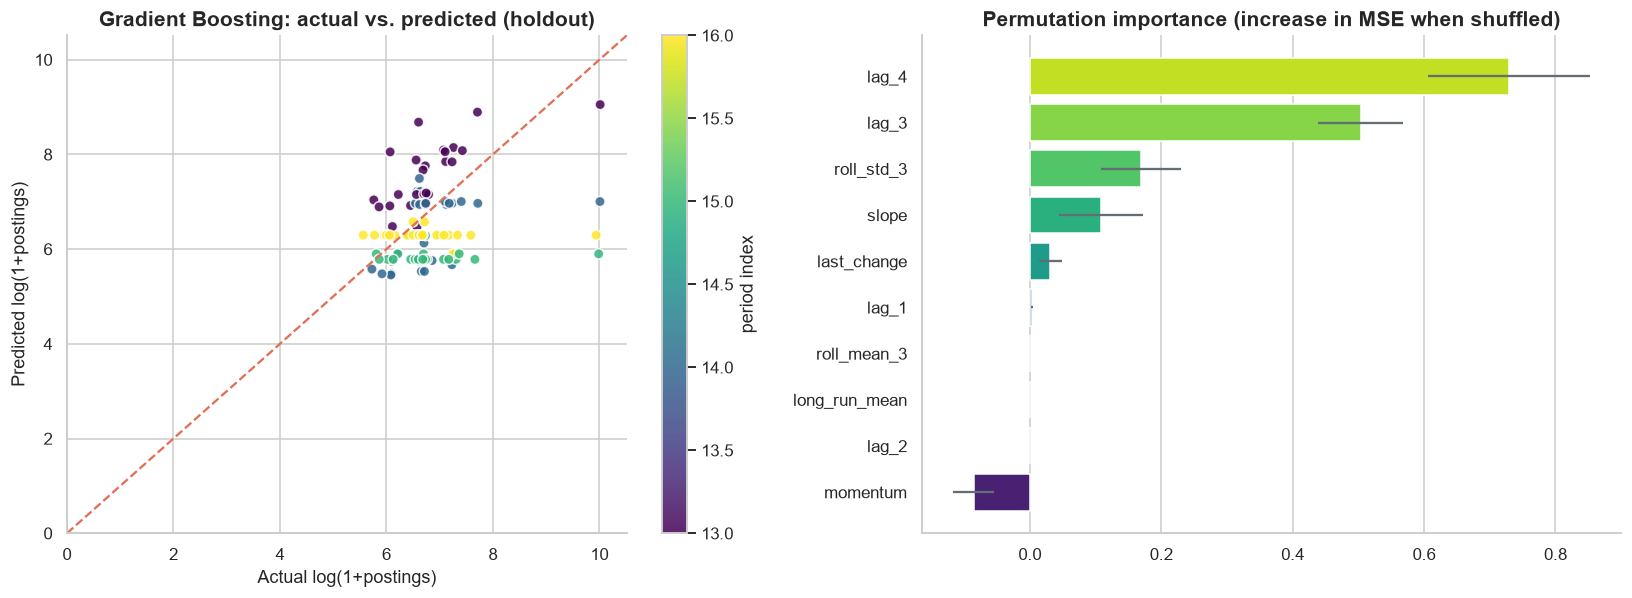

In [ ]:
# --- B. Model comparison ---
order = res.sort_values("WAPE_%").index
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, (metric, title, asc) in zip(axes, [("WAPE_%", "WAPE % (lower = better)", True),
                                          ("R2", "R² (higher = better)", False),
                                          ("HighDemand_F1", "High-demand F1 (higher = better)", False)]):
    vals = res.loc[order, metric]
    cols = [PALETTE[1] if n == best_name else PALETTE[0] if n in models else "#B2BEC3" for n in order]
    ax.barh(order, vals, color=cols, edgecolor="white")
    ax.invert_yaxis(); ax.set_title(title, fontsize=12); ax.grid(axis="y", visible=False)
    for i, v in enumerate(vals):
        ax.text(v, i, f" {v:.2f}", va="center", fontsize=9)
axes[1].set_yticklabels([]); axes[2].set_yticklabels([])
fig.suptitle("One-step holdout accuracy (green = selected model, grey = naive baselines)", fontweight="bold", y=1.03)
fig.tight_layout()
show_fig(fig, "t3_b_model_comparison")

# --- C. Actual vs predicted ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
pt = np.clip(preds[best_name], 0, None)
sc = axes[0].scatter(yte, pt, c=mte["t"], cmap="viridis", s=45, alpha=.85, edgecolor="white")
lim = [0, max(yte.max(), pt.max()) * 1.05]
axes[0].plot(lim, lim, color="#E17055", ls="--"); axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_xlabel("Actual log(1+postings)"); axes[0].set_ylabel("Predicted log(1+postings)")
axes[0].set_title(f"{best_name}: actual vs. predicted (holdout)")
plt.colorbar(sc, ax=axes[0], label="period index")
# --- D. Importance ---
d = imp_df.sort_values("importance")
axes[1].barh(d["feature"], d["importance"], xerr=d["std"], color=sns.color_palette("viridis", len(d)), ecolor="#636e72")
axes[1].set_title("Permutation importance (increase in MSE when shuffled)"); axes[1].grid(axis="y", visible=False)
fig.tight_layout()
show_fig(fig, "t3_c_fit_and_importance")

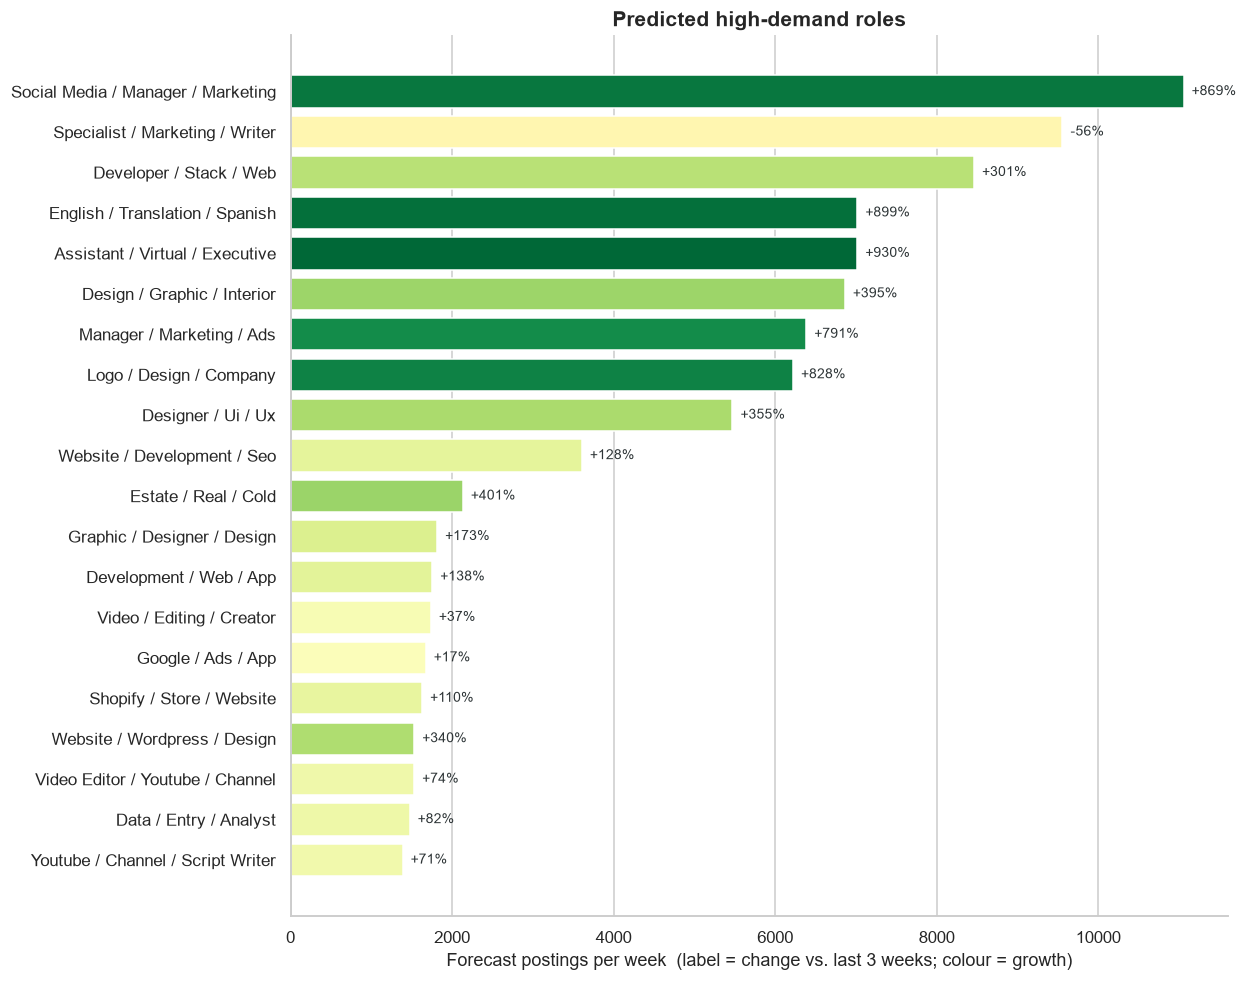

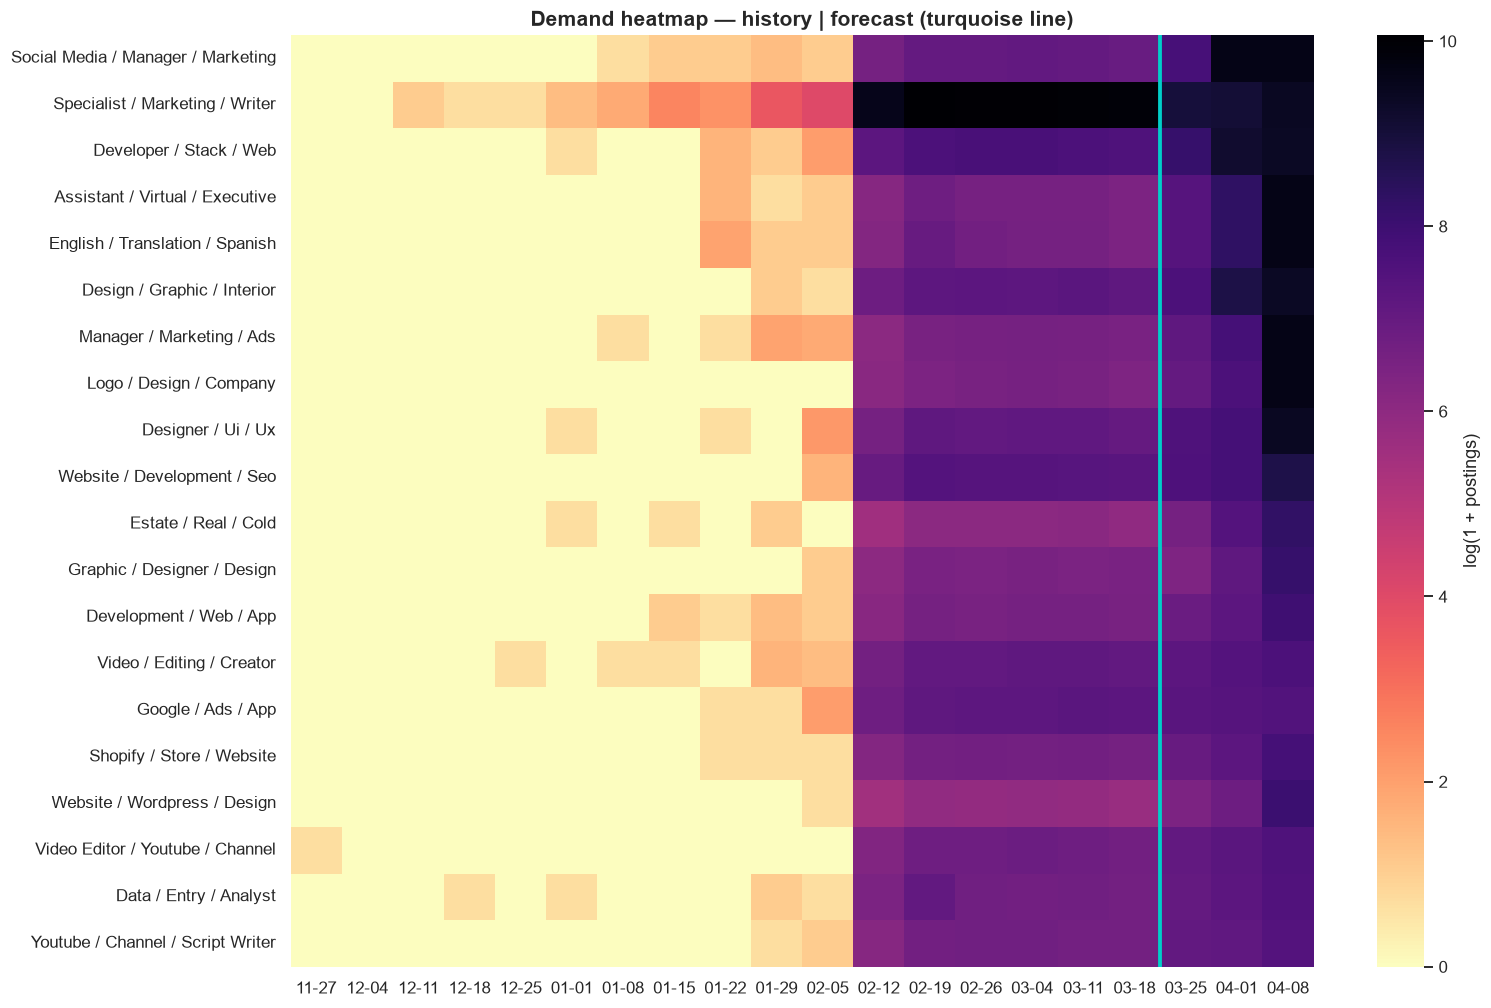

In [ ]:
# --- E. Forecast ranking ---
d = summary.head(TOP_K_ROLES * 2).sort_values("forecast_avg")
lim = max(abs(d["growth_pct"]).max(), 1)
colors = plt.get_cmap("RdYlGn")(plt.Normalize(-lim, lim)(d["growth_pct"]))
fig, ax = plt.subplots(figsize=(11, 0.42 * len(d) + 2))
ax.barh(d["role"], d["forecast_avg"], color=colors, edgecolor="white")
for i, (v, g) in enumerate(zip(d["forecast_avg"], d["growth_pct"])):
    ax.text(v, i, f"  {g:+.0f}%", va="center", fontsize=9, color="#2d3436")
ax.grid(axis="y", visible=False)
ax.set_xlabel(f"Forecast postings per {label}  (label = change vs. last {H} {label}s; colour = growth)")
ax.set_title("Predicted high-demand roles")
show_fig(fig, "t3_d_forecast_ranking")

# --- F. Demand heatmap incl. forecast ---
order20 = summary.head(20)["role"]
comb = pd.concat([role_counts[order20], fc[order20]]).T
fmt = "%Y-%m" if freq == "M" else "%m-%d"
step = max(1, comb.shape[1] // 12)
xl = [d_.strftime(fmt) if i % step == 0 else "" for i, d_ in enumerate(comb.columns)]
fig, ax = plt.subplots(figsize=(15, 0.4 * len(order20) + 3))
sns.heatmap(np.log1p(comb), cmap="magma_r", ax=ax, xticklabels=xl, cbar_kws={"label": "log(1 + postings)"})
ax.axvline(len(role_counts), color="#00CEC9", lw=2.5)
ax.set_title("Demand heatmap — history | forecast (turquoise line)"); ax.set_xlabel(""); ax.set_ylabel("")
show_fig(fig, "t3_e_demand_heatmap")

In [ ]:
# --- G. Interactive: all top roles, actual + forecast ---
figp = go.Figure()
for i, role in enumerate(summary.head(TOP_K_ROLES)["role"]):
    col = PALETTE[i % len(PALETTE)]
    hist = role_counts[role]
    figp.add_trace(go.Scatter(x=hist.index, y=hist.values, mode="lines+markers", name=role, legendgroup=role,
                              line=dict(color=col, width=2.5)))
    figp.add_trace(go.Scatter(x=[hist.index[-1], *fc.index], y=[hist.iloc[-1], *fc[role].values], mode="lines+markers",
                              name=f"{role} (forecast)", legendgroup=role, showlegend=False,
                              line=dict(color=col, width=2.5, dash="dash")))
figp.update_layout(template="plotly_white", title=f"Demand trends and forecast — top {TOP_K_ROLES} roles (click legend to toggle)",
                   yaxis_title=f"Postings per {label}", hovermode="x unified")
figp.show()

Results

In [ ]:
print(f"Selected model: {best_name}  |  one-step holdout WAPE = {res.loc[best_name, 'WAPE_%']:.1f}%, "
      f"R² = {res.loc[best_name, 'R2']:.2f}, high-demand F1 = {res.loc[best_name, 'HighDemand_F1']:.2f}")
base = res.loc[["Naive (last value)", "Moving avg (3)"], "WAPE_%"].min()
print("Beats the best naive baseline." if res.loc[best_name, "WAPE_%"] < base else
      "Does NOT beat the best naive baseline - treat the forecast as indicative only.")

print("\nPredicted HIGH-DEMAND roles:")
display(summary[summary["high_demand"]][["rank", "role", "recent_avg", "forecast_avg", "growth_pct", "demand_share_pct", "trend"]])
print("Fastest-RISING roles among those with meaningful volume:")
display(summary[summary["recent_avg"] >= summary["recent_avg"].median()].nlargest(5, "growth_pct")
        [["role", "recent_avg", "forecast_avg", "growth_pct", "trend"]])

res.to_csv(OUTPUT_DIR / "tables" / "task3_model_comparison.csv")
if backtest is not None:
    backtest.to_csv(OUTPUT_DIR / "tables" / "task3_backtest.csv")
summary.to_csv(OUTPUT_DIR / "tables" / "task3_role_forecast.csv", index=False)
fc.reset_index().rename(columns={"index": "period"}).to_csv(OUTPUT_DIR / "tables" / "task3_forecast_by_period.csv", index=False)

Selected model: Gradient Boosting  |  one-step holdout WAPE = 82.7%, R² = 0.05, high-demand F1 = 0.48
Does NOT beat the best naive baseline - treat the forecast as indicative only.

Predicted HIGH-DEMAND roles:


,rank,role,recent_avg,forecast_avg,growth_pct,demand_share_pct,trend
0,1,Social Media / Manager / Marketing,"1,141.00","11,056.51",868.64,11.95,Rising
1,2,Specialist / Marketing / Writer,"21,526.33","9,556.95",-55.60,10.33,Falling
2,3,Developer / Stack / Web,"2,110.00","8,462.07",300.97,9.14,Rising
3,4,Assistant / Virtual / Executive,681.00,"7,017.77",929.83,7.58,Rising
4,5,English / Translation / Spanish,702.33,"7,017.77",898.57,7.58,Rising
5,6,Design / Graphic / Interior,"1,384.67","6,862.54",395.47,7.41,Rising
6,7,Manager / Marketing / Ads,716.33,"6,385.28",790.83,6.90,Rising


Fastest-RISING roles among those with meaningful volume:


,role,recent_avg,forecast_avg,growth_pct,trend
0,Social Media / Manager / Marketing,"1,141.00","11,056.51",868.64,Rising
5,Design / Graphic / Interior,"1,384.67","6,862.54",395.47,Rising
8,Designer / Ui / Ux,"1,202.67","5,471.72",354.82,Rising
2,Developer / Stack / Web,"2,110.00","8,462.07",300.97,Rising
9,Website / Development / Seo,"1,584.33","3,606.96",127.62,Rising


**Reading the results:** compare the learned models with the naive baselines first — if they do not clearly win, the history is too short or too noisy for more than a trend-following forecast.
The backtest is the most honest number because it forecasts several periods without seeing them. Bands are approximate; demand shocks (seasonality, platform changes) are not modelled,
and with only a few months of data seasonality cannot be learned at all.

## 8. Task 4 — Compare average hourly rates across countries

**Goal:** compare the hourly rates offered in different countries, with an interactive map/charts.

**Method**
1. Use hourly postings only (fixed-price budgets are a different unit), excluding flagged outliers.
2. Per country: number of postings, mean, **median**, 10%-trimmed mean, spread (IQR), and a distribution-free 95% confidence interval for the median.
3. Test whether countries differ (Kruskal-Wallis) and whether each country differs from the rest (Mann-Whitney with FDR correction).
4. **Mix adjustment:** countries post different kinds of jobs, so also compute each country's premium *after* removing the typical pay of each job category.
5. Interactive world maps + ranked and distribution charts.

> Countries with fewer than `MIN_COUNTRY_N` hourly postings are excluded from rankings — small samples give unreliable averages.

PArameters and DAta

In [ ]:
# ---- Task 4 parameters
MIN_COUNTRY_N        = 30     # a country needs >= N hourly postings to be ranked / mapped
MIN_CELL_N           = 10     # minimum postings for a country x category cell in the heatmap
INCLUDE_PAY_OUTLIERS = False  # keep the 1st/99th-percentile outliers?
BARS_EACH_SIDE       = 15     # countries shown at the top and bottom of the ranking chart

assert "country" in df.columns, "Task 4 needs a country column - set COLS['country'] in the configuration cell."
hr = df[(df["salary_basis"] == "hourly") & df["country"].notna()].copy()
if not INCLUDE_PAY_OUTLIERS:
    hr = hr[~hr["pay_outlier"]]
assert len(hr) > 0, "No hourly postings with a country were found."
hr["log_rate"] = np.log(hr["salary_value"])
global_median = hr["salary_value"].median()
print(f"Hourly postings used: {len(hr):,} | countries: {hr['country'].nunique():,} | global median: {global_median:,.2f} per hour")

Hourly postings used: 98,497 | countries: 191 | global median: 22.50 per hour


Country Statistics

In [ ]:
rows = []
for country, g in hr.groupby("country"):
    v = np.sort(g["salary_value"].values); n = len(v)
    if n < MIN_COUNTRY_N:
        continue
    lo_i = max(int(np.floor(n / 2 - 0.98 * np.sqrt(n))), 0)         # distribution-free CI for the median
    hi_i = min(int(np.ceil(n / 2 + 0.98 * np.sqrt(n))), n - 1)       # (order-statistic method, 95%)
    rest = hr.loc[hr["country"] != country, "log_rate"].values
    _, p = stats.mannwhitneyu(g["log_rate"].values, rest, alternative="two-sided", method="asymptotic")
    rows.append({"country": country, "n": n, "mean_rate": v.mean(), "median_rate": np.median(v),
                 "trimmed_mean": stats.trim_mean(v, 0.1), "std": v.std(ddof=1),
                 "p25": np.percentile(v, 25), "p75": np.percentile(v, 75),
                 "ci_low": v[lo_i], "ci_high": v[hi_i], "p_value": p})
ctry = pd.DataFrame(rows)
assert len(ctry) >= 2, f"Fewer than 2 countries have >= {MIN_COUNTRY_N} hourly postings - lower MIN_COUNTRY_N."
ctry["vs_global_pct"] = (ctry["median_rate"] / global_median - 1) * 100
ctry["q_value"] = bh_fdr(ctry["p_value"].values)
ctry["differs_from_rest"] = ctry["q_value"] < ALPHA

# --- mix adjustment: remove the typical pay of each job category (categories from Task 2) ---
hr["category"] = t2["category"].reindex(hr.index)
hh = hr.dropna(subset=["category"]).copy()
hh["resid"] = hh["log_rate"] - hh.groupby("category")["log_rate"].transform("mean")
ctry["mix_adj_premium_pct"] = (np.exp(ctry["country"].map(hh.groupby("country")["resid"].mean())) - 1) * 100

# --- are countries different at all? ---
groups = [g["log_rate"].values for _, g in hr.groupby("country") if len(g) >= MIN_COUNTRY_N]
H_stat, kw_p = stats.kruskal(*groups)
eps2 = (H_stat - len(groups) + 1) / (sum(map(len, groups)) - len(groups))
ctry = ctry.sort_values("median_rate", ascending=False).reset_index(drop=True)
excluded = hr["country"].nunique() - len(ctry)
print(f"Countries ranked: {len(ctry)} (excluded {excluded} with < {MIN_COUNTRY_N} postings)")
print(f"Kruskal-Wallis: H = {H_stat:,.1f}, p = {kw_p:.2e}, effect size epsilon² = {eps2:.3f} "
      f"-> country explains about {max(eps2, 0) * 100:.1f}% of the rank variation in hourly rates")
ctry.round(2).head(10)

Countries ranked: 92 (excluded 99 with < 30 postings)
Kruskal-Wallis: H = 2,461.0, p = 0.00e+00, effect size epsilon² = 0.024 -> country explains about 2.4% of the rank variation in hourly rates


,country,n,mean_rate,median_rate,trimmed_mean,std,p25,p75,ci_low,ci_high,p_value,vs_global_pct,q_value,differs_from_rest,mix_adj_premium_pct
0,Latvia,110,31.97,30.00,29.55,19.17,20.00,41.88,25.00,32.50,0.00,33.33,0.00,True,24.73
1,Oman,49,29.93,29.00,28.02,14.09,19.50,33.50,25.00,32.50,0.02,28.89,0.05,True,24.47
2,Vietnam,252,30.02,27.50,26.70,19.63,17.50,27.50,27.50,27.50,0.00,22.22,0.00,True,10.74
3,Kenya,364,30.36,26.50,28.21,18.16,18.25,37.50,25.00,30.00,0.00,17.78,0.00,True,14.91
4,Morocco,142,26.94,25.00,24.71,16.11,18.62,30.00,22.50,26.00,0.20,11.11,0.32,False,9.91
5,Nepal,60,22.81,25.00,22.16,13.41,16.25,26.38,20.00,25.00,0.39,11.11,0.54,False,-8.78
6,Saudi Arabia,418,28.44,25.00,26.57,18.05,16.50,37.50,22.50,25.50,0.01,11.11,0.02,True,4.82
7,Poland,413,27.36,25.00,24.83,18.94,15.00,35.00,22.50,25.00,0.22,11.11,0.36,False,0.90
8,Albania,44,27.08,25.00,24.93,19.63,15.00,27.75,16.50,26.00,0.89,11.11,0.94,False,-3.44
9,Bosnia And Herzegovina,39,28.33,25.00,24.48,24.35,14.25,32.50,18.50,30.00,0.95,11.11,0.97,False,-5.40


### 8.3 Interactive world maps
Country names are converted to ISO-3 codes (uses `pycountry` if installed, otherwise Plotly's built-in country table plus common aliases).

In [ ]:
try:
    import pycountry
except ImportError:
    pycountry = None
try:
    GAP = {c.lower(): iso for c, iso in px.data.gapminder()[["country", "iso_alpha"]].drop_duplicates().values}
except Exception:
    GAP = {}

ALIASES = {"united states": "USA", "usa": "USA", "united kingdom": "GBR", "uk": "GBR", "russia": "RUS",
           "russian federation": "RUS", "south korea": "KOR", "korea, republic of": "KOR", "north korea": "PRK",
           "vietnam": "VNM", "viet nam": "VNM", "turkey": "TUR", "türkiye": "TUR", "turkiye": "TUR",
           "czech republic": "CZE", "czechia": "CZE", "iran": "IRN", "syria": "SYR", "taiwan": "TWN",
           "venezuela": "VEN", "bolivia": "BOL", "tanzania": "TZA", "moldova": "MDA", "laos": "LAO",
           "brunei": "BRN", "macedonia": "MKD", "north macedonia": "MKD", "congo": "COG",
           "democratic republic of the congo": "COD", "ivory coast": "CIV", "cote d'ivoire": "CIV",
           "côte d'ivoire": "CIV", "hong kong": "HKG", "macao": "MAC", "macau": "MAC",
           "united arab emirates": "ARE", "uae": "ARE", "palestine": "PSE", "cape verde": "CPV",
           "swaziland": "SWZ", "eswatini": "SWZ", "myanmar": "MMR", "burma": "MMR", "kosovo": "XKX"}

def to_iso3(name):
    key = str(name).strip().lower()
    if key in ALIASES:
        return ALIASES[key]
    if pycountry is not None:
        try:
            return pycountry.countries.lookup(name).alpha_3
        except LookupError:
            try:
                return pycountry.countries.search_fuzzy(name)[0].alpha_3
            except LookupError:
                return GAP.get(key)
    return GAP.get(key)

ctry["iso3"] = ctry["country"].map(to_iso3)
unmapped = ctry.loc[ctry["iso3"].isna(), "country"].tolist()
print(f"Mapped {ctry['iso3'].notna().sum()} of {len(ctry)} countries" + (f" | not on the map: {unmapped}" if unmapped else ""))
cm = ctry.dropna(subset=["iso3"])

hover = {"iso3": False, "n": ":,", "mean_rate": ":.1f", "median_rate": ":.1f", "p25": ":.1f", "p75": ":.1f", "vs_global_pct": ":+.0f"}
labels = {"median_rate": "Median $/hr", "n": "Postings", "mean_rate": "Mean $/hr", "p25": "25th pct", "p75": "75th pct",
          "vs_global_pct": "vs. global median %"}

px.choropleth(cm, locations="iso3", color="median_rate", hover_name="country", hover_data=hover, labels=labels,
              color_continuous_scale="Turbo", projection="natural earth",
              title=f"Median hourly rate by country (countries with >= {MIN_COUNTRY_N} postings)"
              ).update_layout(template="plotly_white", margin=dict(l=0, r=0, t=50, b=0)).show()

lim = max(abs(cm["vs_global_pct"]).max(), 1)
px.choropleth(cm, locations="iso3", color="vs_global_pct", hover_name="country", hover_data=hover, labels=labels,
              color_continuous_scale="RdYlGn", range_color=(-lim, lim), projection="natural earth",
              title="Hourly rate premium / discount vs. the global median (%)"
              ).update_layout(template="plotly_white", margin=dict(l=0, r=0, t=50, b=0)).show()

px.choropleth(cm, locations="iso3", color="n", hover_name="country", labels=labels, color_continuous_scale="Sunsetdark",
              projection="natural earth", title="Where the postings are: number of hourly postings by country"
              ).update_layout(template="plotly_white", margin=dict(l=0, r=0, t=50, b=0)).show()

Mapped 80 of 92 countries | not on the map: ['Latvia', 'Cyprus', 'Ukraine', 'Lithuania', 'Luxembourg', 'Qatar', 'Georgia', 'Slovakia', 'Armenia', 'Estonia', 'Uzbekistan', 'Malta']


Charts

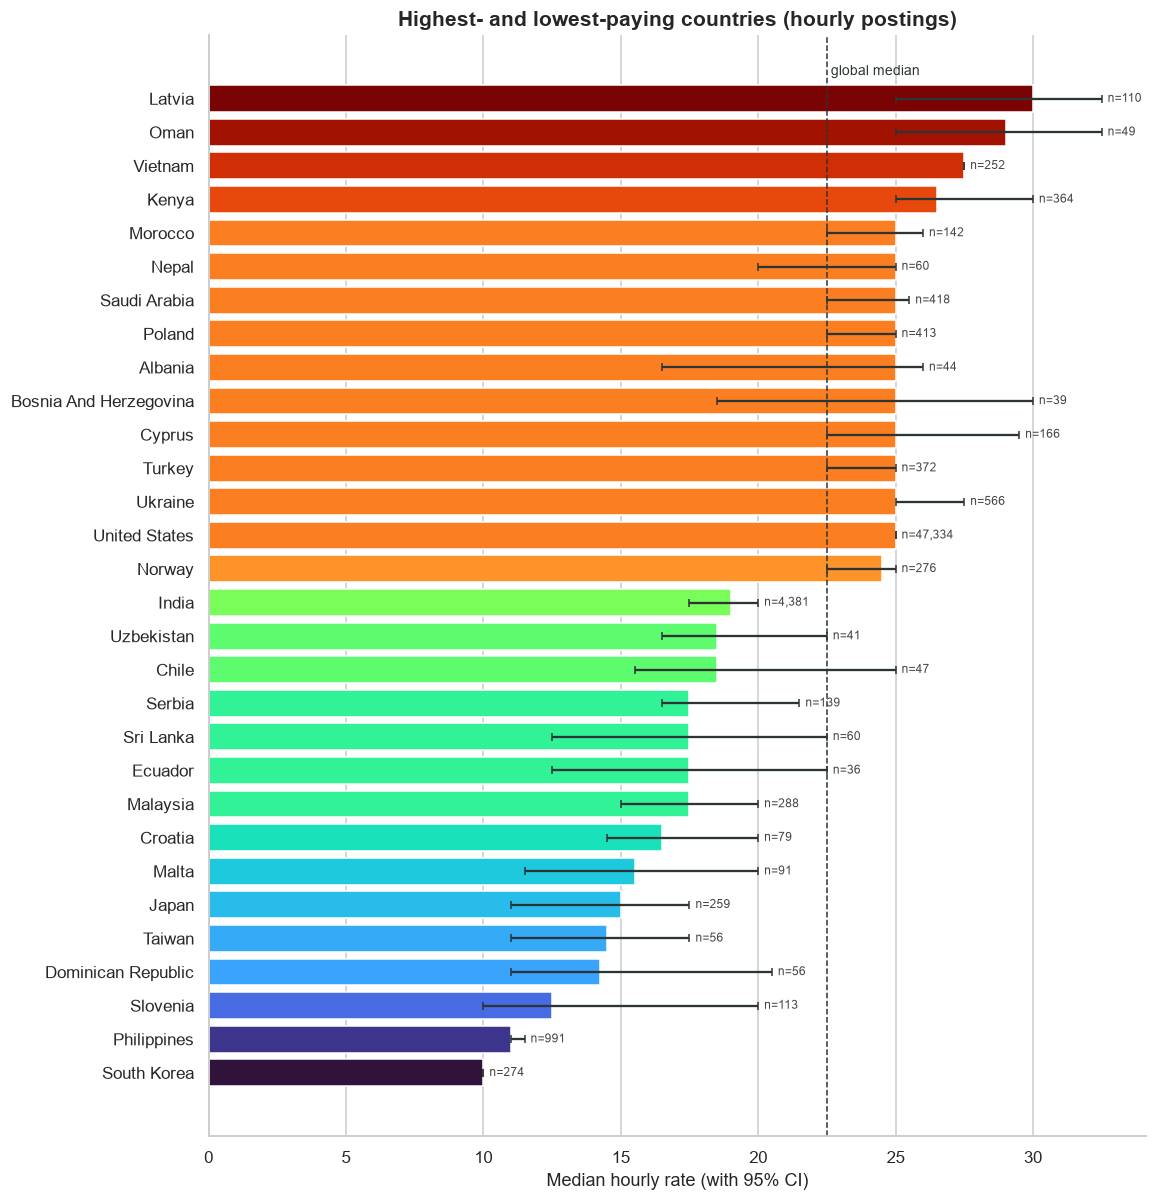

In [ ]:
# --- A. Ranking: highest and lowest median rates with 95% CI ---
sel = pd.concat([ctry.head(BARS_EACH_SIDE), ctry.tail(BARS_EACH_SIDE)]).drop_duplicates("country").iloc[::-1]
colors = plt.get_cmap("turbo")(plt.Normalize(sel["median_rate"].min(), sel["median_rate"].max())(sel["median_rate"]))
err = [sel["median_rate"] - sel["ci_low"], sel["ci_high"] - sel["median_rate"]]
fig, ax = plt.subplots(figsize=(11, 0.36 * len(sel) + 2.2))
ax.barh(sel["country"], sel["median_rate"], xerr=err, color=colors, ecolor="#2d3436", capsize=2.5, edgecolor="white")
for i, (v, n) in enumerate(zip(sel["ci_high"], sel["n"])):
    ax.text(v, i, f"  n={n:,}", va="center", fontsize=8, color="#444")
ax.axvline(global_median, color="#2d3436", ls="--", lw=1)
ax.text(global_median, len(sel) - 0.3, " global median", fontsize=9, color="#2d3436")
ax.grid(axis="y", visible=False); ax.set_xlabel("Median hourly rate (with 95% CI)")
ax.set_title("Highest- and lowest-paying countries (hourly postings)")
show_fig(fig, "t4_a_country_ranking")

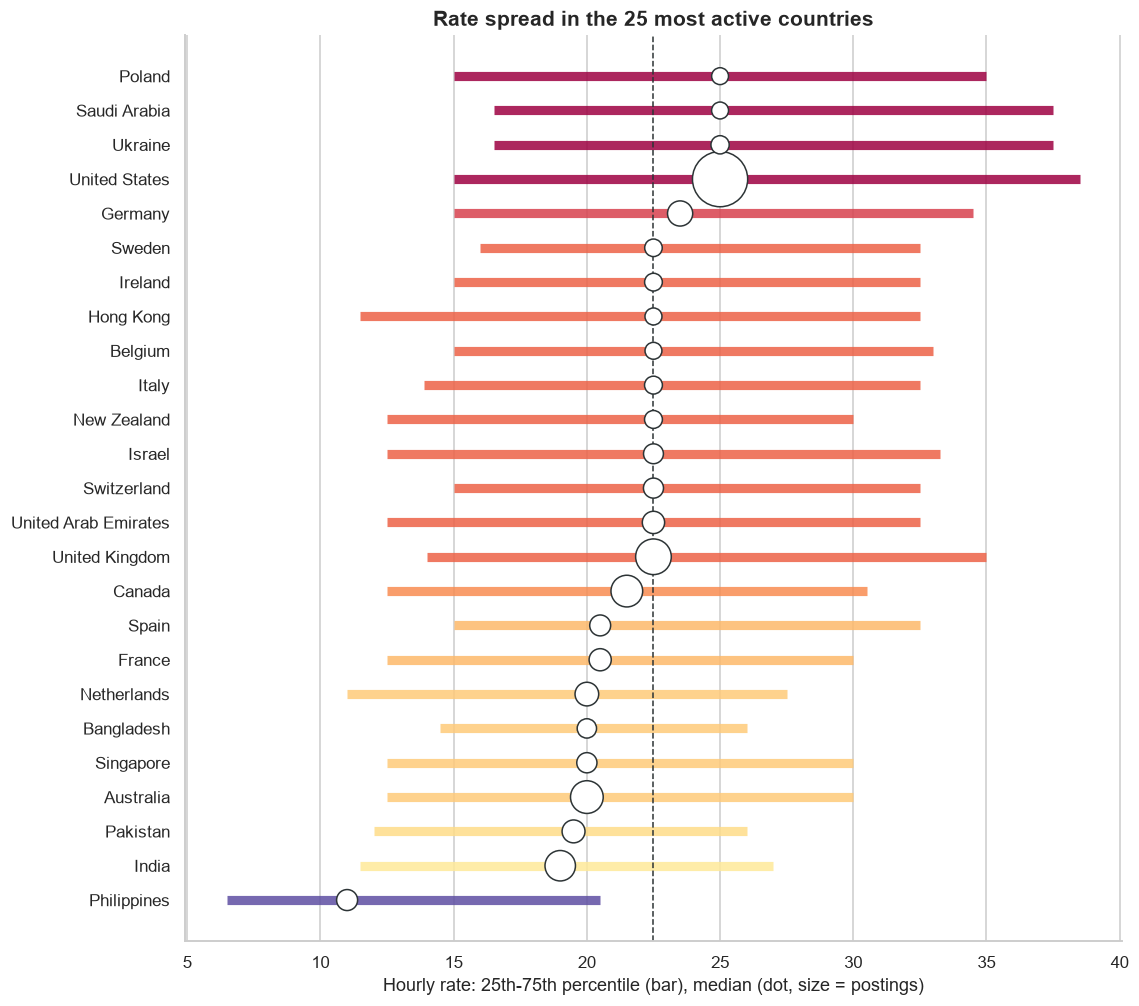

In [ ]:
# --- B. Spread of rates in the 25 most active countries (median dot, IQR bar) ---
act = ctry.nlargest(25, "n").sort_values("median_rate")
fig, ax = plt.subplots(figsize=(11, 0.34 * len(act) + 2.2))
cols = plt.get_cmap("Spectral_r")(plt.Normalize(act["median_rate"].min(), act["median_rate"].max())(act["median_rate"]))
ax.hlines(act["country"], act["p25"], act["p75"], colors=cols, lw=6, alpha=.85)
ax.scatter(act["median_rate"], act["country"], s=np.sqrt(act["n"]) * 6, color="white", edgecolor="#2d3436", zorder=3)
ax.axvline(global_median, color="#2d3436", ls="--", lw=1)
ax.set_xlabel("Hourly rate: 25th-75th percentile (bar), median (dot, size = postings)")
ax.set_title("Rate spread in the 25 most active countries"); ax.grid(axis="y", visible=False)
show_fig(fig, "t4_b_rate_spread")

# --- C. Volume vs rate (interactive) ---
px.scatter(ctry, x="n", y="median_rate", size="n", color="median_rate", hover_name="country", log_x=True, size_max=45,
           color_continuous_scale="Turbo", labels={"n": "Hourly postings (log)", "median_rate": "Median $/hr"},
           hover_data={"mean_rate": ":.1f", "vs_global_pct": ":+.0f", "mix_adj_premium_pct": ":+.0f"},
           title="Demand volume vs. pay level by country").update_layout(template="plotly_white").show()

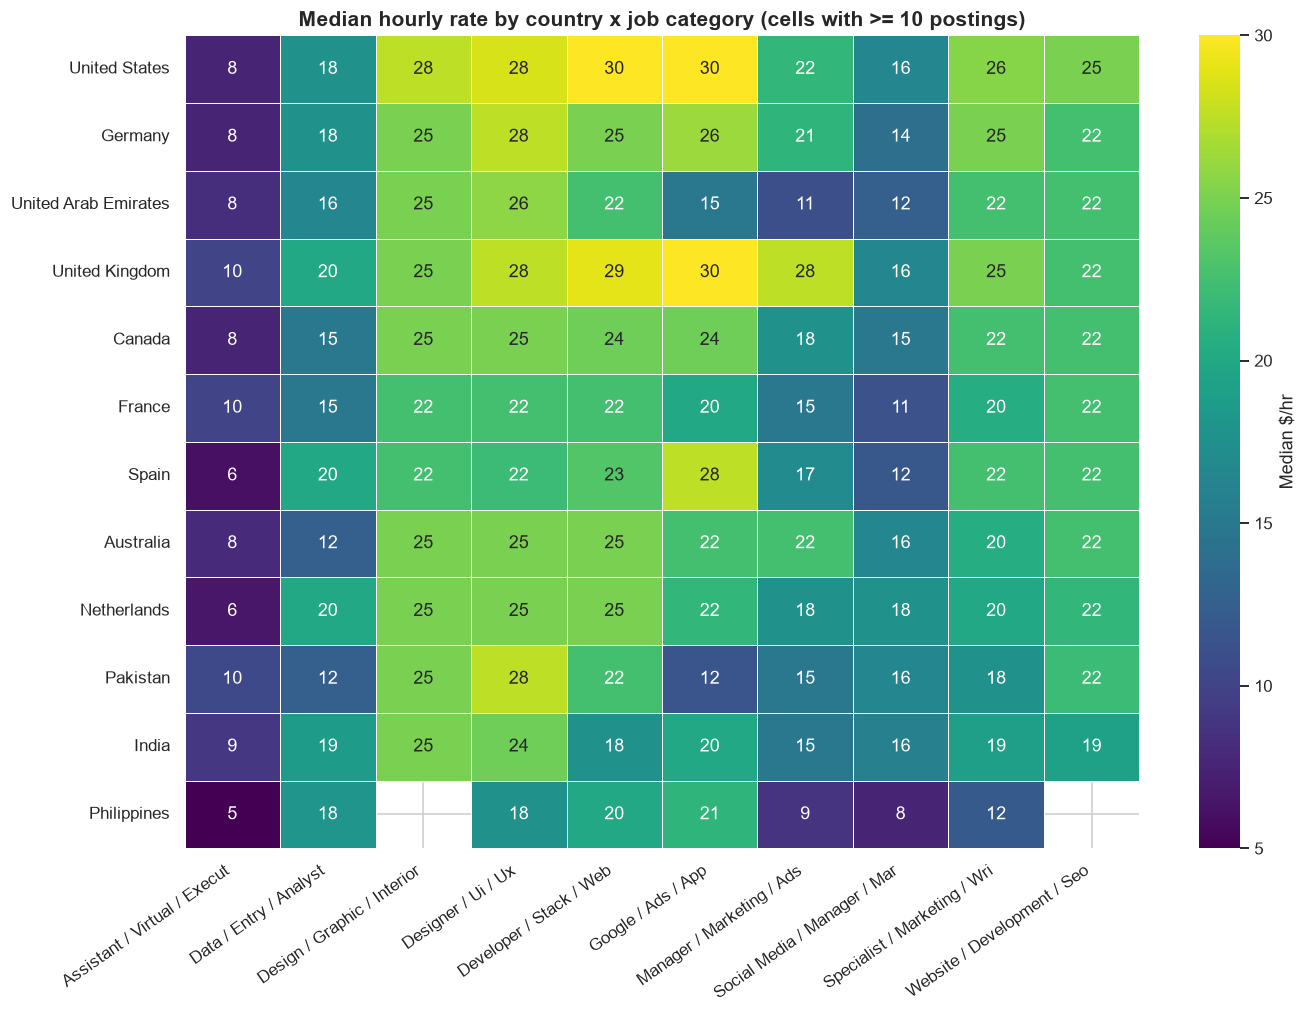

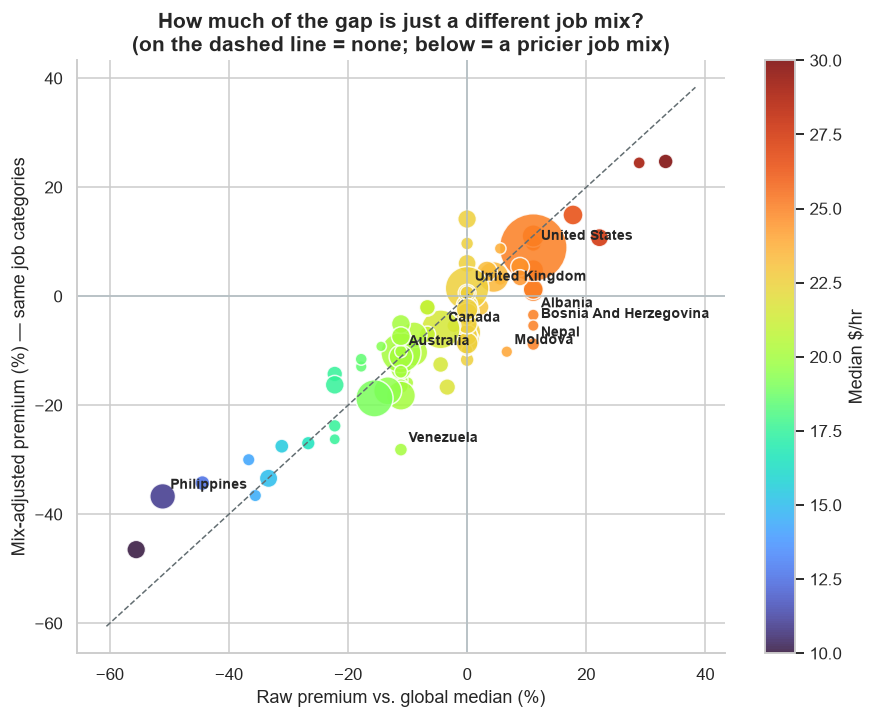

In [ ]:
# --- D. Country x category heatmap (median $/hr) ---
top_c = ctry.nlargest(12, "n")["country"].tolist()
top_cat = hh["category"].value_counts().head(10).index
sub = hh[hh["country"].isin(top_c) & hh["category"].isin(top_cat)]
med = sub.pivot_table(index="country", columns="category", values="salary_value", aggfunc="median")
cnt = sub.pivot_table(index="country", columns="category", values="salary_value", aggfunc="size")
med = med.where(cnt >= MIN_CELL_N).loc[ctry.set_index("country").loc[top_c].sort_values("median_rate", ascending=False).index]
med.columns = [c[:28] for c in med.columns]
fig, ax = plt.subplots(figsize=(14, 0.55 * len(med) + 3))
sns.heatmap(med, annot=True, fmt=".0f", cmap="viridis", linewidths=.5, ax=ax, cbar_kws={"label": "Median $/hr"})
ax.set_title(f"Median hourly rate by country x job category (cells with >= {MIN_CELL_N} postings)")
ax.set_xlabel(""); ax.set_ylabel(""); plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
show_fig(fig, "t4_c_country_category_heatmap")

# --- E. Raw vs mix-adjusted premium ---
d = ctry.dropna(subset=["mix_adj_premium_pct"])
fig, ax = plt.subplots(figsize=(9.5, 7))
sc = ax.scatter(d["vs_global_pct"], d["mix_adj_premium_pct"], s=np.sqrt(d["n"]) * 9, c=d["median_rate"],
                cmap="turbo", alpha=.85, edgecolor="white")
lims = [min(d["vs_global_pct"].min(), d["mix_adj_premium_pct"].min()) - 5, max(d["vs_global_pct"].max(), d["mix_adj_premium_pct"].max()) + 5]
ax.plot(lims, lims, color="#636e72", ls="--", lw=1); ax.axhline(0, color="#b2bec3", lw=1); ax.axvline(0, color="#b2bec3", lw=1)
gap = (d["vs_global_pct"] - d["mix_adj_premium_pct"]).abs().nlargest(6).index
for i in set(d.nlargest(4, "n").index) | set(gap):
    ax.annotate(d.loc[i, "country"], (d.loc[i, "vs_global_pct"], d.loc[i, "mix_adj_premium_pct"]), xytext=(5, 5),
                textcoords="offset points", fontsize=9, fontweight="bold")
ax.set_xlabel("Raw premium vs. global median (%)"); ax.set_ylabel("Mix-adjusted premium (%) — same job categories")
ax.set_title("How much of the gap is just a different job mix?\n(on the dashed line = none; below = a pricier job mix)")
plt.colorbar(sc, ax=ax, label="Median $/hr")
show_fig(fig, "t4_d_raw_vs_adjusted")

Results

In [ ]:
cols = ["country", "n", "median_rate", "mean_rate", "trimmed_mean", "p25", "p75", "vs_global_pct", "mix_adj_premium_pct", "q_value"]
fmtq = lambda t: t.assign(q_value=t["q_value"].map(lambda q: "<0.001" if q < 0.001 else f"{q:.3f}"))
print(f"Overall: global median = {global_median:,.2f}/hr; country differences are "
      f"{'statistically significant' if kw_p < ALPHA else 'not significant'} (Kruskal-Wallis p = {kw_p:.2e}).")
print("\nHighest median hourly rates:")
display(fmtq(ctry.head(10)[cols]))
print("Lowest median hourly rates:")
display(fmtq(ctry.tail(10)[cols].iloc[::-1]))
print("Most postings (largest markets):")
display(fmtq(ctry.nlargest(10, "n")[cols]))

ctry.to_csv(OUTPUT_DIR / "tables" / "task4_country_hourly_rates.csv", index=False)

Overall: global median = 22.50/hr; country differences are statistically significant (Kruskal-Wallis p = 0.00e+00).

Highest median hourly rates:


,country,n,median_rate,mean_rate,trimmed_mean,p25,p75,vs_global_pct,mix_adj_premium_pct,q_value
0,Latvia,110,30.00,31.97,29.55,20.00,41.88,33.33,24.73,<0.001
1,Oman,49,29.00,29.93,28.02,19.50,33.50,28.89,24.47,0.047
2,Vietnam,252,27.50,30.02,26.70,17.50,27.50,22.22,10.74,0.003
3,Kenya,364,26.50,30.36,28.21,18.25,37.50,17.78,14.91,<0.001
4,Morocco,142,25.00,26.94,24.71,18.62,30.00,11.11,9.91,0.324
5,Nepal,60,25.00,22.81,22.16,16.25,26.38,11.11,-8.78,0.541
6,Saudi Arabia,418,25.00,28.44,26.57,16.50,37.50,11.11,4.82,0.018
7,Poland,413,25.00,27.36,24.83,15.00,35.00,11.11,0.90,0.356
8,Albania,44,25.00,27.08,24.93,15.00,27.75,11.11,-3.44,0.940
9,Bosnia And Herzegovina,39,25.00,28.33,24.48,14.25,32.50,11.11,-5.40,0.968


Lowest median hourly rates:


,country,n,median_rate,mean_rate,trimmed_mean,p25,p75,vs_global_pct,mix_adj_premium_pct,q_value
91,South Korea,274,10.00,15.03,11.87,10.00,15.00,-55.56,-46.49,<0.001
90,Philippines,991,11.00,20.07,13.80,6.50,20.50,-51.11,-36.72,<0.001
89,Slovenia,113,12.50,19.38,16.77,8.00,26.00,-44.44,-34.28,<0.001
88,Dominican Republic,56,14.25,19.37,17.14,5.50,26.12,-36.67,-29.99,0.001
87,Taiwan,56,14.50,15.68,15.01,10.00,20.62,-35.56,-36.56,<0.001
86,Japan,259,15.00,18.71,16.39,10.00,22.75,-33.33,-33.41,<0.001
85,Malta,91,15.50,20.37,18.10,6.75,28.75,-31.11,-27.52,<0.001
84,Croatia,79,16.50,19.29,17.84,10.50,27.50,-26.67,-26.96,0.001
83,Malaysia,288,17.50,26.94,19.89,7.88,30.00,-22.22,-16.26,<0.001
82,Ecuador,36,17.50,20.38,17.77,11.12,23.12,-22.22,-26.24,0.034


Most postings (largest markets):


,country,n,median_rate,mean_rate,trimmed_mean,p25,p75,vs_global_pct,mix_adj_premium_pct,q_value
13,United States,47334,25.00,29.99,26.66,15.00,38.50,11.11,8.94,<0.001
31,United Kingdom,8226,22.50,27.58,24.36,14.00,35.00,0.00,1.45,0.362
67,Australia,5833,20.00,23.89,21.44,12.50,30.00,-11.11,-10.37,<0.001
52,Canada,5148,21.50,25.01,22.17,12.50,30.50,-4.44,-6.08,<0.001
77,India,4381,19.00,21.71,19.58,11.50,27.00,-15.56,-18.73,<0.001
19,Germany,2049,23.50,27.23,24.64,15.00,34.50,4.44,3.52,0.019
73,Netherlands,1596,20.00,21.96,19.79,11.00,27.50,-11.11,-18.24,<0.001
75,Pakistan,1404,19.50,22.43,19.54,12.00,26.00,-13.33,-17.35,<0.001
28,United Arab Emirates,1263,22.50,24.83,22.49,12.50,32.50,0.00,-6.65,0.006
56,France,1229,20.50,25.02,21.51,12.50,30.00,-8.89,-10.29,<0.001


**Caveats:** rates are what clients *advertise*, not what freelancers end up earning; the country is the client's (or poster's) location, so it reflects who is hiring rather than who is working;
currency is assumed to be a single unit (e.g. USD) throughout. Treat countries with few postings cautiously — the confidence interval columns (`ci_low`, `ci_high`) show how uncertain each median is.
The mix-adjusted premium is a simple one-step adjustment (each posting is compared with the average pay of its category), not a full regression with all controls.